In [1]:
!pip install yfinance 
# instalei a nova biblioteca 

In [2]:
import yfinance as yf # importando as bicliotecas que vamos usar
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore') 


In [3]:
tickers_sp100 = ['AAPL', 'ABBV', 'ABT', 'ACN', 'ADBE', 'AMAT', 'AMD', 'AMGN', 'AMT', 'AMZN', 'ANET', 'AVGO', 'AXP', 'BA', 'BAC', 'BKNG', 'BLK', 'BMY', 'BNY', 'BRK-B', 'C', 'CAT', 'CMCSA', 'COF', 'COP', 'COST', 'CRM', 'CSCO', 'CVS', 'CVX', 'DE', 'DELL', 'DHR', 'DIS', 'DUK', 'EMR', 'FDX', 'GD', 'GE', 'GEV', 'GILD', 'GM', 'GOOG', 'GOOGL', 'GS', 'HD', 'IBM', 'INTC', 'INTU', 'ISRG', 'JNJ', 'JPM', 'KO', 'LIN', 'LLY', 'LMT', 'LOW', 'LRCX', 'MA', 'MCD', 'MDLZ', 'MDT', 'META', 'MMM', 'MO', 'MRK', 'MS', 'MSFT', 'MU', 'NEE', 'NFLX', 'NOW', 'NVDA', 'ORCL', 'PANW', 'PEP', 'PFE', 'PG', 'PLTR', 'PM', 'QCOM', 'RTX', 'SBUX', 'SCHW', 'SNDK', 'SO', 'T', 'TMO', 'TMUS', 'TSLA', 'TXN', 'UBER', 'UNH', 'UNP', 'UPS', 'USB', 'V', 'VZ', 'WFC', 'WMT', 'XOM']
#copiei manualmente pois com o código do profe não funcionou ;)
tickers_ibov = ['ABEV3.SA', 'ALOS3.SA', 'ASAI3.SA', 'AURE3.SA', 'AXIA3.SA', 'AZZA3.SA', 'B3SA3.SA', 'BBAS3.SA', 'BBDC3.SA', 'BBDC4.SA', 'BBSE3.SA', 'BEEF3.SA', 'BPAC11.SA', 'BRAP4.SA', 'BRAV3.SA', 'CEAB3.SA', 'CMIG4.SA', 'CMIN3.SA', 'COGN3.SA', 'CPFE3.SA', 'CPLE3.SA', 'CSAN3.SA', 'CSMG3.SA', 'CSNA3.SA', 'CURY3.SA', 'CXSE3.SA', 'CYRE3.SA', 'DIRR3.SA', 'EGIE3.SA', 'EMBJ3.SA', 'ENEV3.SA', 'ENGI11.SA', 'EQTL3.SA', 'FLRY3.SA', 'GGBR4.SA', 'GOAU4.SA', 'HAPV3.SA', 'HYPE3.SA', 'IGTI11.SA', 'ISAE4.SA', 'ITSA4.SA', 'ITUB4.SA', 'KLBN11.SA', 'LREN3.SA', 'MBRF3.SA', 'MGLU3.SA', 'MOTV3.SA', 'MRVE3.SA', 'MULT3.SA', 'NATU3.SA', 'PETR3.SA', 'PETR4.SA', 'POMO4.SA', 'PRIO3.SA', 'PSSA3.SA', 'RADL3.SA', 'RAIL3.SA', 'RDOR3.SA', 'RENT3.SA', 'SANB11.SA', 'SBSP3.SA', 'SMFT3.SA', 'SUZB3.SA', 'TAEE11.SA', 'TEND3.SA', 'TIMS3.SA', 'TOTS3.SA', 'UGPA3.SA', 'USIM5.SA', 'VALE3.SA', 'VAMO3.SA', 'VBBR3.SA', 'VIVA3.SA', 'VIVT3.SA', 'WEGE3.SA', 'YDUQ3.SA']
#também copiei manualmente 

In [4]:
ticker_idx_sp100 = '^OEX'
ticker_idx_ibov = '^BVSP'

In [5]:
inicio = '2018-01-01' # período de 7 anos conforme briefing!
fim = '2025-05-01'

In [6]:
import os
DATA_DIR = 'data'
RES_DIR = 'resultados'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

def baixar(tickers, nome_arquivo):
    arquivo = os.path.join(DATA_DIR, nome_arquivo)
    if os.path.exists(arquivo):
        df = pd.read_csv(arquivo, index_col=0, parse_dates=True)
        if df.dropna(how='all').shape[0] > 0:
            return df
    print(f'⚠️ {arquivo} não encontrado: baixando do Yahoo Finance')
    df = yf.download(tickers, start=inicio, end=fim, auto_adjust=True, progress=False)
    if df.dropna(how='all').empty:
        raise ValueError(f'Download vazio para {tickers}')
    df.to_csv(arquivo)
    return df

dados_sp100  = baixar(tickers_sp100,    'v2_sp100_precos.csv')
dados_ibov   = baixar(tickers_ibov,     'v2_ibov_precos.csv')
indice_sp100 = baixar(ticker_idx_sp100, 'v2_sp100_indice.csv').squeeze()
indice_ibov  = baixar(ticker_idx_ibov,  'v2_ibov_indice.csv').squeeze()

for df in (dados_sp100, dados_ibov, indice_sp100, indice_ibov):
    df.index = pd.to_datetime(df.index)

In [7]:
# Retorno logarítmico diário (recomendado para finanças quantitativas)
ret_sp100 = np.log(dados_sp100 / dados_sp100.shift(1)).iloc[1:]
ret_ibov  = np.log(dados_ibov / dados_ibov.shift(1)).iloc[1:]
ret_idx_sp = np.log(indice_sp100 / indice_sp100.shift(1)).dropna()
ret_idx_ib = np.log(indice_ibov / indice_ibov.shift(1)).dropna()

In [8]:
print('Formato dos retornos S&P100:', ret_sp100.shape)
print('Formato dos retornos IBOV: ', ret_ibov.shape)
print(f'\nRetorno médio diário do S&P100: {ret_idx_sp.mean():.4%}')
print(f'Retorno médio diário do IBOV: {ret_idx_ib.mean():.4%}')
print(f'\nVolatilidade diária S&P100: {ret_idx_sp.std():.4%}')
print(f'Volatilidade diária IBOV: {ret_idx_ib.std():.4%}')


Formato dos retornos S&P100: (1841, 101)
Formato dos retornos IBOV:  (1818, 76)

Retorno médio diário do S&P100: 0.0442%
Retorno médio diário do IBOV: 0.0303%

Volatilidade diária S&P100: 1.3020%
Volatilidade diária IBOV: 1.5300%


In [9]:
ret_sp100.to_csv('sp100_retornos.csv')
ret_ibov.to_csv('ibov_retornos.csv')

In [10]:
#
# aqui começa a parte de limpeza!
#

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
# DIAGNÓSTICO DE DADOS FALTANTES,S&P100

# Contagem e percentual de nulos por ação
nulos_sp = dados_sp100.isnull().sum()
pct_nulos_sp = (nulos_sp / len(dados_sp100) * 100).round(2)
print('=== DADOS FALTANTES,S&P100 ===')
print(f'Total de ações: {dados_sp100.shape[1]}')
print(f'Ações sem nenhum dado faltante: {(pct_nulos_sp == 0).sum()}')
print(f'Ações com algum dado faltante: {(pct_nulos_sp > 0).sum()}')
print(f'\nAções com mais de 5% de dados faltantes:')
print(pct_nulos_sp[pct_nulos_sp > 5].sort_values(ascending=False))

=== DADOS FALTANTES,S&P100 ===
Total de ações: 101
Ações sem nenhum dado faltante: 97
Ações com algum dado faltante: 4

Ações com mais de 5% de dados faltantes:
SNDK    97.12
GEV     85.12
PLTR    37.51
UBER    18.46
dtype: float64


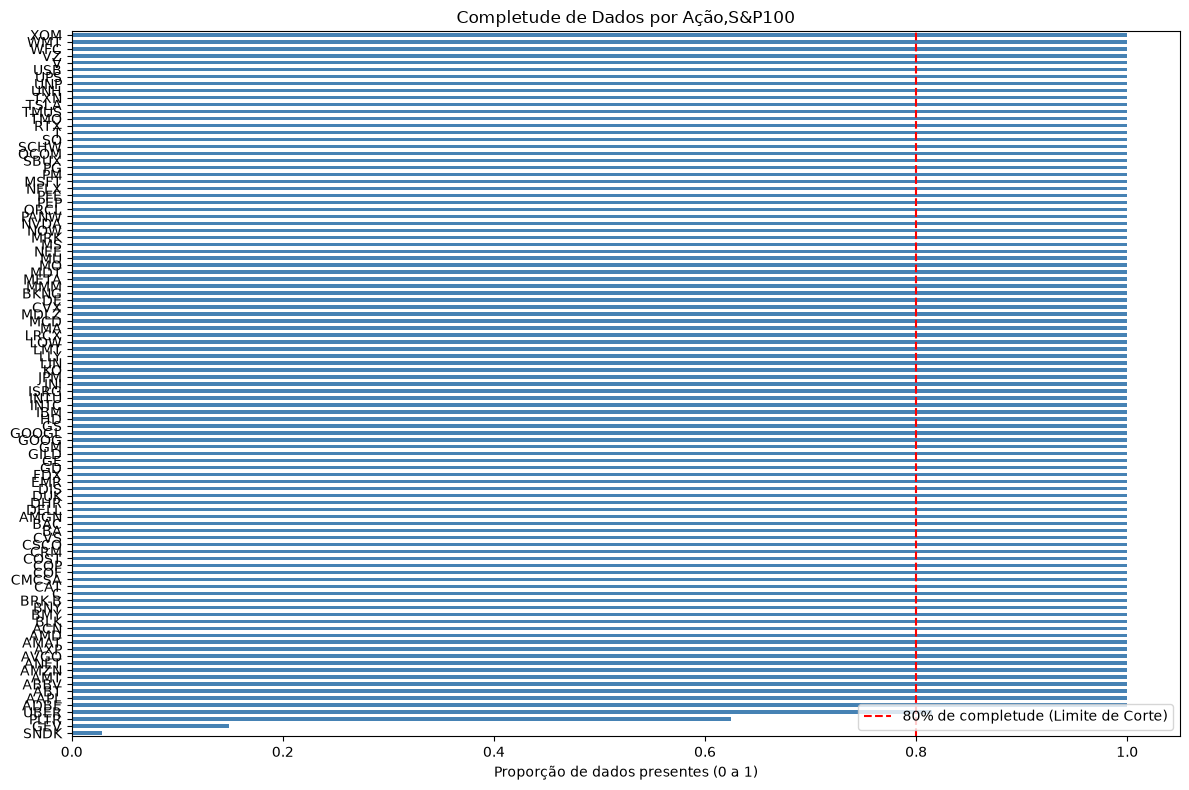

In [13]:
# Visualização de dados faltantes
completude = (1 - pct_nulos_sp/100).sort_values()
plt.figure(figsize=(12, 8))
completude.plot(kind='barh', color='steelblue')
plt.axvline(0.80, color='red', linestyle='--', label='80% de completude (Limite de Corte)')
plt.title('Completude de Dados por Ação,S&P100')
plt.xlabel('Proporção de dados presentes (0 a 1)')
plt.legend()
plt.tight_layout()
plt.savefig('completude_sp100.png', dpi=150)
plt.show()

In [14]:
# no caso,  
#SNDK tem 97.12% dos dados faltantes
#GEV tem 85.12% dos dados faltantes
#PLTR tem 37.51% dos dados faltantes
#UBER tem 18.46% do dados faltantes

# instruções do professor:
# Ação com 1–5% de dados faltantes -> Preencher com o último valor disponível (forward fill)
# Ação com 5–20% de dados faltantes -> Avaliar se incluir,pode distorcer análise de 7 anos
# Ação com >20% de dados faltantes -> Remover do dataset

#SNDK -> Remover do dataset
#GEV -> Remover do dataset
#PLTR -> Remover do dataset
#UBER -> DECISÃO: Mantemos ou tiramos? Mantive! 


In [15]:
# DIAGNÓSTICO DE DADOS FALTANTES,IBOV

# Contagem e percentual de nulos por ação
nulos_ibov = dados_ibov.isnull().sum()
pct_nulos_ib = (nulos_ibov / len(dados_ibov) * 100).round(2)
print('=== DADOS FALTANTES,IBOV ===')
print(f'Total de ações: {dados_ibov.shape[1]}')
print(f'Ações sem nenhum dado faltante: {(pct_nulos_ib == 0).sum()}')
print(f'Ações com algum dado faltante: {(pct_nulos_ib > 0).sum()}')
print(f'\nAções com mais de 5% de dados faltantes:')
print(pct_nulos_ib[pct_nulos_ib > 5].sort_values(ascending=False))

=== DADOS FALTANTES,IBOV ===
Total de ações: 76
Ações sem nenhum dado faltante: 61
Ações com algum dado faltante: 15

Ações com mais de 5% de dados faltantes:
NATU3.SA     74.55
AURE3.SA     57.56
IGTI11.SA    52.83
SMFT3.SA     47.94
CXSE3.SA     45.13
ASAI3.SA     42.83
CMIN3.SA     42.55
VAMO3.SA     41.89
RDOR3.SA     40.24
BRAV3.SA     39.03
CURY3.SA     37.05
CEAB3.SA     25.18
VIVA3.SA     24.24
dtype: float64


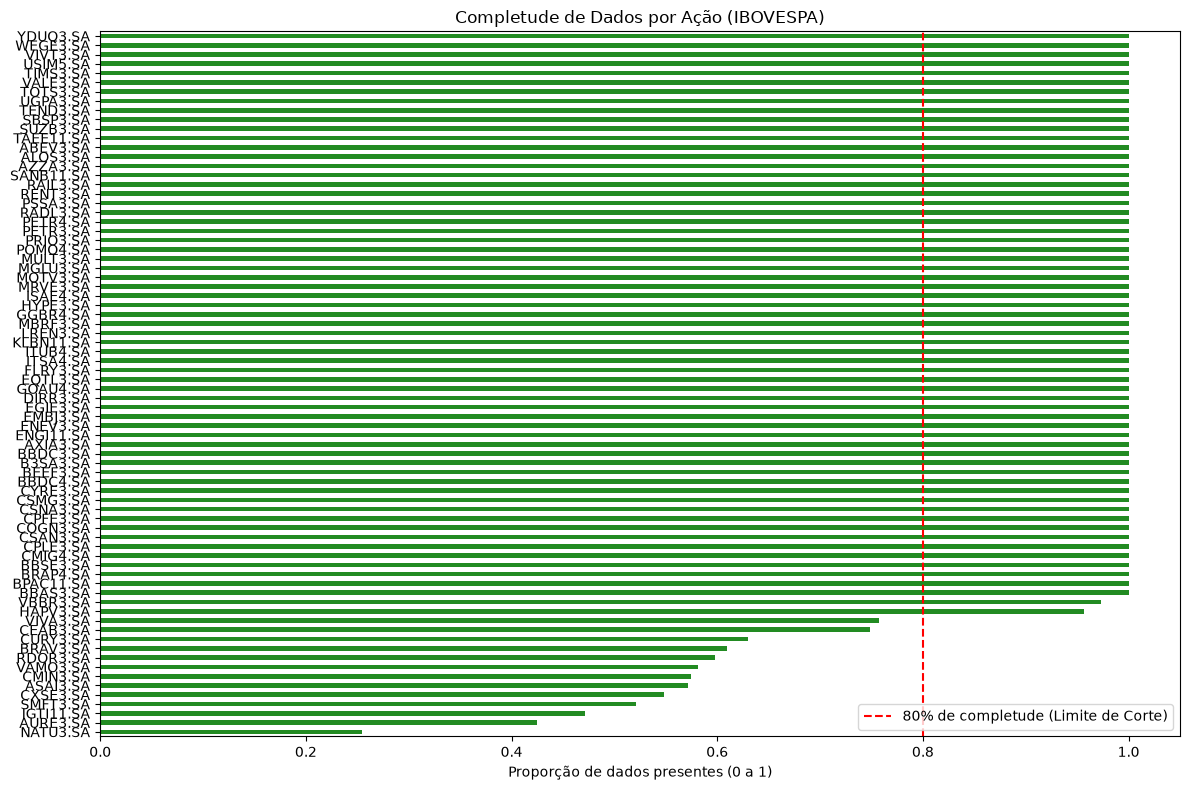

In [16]:
# Visualização de dados faltantes (IBOV)
completude_ib = (1 - pct_nulos_ib/100).sort_values()
plt.figure(figsize=(12, 8))
completude_ib.plot(kind='barh', color='forestgreen')
plt.axvline(0.80, color='red', linestyle='--', label='80% de completude (Limite de Corte)')
plt.title('Completude de Dados por Ação (IBOVESPA)')
plt.xlabel('Proporção de dados presentes (0 a 1)')
plt.legend()
plt.tight_layout()
plt.savefig('completude_ibov.png', dpi=150)
plt.show()

In [17]:
# todas vão ser removidas pois tem mais de 20%

In [18]:
# Passo 1: Remover ações com mais de 20% de dados faltantes
limite_remocao_sp = 5     # S&P: corta UBER (18%), PLTR, GEV, SNDK
limite_remocao_ib = 20
acoes_validas_sp = pct_nulos_sp[pct_nulos_sp <= limite_remocao_sp].index
acoes_validas_ib = [t for t in pct_nulos_ib[pct_nulos_ib <= limite_remocao_ib].index
                    if t != 'UGPA3.SA']   # preço com salto espúrio em 2021-06-28 (dado ruim)

dados_sp100_clean = dados_sp100[acoes_validas_sp].copy().ffill().dropna(how='all')
dados_ibov_clean  = dados_ibov[acoes_validas_ib].copy().ffill().dropna(how='all')

ret_sp100_clean = np.log(dados_sp100_clean / dados_sp100_clean.shift(1)).dropna()
ret_ibov_clean  = np.log(dados_ibov_clean / dados_ibov_clean.shift(1)).dropna()
print(f'S&P100: {dados_sp100.shape[1]} → {dados_sp100_clean.shape[1]} ações | início dos retornos: {ret_sp100_clean.index[0].date()}')
print(f'IBOV:   {dados_ibov.shape[1]} → {dados_ibov_clean.shape[1]} ações | início dos retornos: {ret_ibov_clean.index[0].date()}')

S&P100: 101 → 97 ações | início dos retornos: 2018-01-03
IBOV:   76 → 62 ações | início dos retornos: 2018-04-27


In [19]:
# maior mudança no código em relação ao que o profe passou foi nomear de forma diferente os pct_nulos_ib e pct_nulos_sp
# pois estavam nomeados como pct_ib e pct_nulos respectivamente, então estava causando confusão

In [20]:
# BUSCANDO OUTLIERS
from scipy import stats

In [21]:
# Detectar retornos extremos por ação (S&P 100)

limite_outlier = 0.15 # ±15% em um dia,ajuste conforme necessário
outliers_sp = (ret_sp100_clean.abs() > limite_outlier).sum()
print('Ações com retornos diários > 15% (S&P100):')
print(outliers_sp[outliers_sp > 0].sort_values(ascending=False).head(15))

Ações com retornos diários > 15% (S&P100):
TSLA    14
BA       8
META     7
NVDA     7
ANET     6
AMD      6
DELL     5
AVGO     5
INTC     5
LRCX     5
MU       4
C        4
CVX      4
BAC      4
AXP      4
dtype: int64


In [22]:
# Investigar uma ação específica suspeita
acao_suspeita = 'TSLA' # exemplo
if acao_suspeita in ret_sp100_clean.columns:
 retornos_acao = ret_sp100_clean[acao_suspeita]
 dias_extremos = retornos_acao[retornos_acao.abs() > limite_outlier]
 print(f'\nDias com retorno extremo,{acao_suspeita}:')
 print(dias_extremos.sort_values(key=abs, ascending=False))

# Gráfico de distribuição de retornos vs. curva normal
plt.figure(figsize=(12, 5))


Dias com retorno extremo,TSLA:
Date
2020-09-08   -0.236518
2020-03-16   -0.205522
2025-04-09    0.204491
2024-10-24    0.198187
2020-02-05   -0.188450
2020-02-03    0.181445
2021-03-09    0.179327
2020-03-18   -0.174763
2020-03-19    0.168795
2025-03-10   -0.167546
2019-10-24    0.162707
2018-10-01    0.159966
2020-03-24    0.150846
2018-08-02    0.150039
Name: TSLA, dtype: float64


<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

In [23]:
# Detectar retornos extremos por ação (IBOV)
limite_outlier_ib = 0.15 # ±15% em um dia
outliers_ib = (ret_ibov_clean.abs() > limite_outlier_ib).sum()
print('\nAções com retornos diários > 15% (IBOVESPA):')
print(outliers_ib[outliers_ib > 0].sort_values(ascending=False).head(15))


Ações com retornos diários > 15% (IBOVESPA):
PRIO3.SA     13
TEND3.SA     12
MGLU3.SA     11
HAPV3.SA      9
PETR3.SA      9
COGN3.SA      8
AXIA3.SA      8
BPAC11.SA     8
YDUQ3.SA      7
PETR4.SA      7
EMBJ3.SA      7
CSNA3.SA      6
USIM5.SA      6
CYRE3.SA      5
ALOS3.SA      5
dtype: int64


Top 10 Candidatas Puras para Tracking (S&P 100):
       Correlação      Beta
MSFT     0.855800  1.202568
AAPL     0.814747  1.237624
BLK      0.790928  1.143729
GOOGL    0.782139  1.178033
GOOG     0.781421  1.174654
V        0.768714  0.981127
MA       0.768137  1.089994
INTU     0.762077  1.286249
ACN      0.756492  0.999325
BRK-B    0.754004  0.774044


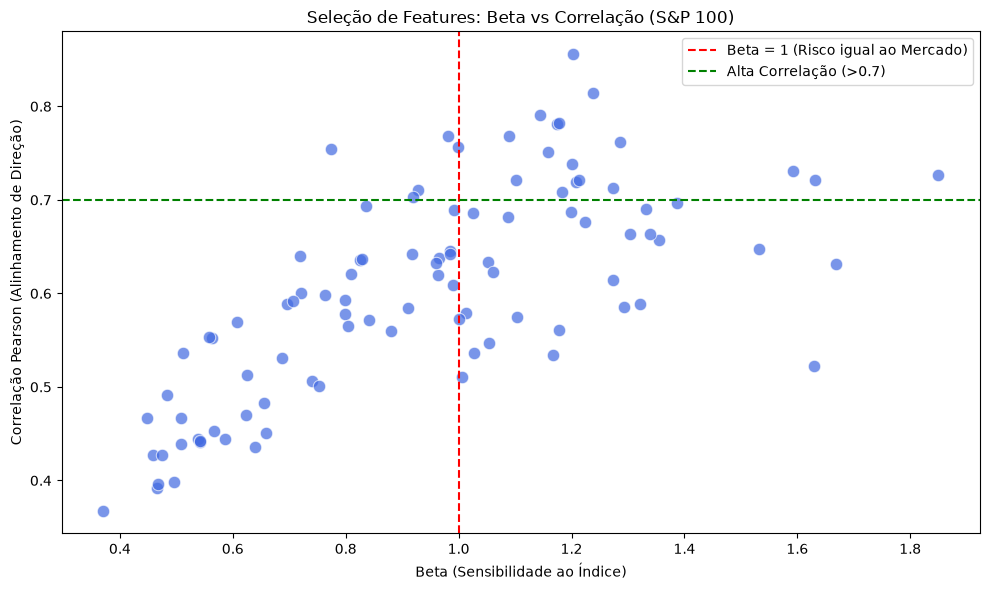

In [24]:
# 1. Calcular a Variância do Índice S&P 100
var_idx_sp = ret_idx_sp.var()

# 2. Calcular Correlação e Beta para cada ação contra o índice
correlacoes = ret_sp100_clean.corrwith(ret_idx_sp)
betas = ret_sp100_clean.apply(lambda col: col.cov(ret_idx_sp) / var_idx_sp)

# 3. Consolidar os resultados
analise_sp = pd.DataFrame({'Correlação': correlacoes, 'Beta': betas})

# 4. Mostrar o Top 10 das melhores candidatas (Correlação alta e Beta próximo a 1)
analise_sp['Distancia_Beta_1'] = abs(1 - analise_sp['Beta'])
top10_candidatas = analise_sp.sort_values(by=['Correlação', 'Distancia_Beta_1'], ascending=[False, True]).head(10)
print("Top 10 Candidatas Puras para Tracking (S&P 100):")
print(top10_candidatas[['Correlação', 'Beta']])

# 5. Gráfico de Dispersão: Correlação vs Beta
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Beta', y='Correlação', data=analise_sp, color='royalblue', s=80, alpha=0.7)

# Adicionar linhas de referência (O "Alvo" de um bom rastreador)
plt.axvline(1.0, color='red', linestyle='--', label='Beta = 1 (Risco igual ao Mercado)')
plt.axhline(0.7, color='green', linestyle='--', label='Alta Correlação (>0.7)')

plt.title('Seleção de Features: Beta vs Correlação (S&P 100)')
plt.xlabel('Beta (Sensibilidade ao Índice)')
plt.ylabel('Correlação Pearson (Alinhamento de Direção)')
plt.legend()
plt.tight_layout()
plt.savefig('selecao_features_sp100.png', dpi=150)
plt.show()


Top 10 Candidatas Puras para Tracking (IBOVESPA):
           Correlação      Beta
ITSA4.SA     0.803923  0.944450
BBDC3.SA     0.792924  1.133456
BBAS3.SA     0.786077  1.191798
BBDC4.SA     0.769414  1.136154
ITUB4.SA     0.760714  0.973486
SANB11.SA    0.747751  1.043149
CYRE3.SA     0.732697  1.479825
B3SA3.SA     0.731927  1.215439
PETR4.SA     0.727638  1.347398
PETR3.SA     0.726298  1.369641


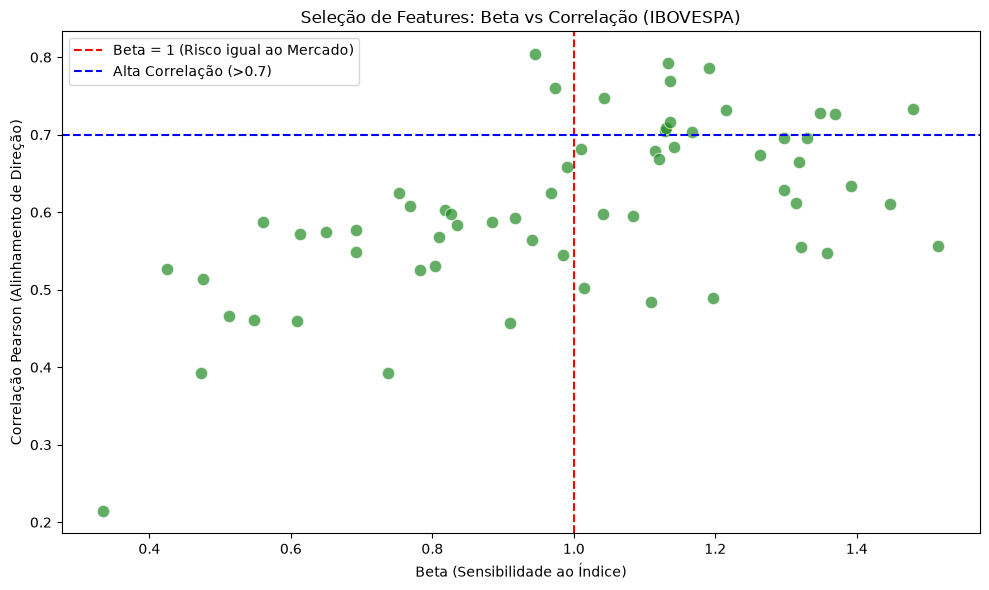

In [25]:
# 1. Calcular a Variância do Índice IBOVESPA
var_idx_ib = ret_idx_ib.var()

# 2. Calcular Correlação e Beta para cada ação contra o índice
correlacoes_ib = ret_ibov_clean.corrwith(ret_idx_ib)
betas_ib = ret_ibov_clean.apply(lambda col: col.cov(ret_idx_ib) / var_idx_ib)

# 3. Consolidar os resultados
analise_ib = pd.DataFrame({'Correlação': correlacoes_ib, 'Beta': betas_ib})
analise_ib['Distancia_Beta_1'] = abs(1 - analise_ib['Beta'])

# 4. Mostrar o Top 10 das melhores candidatas (Correlação alta e Beta próximo a 1)
top10_candidatas_ib = analise_ib.sort_values(by=['Correlação', 'Distancia_Beta_1'], ascending=[False, True]).head(10)
print("\nTop 10 Candidatas Puras para Tracking (IBOVESPA):")
print(top10_candidatas_ib[['Correlação', 'Beta']])

# 5. Gráfico de Dispersão: Correlação vs Beta
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Beta', y='Correlação', data=analise_ib, color='forestgreen', s=80, alpha=0.7)

# Adicionar linhas de referência
plt.axvline(1.0, color='red', linestyle='--', label='Beta = 1 (Risco igual ao Mercado)')
plt.axhline(0.7, color='blue', linestyle='--', label='Alta Correlação (>0.7)')

plt.title('Seleção de Features: Beta vs Correlação (IBOVESPA)')
plt.xlabel('Beta (Sensibilidade ao Índice)')
plt.ylabel('Correlação Pearson (Alinhamento de Direção)')
plt.legend()
plt.tight_layout()
plt.savefig('selecao_features_ibov.png', dpi=150)
plt.show()

In [26]:
# Definir o limite de 15% (0.15 em retornos logarítmicos/decimais)
LIMITE_OUTLIER = 0.15

# =============================================================
# 1. ISOLAR E MAPEAR (Extrair relatório de outliers)
# =============================================================
mascara_sp = ret_sp100_clean.abs() > LIMITE_OUTLIER
mascara_ib = ret_ibov_clean.abs() > LIMITE_OUTLIER

# Tabela consolidada com todas as ocorrências acima de ±15%
outliers_sp_df = ret_sp100_clean[mascara_sp].stack().reset_index()
outliers_sp_df.columns = ['Data', 'Ticker', 'Retorno_Log']

outliers_ib_df = ret_ibov_clean[mascara_ib].stack().reset_index()
outliers_ib_df.columns = ['Data', 'Ticker', 'Retorno_Log']

print(f"Ocorrências > 15% no S&P 100: {len(outliers_sp_df)}")
print(f"Ocorrências > 15% no IBOVESPA: {len(outliers_ib_df)}")

# Visualizar as maiores discrepâncias isoladas
print("\nTop 5 maiores movimentos isolados (S&P 100):")
print(outliers_sp_df.sort_values(by='Retorno_Log', key=abs, ascending=False).head())

# =============================================================
# 2. FIXAR/TRATAR OS OUTLIERS (Capping entre -15% e +15%)
# =============================================================
# Aplica o limite máximo (+15%) e mínimo (-15%) sem apagar as linhas
ret_sp100_trata = ret_sp100_clean.clip(lower=-LIMITE_OUTLIER, upper=LIMITE_OUTLIER)
ret_ibov_trata = ret_ibov_clean.clip(lower=-LIMITE_OUTLIER, upper=LIMITE_OUTLIER)

print("\nTratamento por Capping (+15% / -15%) concluído!")

Ocorrências > 15% no S&P 100: 178577
Ocorrências > 15% no IBOVESPA: 107818

Top 5 maiores movimentos isolados (S&P 100):
             Data Ticker  Retorno_Log
104926 2022-04-20   NFLX    -0.432578
149647 2024-02-21   PANW    -0.334649
99874  2022-02-03   META    -0.306391
160581 2024-08-02   INTC    -0.301896
53083  2020-03-09    COP    -0.285552

Tratamento por Capping (+15% / -15%) concluído!


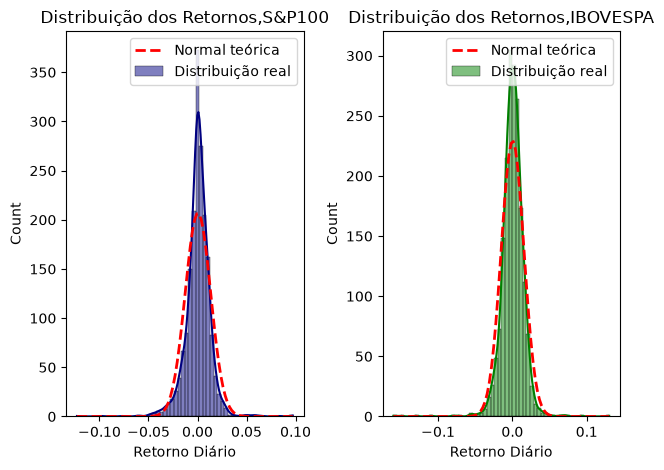


Curtose S&P100: 12.49 (normal = 0)
Curtose IBOV: 20.17 (normal = 0)
Valores positivos = caudas gordas (fat tails),comum em finanças


In [27]:
# Retornos do índice S&P100
plt.subplot(1, 2, 1)
sns.histplot(ret_idx_sp, bins=60, kde=True, color='navy', label='Distribuição real')
# Adicionar curva normal teórica
mu, sigma = ret_idx_sp.mean(), ret_idx_sp.std()
x = np.linspace(ret_idx_sp.min(), ret_idx_sp.max(), 100)
plt.plot(x, stats.norm.pdf(x, mu, sigma) * len(ret_idx_sp) * (ret_idx_sp.max()-ret_idx_sp.min())/60,
'r--', lw=2, label='Normal teórica')
plt.title('Distribuição dos Retornos,S&P100')
plt.xlabel('Retorno Diário')
plt.legend()

plt.subplot(1, 2, 2)
sns.histplot(ret_idx_ib, bins=60, kde=True, color='green', label='Distribuição real')
mu2, sigma2 = ret_idx_ib.mean(), ret_idx_ib.std()
x2 = np.linspace(ret_idx_ib.min(), ret_idx_ib.max(), 100)
plt.plot(x2, stats.norm.pdf(x2, mu2, sigma2) * len(ret_idx_ib) * (ret_idx_ib.max()-ret_idx_ib.min())/60,
'r--', lw=2, label='Normal teórica')
plt.title('Distribuição dos Retornos,IBOVESPA')
plt.xlabel('Retorno Diário')
plt.legend()

plt.tight_layout()
plt.savefig('distribuicao_retornos.png', dpi=150)
plt.show()

# O que observar: as caudas são mais pesadas que a normal? (fat tails = sim!)
print(f'\nCurtose S&P100: {ret_idx_sp.kurtosis():.2f} (normal = 0)')
print(f'Curtose IBOV: {ret_idx_ib.kurtosis():.2f} (normal = 0)')
print('Valores positivos = caudas gordas (fat tails),comum em finanças')


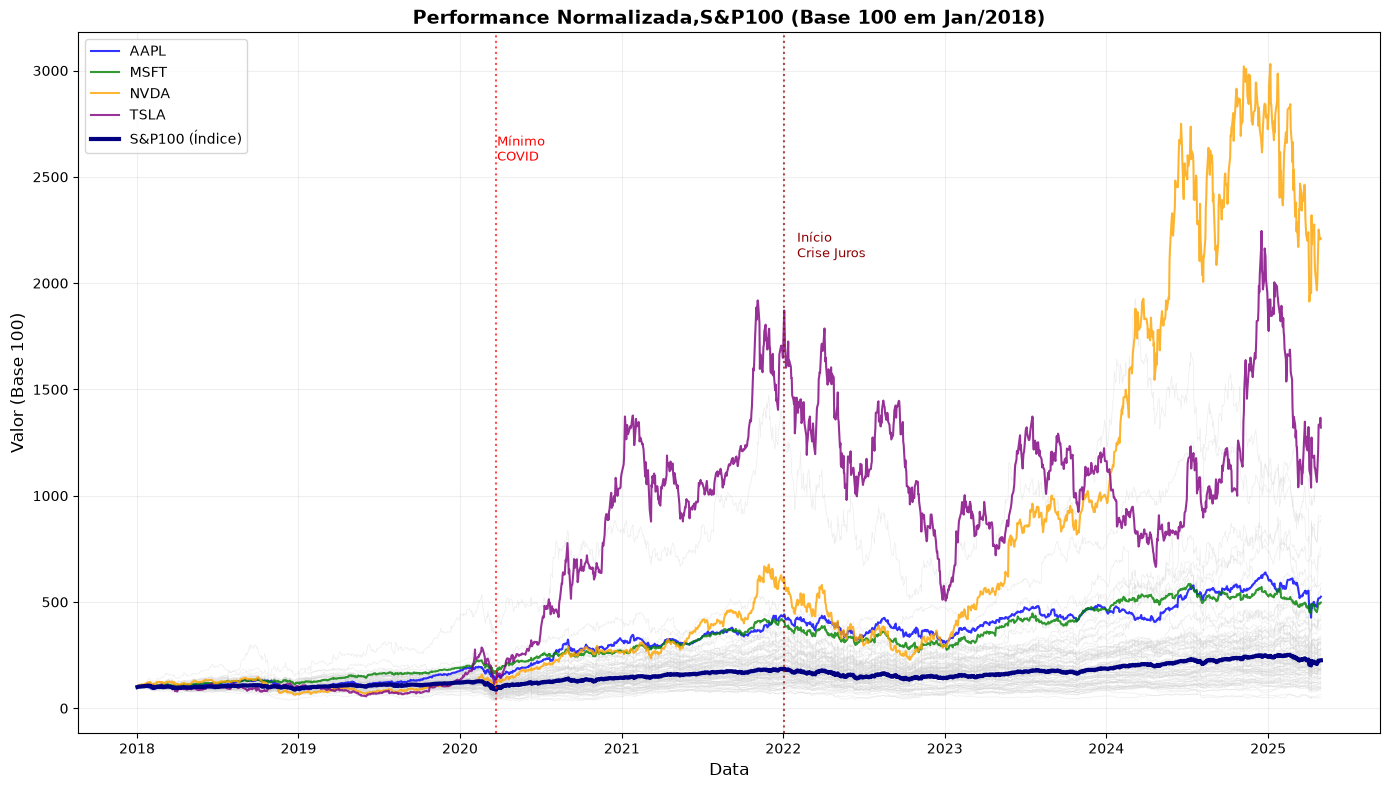

In [28]:
# Performance normalizada: todos começam em 100 no início do período ---------- SP100 -------
precos_norm_sp = (dados_sp100_clean / dados_sp100_clean.iloc[0] * 100)
indice_norm_sp = (indice_sp100 / indice_sp100.iloc[0] * 100)
plt.figure(figsize=(14, 8))

# Ações individuais em cinza claro (fundo)
for col in precos_norm_sp.columns:
 plt.plot(precos_norm_sp.index, precos_norm_sp[col],
  color='lightgray', linewidth=0.5, alpha=0.4)
    
# Destacar algumas ações relevantes
destaques = ['AAPL', 'MSFT', 'NVDA', 'TSLA']
cores_dest = ['blue', 'green', 'orange', 'purple']
for acao, cor in zip(destaques, cores_dest):
 if acao in precos_norm_sp.columns:
  plt.plot(precos_norm_sp.index, precos_norm_sp[acao],
  color=cor, linewidth=1.5, label=acao, alpha=0.8)
     
# Índice em destaque total
plt.plot(indice_norm_sp.index, indice_norm_sp,
 color='navy', linewidth=3, label='S&P100 (Índice)')

# Marcar eventos importantes
plt.axvline(pd.Timestamp('2020-03-23'), color='red', linestyle=':', linewidth=1.5, alpha=0.7)
plt.text(pd.Timestamp('2020-03-25'), precos_norm_sp.max().max()*0.85, 'Mínimo\nCOVID',
          color='red', fontsize=9)

plt.axvline(pd.Timestamp('2022-01-03'), color='darkred', linestyle=':', linewidth=1.5, alpha=0.7)
plt.text(pd.Timestamp('2022-02-01'), precos_norm_sp.max().max()*0.70, 'Início\nCrise Juros',
          color='darkred', fontsize=9)

plt.title('Performance Normalizada,S&P100 (Base 100 em Jan/2018)',
 fontsize=14, fontweight='bold')
plt.ylabel('Valor (Base 100)', fontsize=12)
plt.xlabel('Data', fontsize=12)
plt.legend(fontsize=10, loc='upper left')
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig('performance_normalizada_sp100.png', dpi=150)
plt.show()

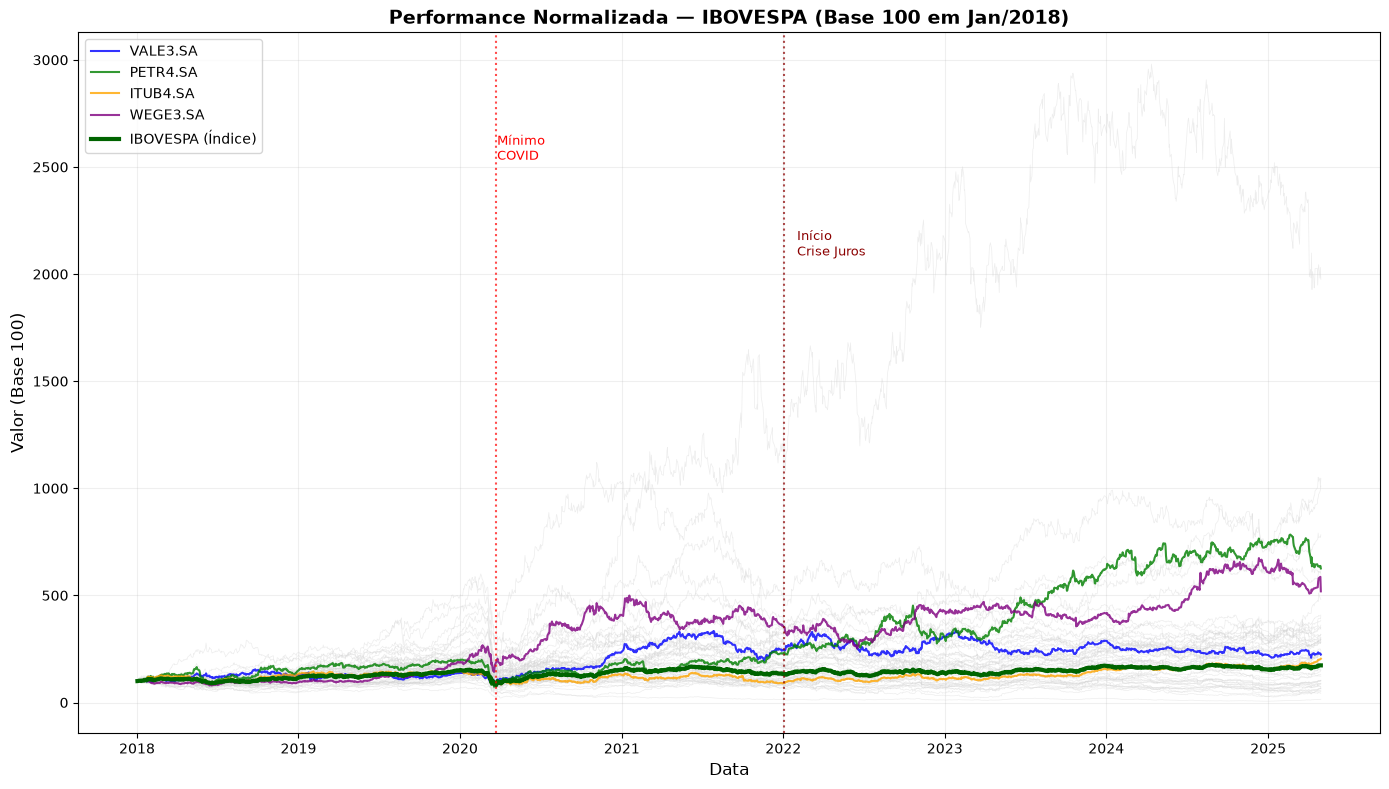

In [29]:
# Performance normalizada: todos começam em 100 no início do período
precos_norm_ib = (dados_ibov_clean / dados_ibov_clean.iloc[0] * 100)
indice_norm_ib = (indice_ibov / indice_ibov.iloc[0] * 100)

plt.figure(figsize=(14, 8))

# Ações individuais em cinza claro (fundo)
for col in precos_norm_ib.columns:
    plt.plot(precos_norm_ib.index, precos_norm_ib[col],
              color='lightgray', linewidth=0.5, alpha=0.4)

# Destacar algumas ações relevantes do IBOV
destaques_ib = ['VALE3.SA', 'PETR4.SA', 'ITUB4.SA', 'WEGE3.SA']
cores_dest_ib = ['blue', 'green', 'orange', 'purple']
for acao, cor in zip(destaques_ib, cores_dest_ib):
    if acao in precos_norm_ib.columns:
        plt.plot(precos_norm_ib.index, precos_norm_ib[acao],
                  color=cor, linewidth=1.5, label=acao, alpha=0.8)

# Índice em destaque total
plt.plot(indice_norm_ib.index, indice_norm_ib,
          color='darkgreen', linewidth=3, label='IBOVESPA (Índice)')

# Marcar eventos importantes
plt.axvline(pd.Timestamp('2020-03-23'), color='red', linestyle=':', linewidth=1.5, alpha=0.7)
plt.text(pd.Timestamp('2020-03-25'), precos_norm_ib.max().max()*0.85, 'Mínimo\nCOVID',
          color='red', fontsize=9)
plt.axvline(pd.Timestamp('2022-01-03'), color='darkred', linestyle=':', linewidth=1.5, alpha=0.7)
plt.text(pd.Timestamp('2022-02-01'), precos_norm_ib.max().max()*0.70, 'Início\nCrise Juros',
          color='darkred', fontsize=9)

plt.title('Performance Normalizada — IBOVESPA (Base 100 em Jan/2018)',
          fontsize=14, fontweight='bold')
plt.ylabel('Valor (Base 100)', fontsize=12)
plt.xlabel('Data', fontsize=12)
plt.legend(fontsize=10, loc='upper left')
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig('performance_normalizada_ibov.png', dpi=150)
plt.show()

TOP 10,Maior Retorno Anualizado (S&P100):
NVDA    42.3704
TSLA    35.3231
LLY     33.8921
AVGO    30.1583
AMD     29.8709
PANW    27.6717
NOW     27.1159
COST    24.2261
ANET    23.8181
NFLX    23.6511
Name: Retorno médio anualizado (%), dtype: float64

TOP 10,Menor Volatilidade Anualizada (S&P100):
KO       19.7381
JNJ      19.8369
PG       20.2986
VZ       20.8379
PEP      20.8745
MDLZ     21.0889
BRK-B    21.2184
MCD      22.0743
DUK      22.2273
WMT      22.4530
Name: Volatilidade anualizada (%), dtype: float64

TOP 10,Melhor Sharpe Aproximado (S&P100):
LLY     1.1214
COST    1.0439
NVDA    0.8051
MSFT    0.7560
WMT     0.7353
AVGO    0.7327
AAPL    0.7229
TMUS    0.7025
PANW    0.6998
NOW     0.6500
Name: Sharpe aprox. anualizado, dtype: float64


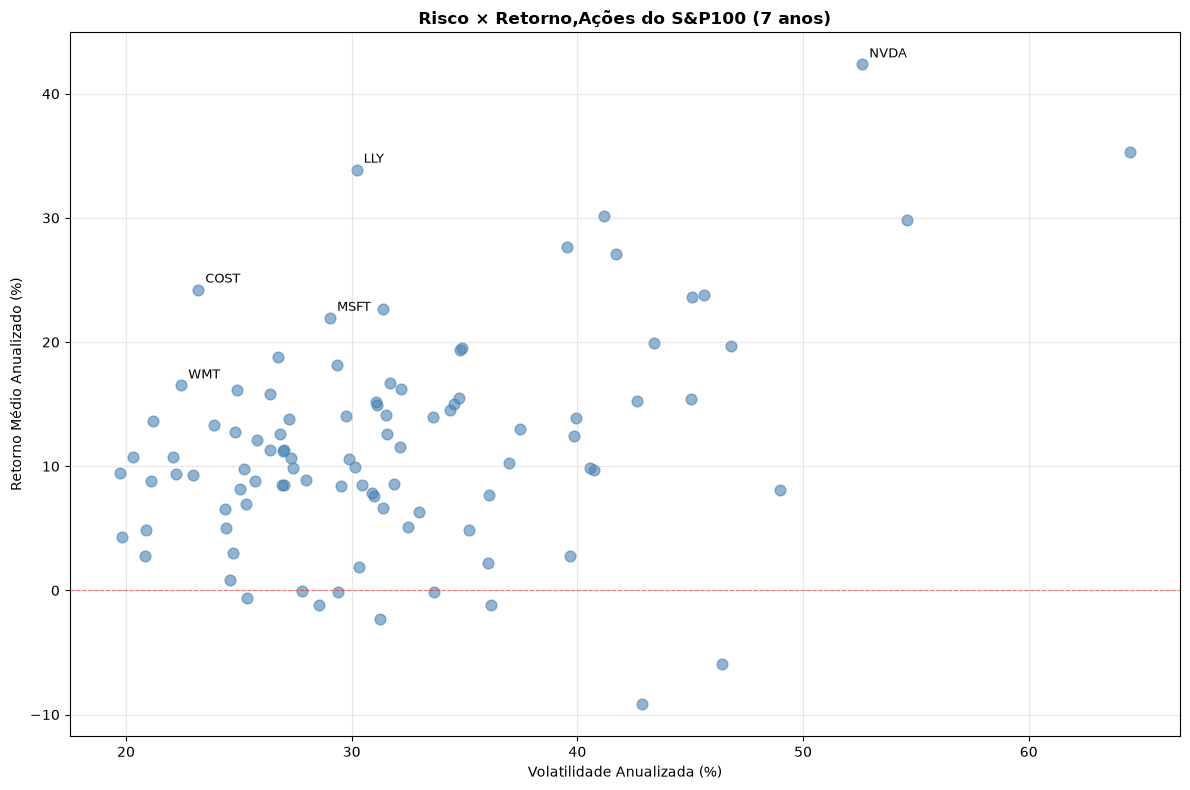

In [30]:
#5.2 ------------ SP100 --------------------
# Estatísticas completas dos retornos,por ação
stats = pd.DataFrame({
'Retorno médio diário (%)': ret_sp100_clean.mean() * 100,
'Retorno médio anualizado (%)': ret_sp100_clean.mean() * 252 * 100,
'Volatilidade diária (%)': ret_sp100_clean.std() * 100,
'Volatilidade anualizada (%)': ret_sp100_clean.std() * np.sqrt(252) * 100,
'Sharpe aprox. anualizado': (
ret_sp100_clean.mean() / ret_sp100_clean.std() * np.sqrt(252)),
'Retorno mínimo diário (%)': ret_sp100_clean.min() * 100,
'Retorno máximo diário (%)': ret_sp100_clean.max() * 100,
'Assimetria (skewness)': ret_sp100_clean.skew(),
'Curtose (kurtosis)': ret_sp100_clean.kurtosis(),
'Dias negociados': ret_sp100_clean.count(),
}).round(4)

# Top 10 maior retorno médio anualizado
print('TOP 10,Maior Retorno Anualizado (S&P100):')
print(stats['Retorno médio anualizado (%)'].sort_values(ascending=False).head(10))

# Top 10 menor volatilidade (mais estáveis)
print('\nTOP 10,Menor Volatilidade Anualizada (S&P100):')
print(stats['Volatilidade anualizada (%)'].sort_values().head(10))

# Top 10 melhor Sharpe (melhor retorno ajustado por risco)
print('\nTOP 10,Melhor Sharpe Aproximado (S&P100):')
print(stats['Sharpe aprox. anualizado'].sort_values(ascending=False).head(10))
# Gráfico risco vs. retorno (Fronteira de dispersão)
plt.figure(figsize=(12, 8))
plt.scatter(stats['Volatilidade anualizada (%)'],
stats['Retorno médio anualizado (%)'],
alpha=0.6, s=60, color='steelblue')

# Anotar algumas ações de destaque
top_acoes = stats['Sharpe aprox. anualizado'].sort_values(ascending=False).head(5).index
for acao in top_acoes:
    plt.annotate(acao,
        (stats.loc[acao, 'Volatilidade anualizada (%)'],
        stats.loc[acao, 'Retorno médio anualizado (%)']),
        textcoords='offset points', xytext=(5,5), fontsize=9)
    
plt.axhline(0, color='red', linestyle='--', linewidth=0.8, alpha=0.5)
plt.title('Risco × Retorno,Ações do S&P100 (7 anos)', fontweight='bold')
plt.xlabel('Volatilidade Anualizada (%)')
plt.ylabel('Retorno Médio Anualizado (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('risco_retorno_sp100.png', dpi=150)
plt.show()



In [31]:
#5.2 ---------IBOV -------------

TOP 15 — Ações mais correlacionadas com o IBOV:
ITSA4.SA     0.8039
BBDC3.SA     0.7929
BBAS3.SA     0.7861
BBDC4.SA     0.7694
ITUB4.SA     0.7607
SANB11.SA    0.7478
CYRE3.SA     0.7327
B3SA3.SA     0.7319
PETR4.SA     0.7276
PETR3.SA     0.7263
MULT3.SA     0.7170
MOTV3.SA     0.7092
CSAN3.SA     0.7054
GOAU4.SA     0.7030
BPAC11.SA    0.6959
dtype: float64

BOTTOM 10 — Ações menos correlacionadas com o IBOV:
EMBJ3.SA     0.5026
TEND3.SA     0.4889
HAPV3.SA     0.4837
VIVT3.SA     0.4658
PSSA3.SA     0.4608
RADL3.SA     0.4596
MBRF3.SA     0.4566
BEEF3.SA     0.3923
KLBN11.SA    0.3921
SUZB3.SA     0.2149
dtype: float64


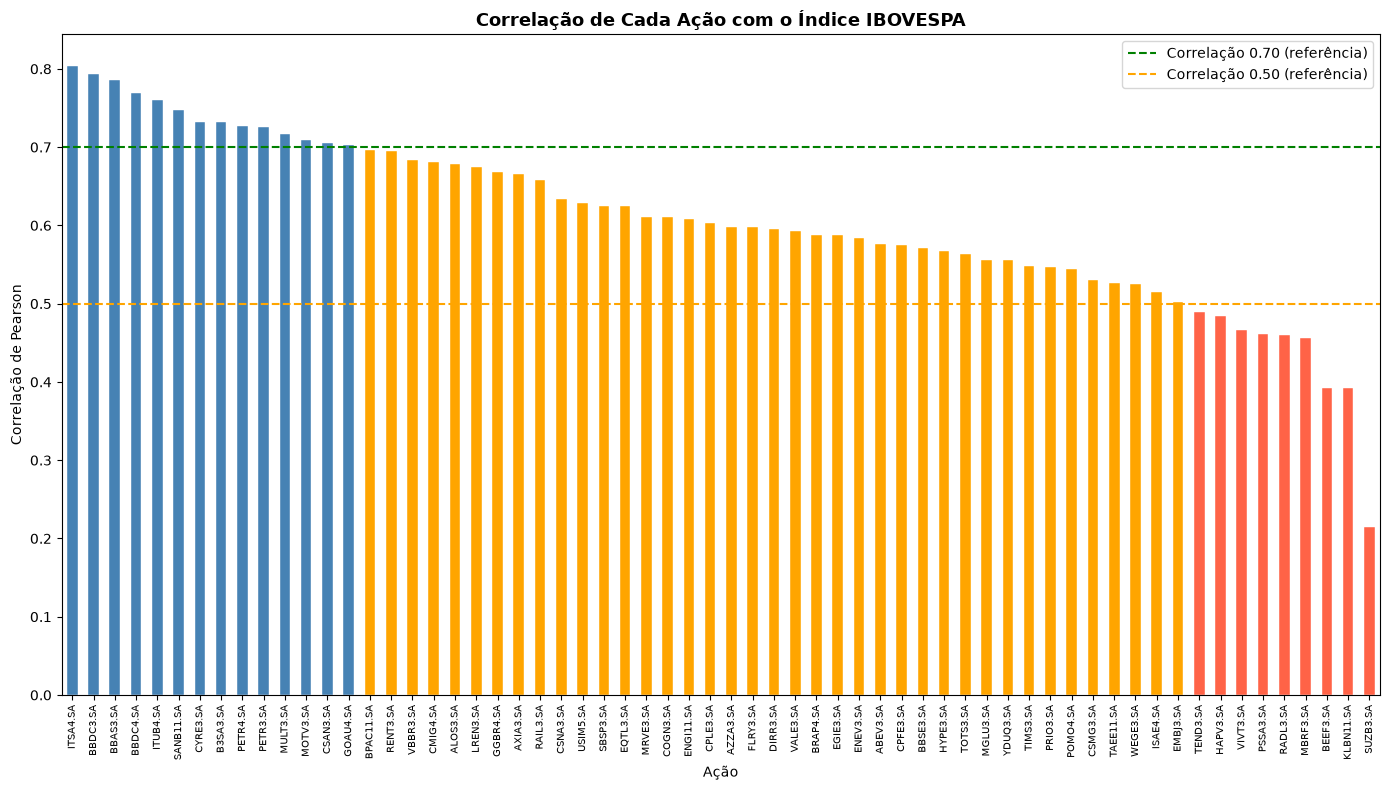


22.6% das ações têm correlação > 0.7 com o índice


In [32]:
# Correlação de cada ação com o índice
# Alinhar os índices de data primeiro
datas_comuns_ib = ret_ibov_clean.index.intersection(ret_idx_ib.index)
ret_acoes_al_ib = ret_ibov_clean.loc[datas_comuns_ib]
ret_idx_al_ib = ret_idx_ib.loc[datas_comuns_ib]

# Calcular correlação de cada ação com o índice
corr_com_idx_ib = ret_acoes_al_ib.corrwith(ret_idx_al_ib).sort_values(ascending=False)

print('TOP 15 — Ações mais correlacionadas com o IBOV:')
print(corr_com_idx_ib.head(15).round(4))
print('\nBOTTOM 10 — Ações menos correlacionadas com o IBOV:')
print(corr_com_idx_ib.tail(10).round(4))

# Gráfico de correlação com o índice
plt.figure(figsize=(14, 8))
cores_ib = ['steelblue' if c > 0.7 else ('orange' if c > 0.5 else 'tomato')
            for c in corr_com_idx_ib.values]
corr_com_idx_ib.plot(kind='bar', color=cores_ib, edgecolor='white', linewidth=0.3)
plt.axhline(0.7, color='green', linestyle='--', linewidth=1.5,
            label='Correlação 0.70 (referência)')
plt.axhline(0.5, color='orange', linestyle='--', linewidth=1.5,
            label='Correlação 0.50 (referência)')
plt.title('Correlação de Cada Ação com o Índice IBOVESPA', fontweight='bold', fontsize=13)
plt.xlabel('Ação')
plt.ylabel('Correlação de Pearson')
plt.xticks(rotation=90, fontsize=7)
plt.legend()
plt.tight_layout()
plt.savefig('correlacao_com_indice_ibov.png', dpi=150)
plt.show()

# Quantos % das ações têm correlação > 0.7?
pct_alta_corr_ib = (corr_com_idx_ib > 0.7).mean() * 100
print(f'\n{pct_alta_corr_ib:.1f}% das ações têm correlação > 0.7 com o índice')

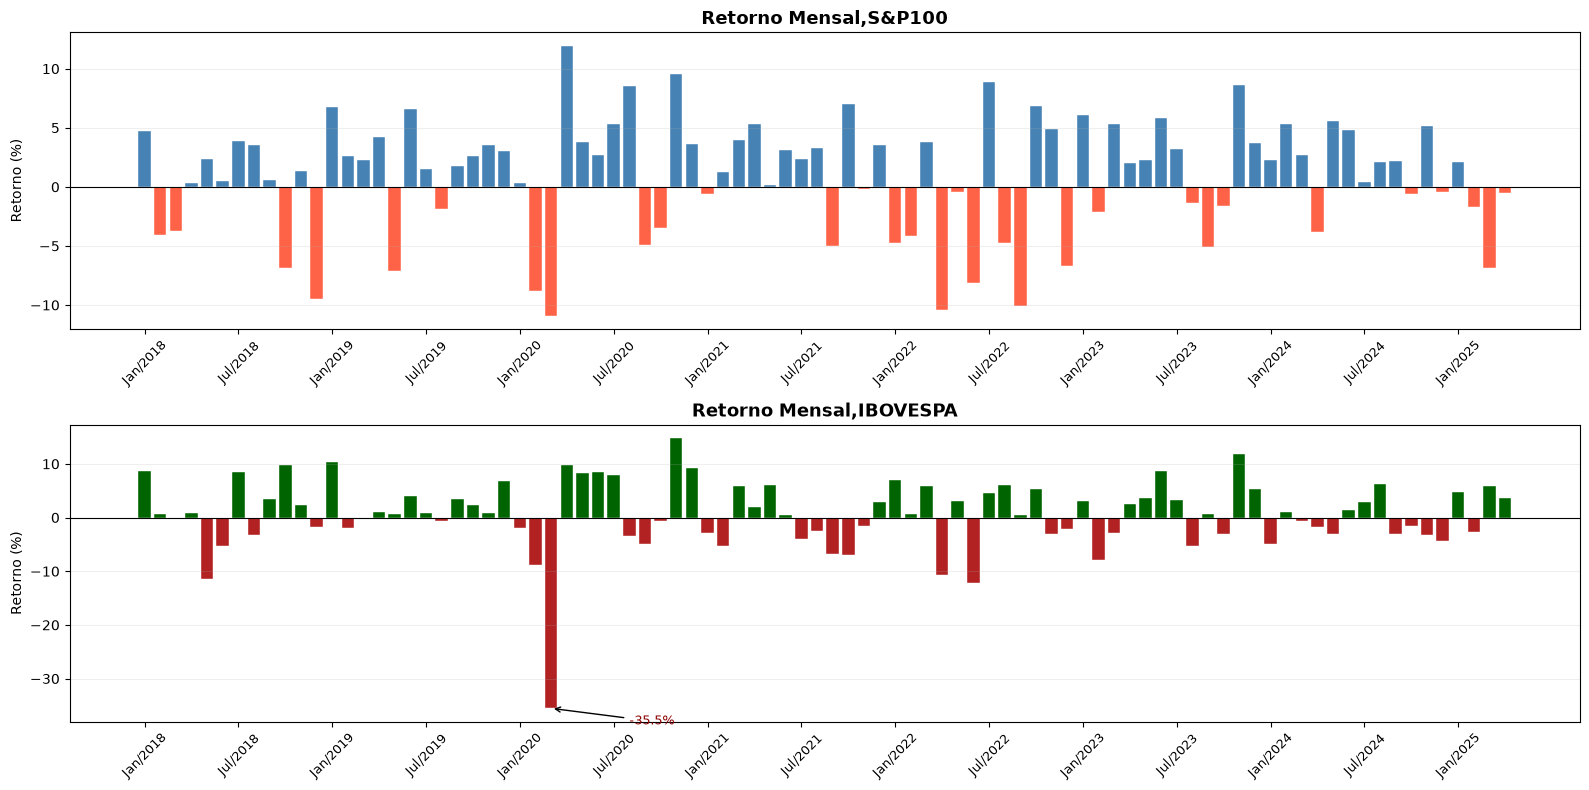


Retorno anual S&P100:
Date
2018-12-31    -8.14
2019-12-31    28.40
2020-12-31    12.43
2021-12-31    26.41
2022-12-31   -24.53
2023-12-31    29.62
2024-12-31    28.00
2025-12-31    -8.07
Freq: YE-DEC, Name: ^OEX, dtype: float64

Retorno anual IBOVESPA:
Date
2018-12-31    10.19
2019-12-31    29.84
2020-12-31    -7.33
2021-12-31   -14.03
2022-12-31     2.69
2023-12-31    20.18
2024-12-31   -11.10
2025-12-31    11.72
Freq: YE-DEC, Name: ^BVSP, dtype: float64


In [33]:
#5.3 -------------- SP100 + IBOV ----------------
# Retorno mensal do índice
ret_mensal_sp = ret_idx_sp.resample('ME').sum() # soma dos retornos diários do mês
ret_mensal_ib = ret_idx_ib.resample('ME').sum()
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
for ax, ret, titulo, cor_pos, cor_neg in [
    (axes[0], ret_mensal_sp, 'S&P100', 'steelblue', 'tomato'),
    (axes[1], ret_mensal_ib, 'IBOVESPA', 'darkgreen', 'firebrick'),
]:
    cores = [cor_pos if r > 0 else cor_neg for r in ret.values]
    ax.bar(range(len(ret)), ret.values * 100, color=cores, edgecolor='white', linewidth=0.3)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'Retorno Mensal,{titulo}', fontweight='bold', fontsize=13)
    ax.set_ylabel('Retorno (%)')
    ax.set_xticks(range(0, len(ret), 6))
    ax.set_xticklabels(ret.index[::6].strftime('%b/%Y'), rotation=45, fontsize=9)
    ax.grid(True, alpha=0.2, axis='y')

# Anotar o pior mês
pior_idx = ret.values.argmin()
pior_val = ret.values[pior_idx] * 100
ax.annotate(f'{pior_val:.1f}%',
xy=(pior_idx, pior_val), xytext=(pior_idx+5, pior_val-3),
arrowprops=dict(arrowstyle='->', color='black'),
fontsize=9, color='darkred')
plt.tight_layout()
plt.savefig('retorno_mensal_indices.png', dpi=150)
plt.show()

# Retorno acumulado por ano
ret_anual_sp = (1 + ret_idx_sp).resample('YE').prod() - 1
ret_anual_ib = (1 + ret_idx_ib).resample('YE').prod() - 1
print('\nRetorno anual S&P100:')
print((ret_anual_sp * 100).round(2))
print('\nRetorno anual IBOVESPA:')
print((ret_anual_ib * 100).round(2))

TOP 15 — Ações mais correlacionadas com o S&P100:
MSFT     0.8558
AAPL     0.8147
BLK      0.7909
GOOGL    0.7821
GOOG     0.7814
V        0.7687
MA       0.7681
INTU     0.7621
ACN      0.7565
BRK-B    0.7540
TXN      0.7512
MS       0.7389
AMAT     0.7305
NVDA     0.7265
GS       0.7215
dtype: float64

BOTTOM 10 — Ações menos correlacionadas com o S&P100:
T       0.4424
PFE     0.4416
SO      0.4385
CVS     0.4359
DUK     0.4268
MRK     0.4268
GILD    0.3980
MO      0.3961
BMY     0.3916
VZ      0.3677
dtype: float64


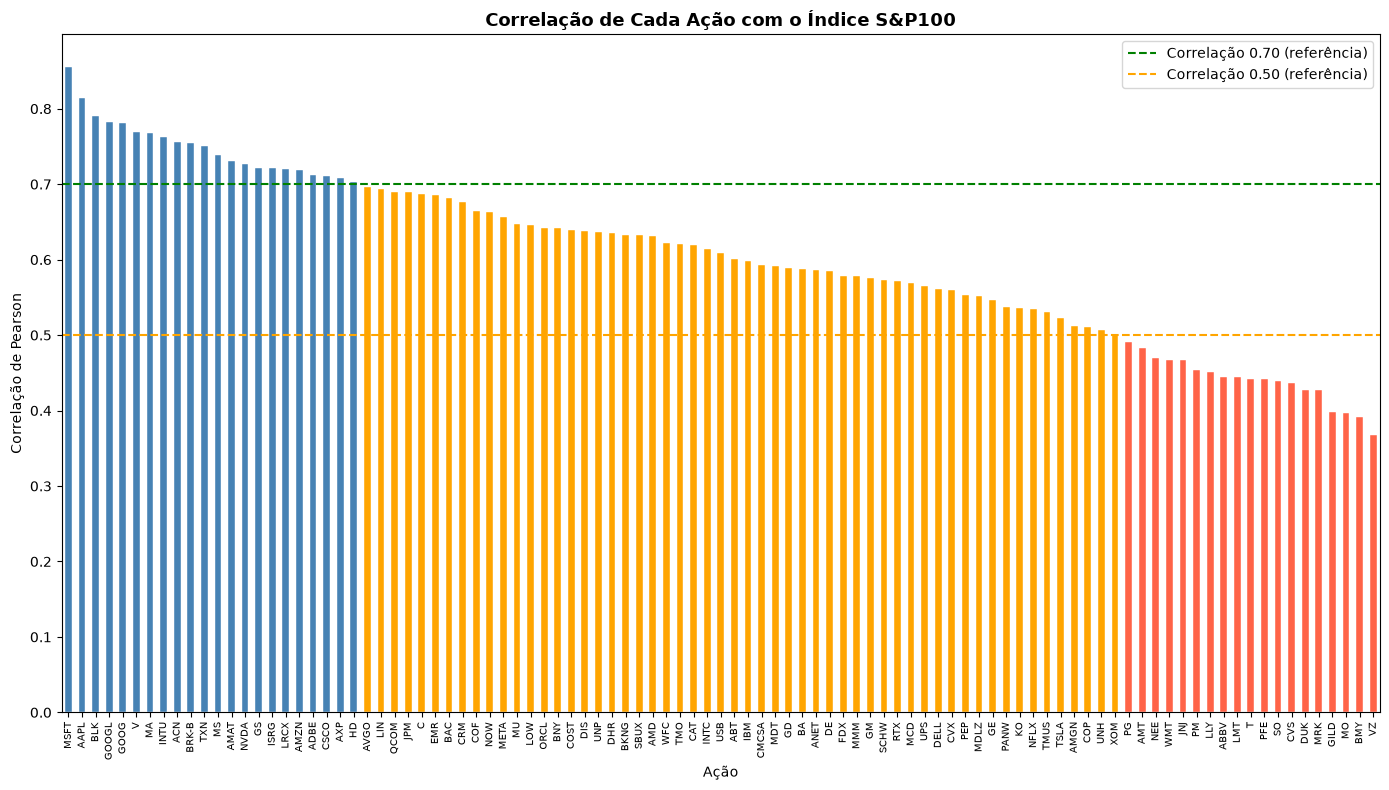


22.7% das ações têm correlação > 0.7 com o índice


In [34]:
# 5.4 Correlação de cada ação com o índice ----------- SP100 ------------
# Correlação de cada ação com o índice
# Alinhar os índices de data primeiro
datas_comuns_sp = ret_sp100_clean.index.intersection(ret_idx_sp.index)
ret_acoes_al_sp = ret_sp100_clean.loc[datas_comuns_sp]
ret_idx_al_sp = ret_idx_sp.loc[datas_comuns_sp]

# Calcular correlação de cada ação com o índice
corr_com_idx_sp = ret_acoes_al_sp.corrwith(ret_idx_al_sp).sort_values(ascending=False)

print('TOP 15 — Ações mais correlacionadas com o S&P100:')
print(corr_com_idx_sp.head(15).round(4))
print('\nBOTTOM 10 — Ações menos correlacionadas com o S&P100:')
print(corr_com_idx_sp.tail(10).round(4))

# Gráfico de correlação com o índice
plt.figure(figsize=(14, 8))
cores_sp = ['steelblue' if c > 0.7 else ('orange' if c > 0.5 else 'tomato')
            for c in corr_com_idx_sp.values]
corr_com_idx_sp.plot(kind='bar', color=cores_sp, edgecolor='white', linewidth=0.3)
plt.axhline(0.7, color='green', linestyle='--', linewidth=1.5,
            label='Correlação 0.70 (referência)')
plt.axhline(0.5, color='orange', linestyle='--', linewidth=1.5,
            label='Correlação 0.50 (referência)')
plt.title('Correlação de Cada Ação com o Índice S&P100', fontweight='bold', fontsize=13)
plt.xlabel('Ação')
plt.ylabel('Correlação de Pearson')
plt.xticks(rotation=90, fontsize=7)
plt.legend()
plt.tight_layout()
plt.savefig('correlacao_com_indice_sp100.png', dpi=150)
plt.show()

# Quantos % das ações têm correlação > 0.7?
pct_alta_corr_sp = (corr_com_idx_sp > 0.7).mean() * 100
print(f'\n{pct_alta_corr_sp:.1f}% das ações têm correlação > 0.7 com o índice')


TOP 15 — Ações mais correlacionadas com o IBOV:
ITSA4.SA     0.8039
BBDC3.SA     0.7929
BBAS3.SA     0.7861
BBDC4.SA     0.7694
ITUB4.SA     0.7607
SANB11.SA    0.7478
CYRE3.SA     0.7327
B3SA3.SA     0.7319
PETR4.SA     0.7276
PETR3.SA     0.7263
MULT3.SA     0.7170
MOTV3.SA     0.7092
CSAN3.SA     0.7054
GOAU4.SA     0.7030
BPAC11.SA    0.6959
dtype: float64

BOTTOM 10 — Ações menos correlacionadas com o IBOV:
EMBJ3.SA     0.5026
TEND3.SA     0.4889
HAPV3.SA     0.4837
VIVT3.SA     0.4658
PSSA3.SA     0.4608
RADL3.SA     0.4596
MBRF3.SA     0.4566
BEEF3.SA     0.3923
KLBN11.SA    0.3921
SUZB3.SA     0.2149
dtype: float64


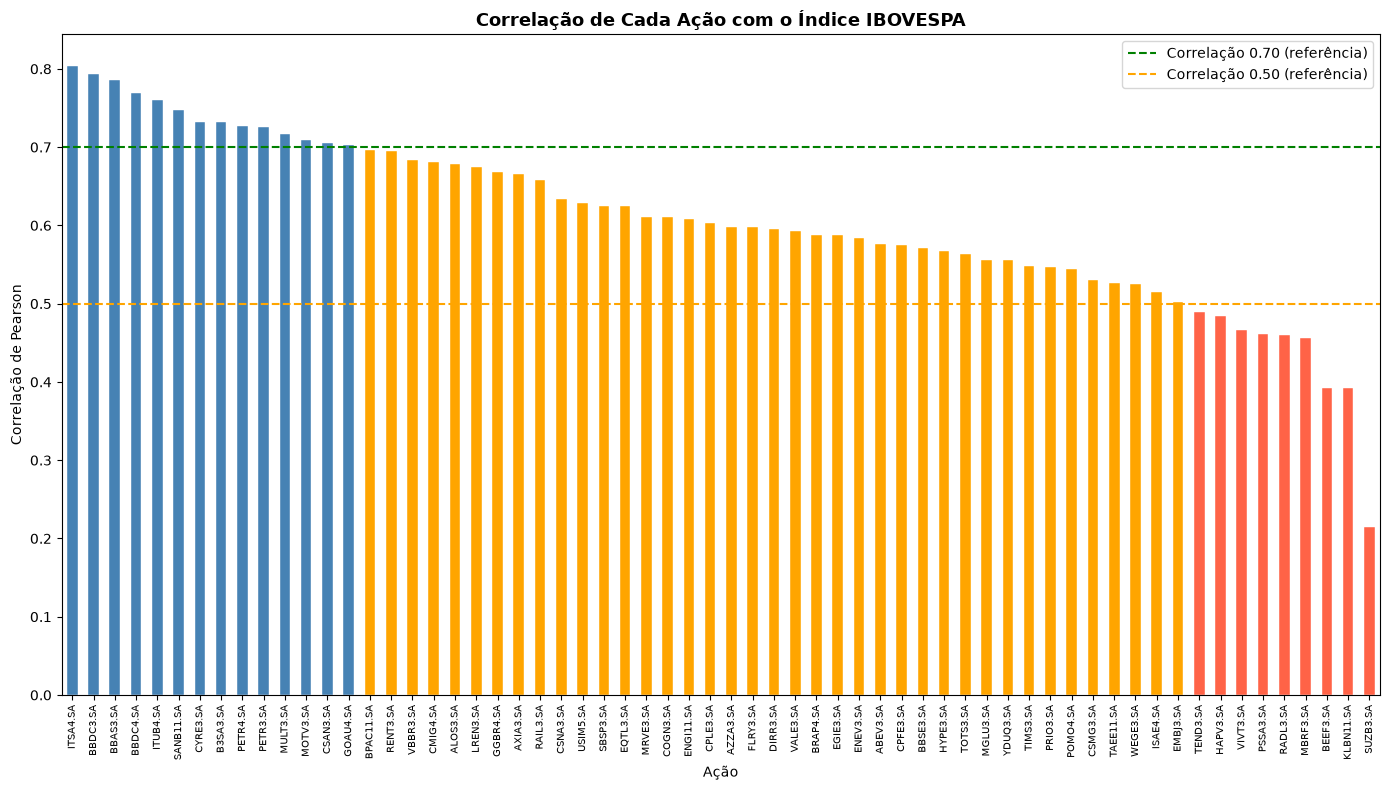


22.6% das ações têm correlação > 0.7 com o índice


In [35]:
# 5.4 ------------------ IBOV ----------------------

# Correlação de cada ação com o índice
# Alinhar os índices de data primeiro
datas_comuns_ib = ret_ibov_clean.index.intersection(ret_idx_ib.index)
ret_acoes_al_ib = ret_ibov_clean.loc[datas_comuns_ib]
ret_idx_al_ib = ret_idx_ib.loc[datas_comuns_ib]

# Calcular correlação de cada ação com o índice
corr_com_idx_ib = ret_acoes_al_ib.corrwith(ret_idx_al_ib).sort_values(ascending=False)

print('TOP 15 — Ações mais correlacionadas com o IBOV:')
print(corr_com_idx_ib.head(15).round(4))
print('\nBOTTOM 10 — Ações menos correlacionadas com o IBOV:')
print(corr_com_idx_ib.tail(10).round(4))

# Gráfico de correlação com o índice
plt.figure(figsize=(14, 8))
cores_ib = ['steelblue' if c > 0.7 else ('orange' if c > 0.5 else 'tomato')
            for c in corr_com_idx_ib.values]
corr_com_idx_ib.plot(kind='bar', color=cores_ib, edgecolor='white', linewidth=0.3)
plt.axhline(0.7, color='green', linestyle='--', linewidth=1.5,
            label='Correlação 0.70 (referência)')
plt.axhline(0.5, color='orange', linestyle='--', linewidth=1.5,
            label='Correlação 0.50 (referência)')
plt.title('Correlação de Cada Ação com o Índice IBOVESPA', fontweight='bold', fontsize=13)
plt.xlabel('Ação')
plt.ylabel('Correlação de Pearson')
plt.xticks(rotation=90, fontsize=7)
plt.legend()
plt.tight_layout()
plt.savefig('correlacao_com_indice_ibov.png', dpi=150)
plt.show()

# Quantos % das ações têm correlação > 0.7?
pct_alta_corr_ib = (corr_com_idx_ib > 0.7).mean() * 100
print(f'\n{pct_alta_corr_ib:.1f}% das ações têm correlação > 0.7 com o índice')

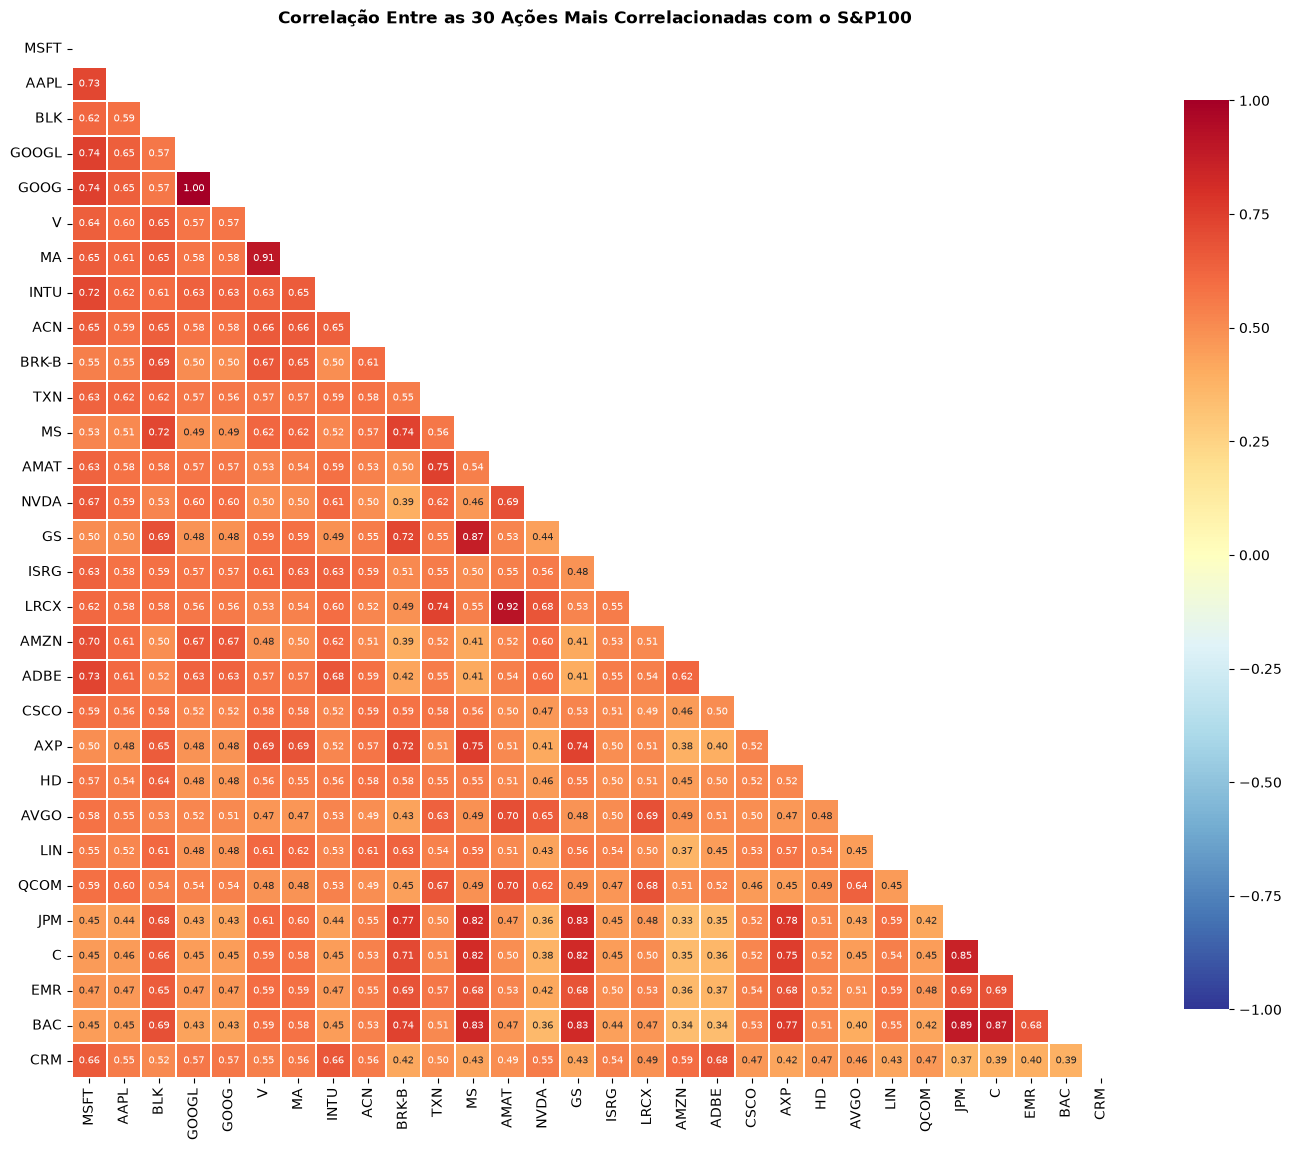

Pares com correlação > 0.90: 3
Ação 1 Ação 2  Correlação
  GOOG  GOOGL       0.996
  AMAT   LRCX       0.920
    MA      V       0.906


In [36]:
#6.1 Matriz de correlação entre todas as ações ----------- S&P 100 -------------
corr_matrix = ret_sp100_clean.corr()

# Calcular a correlação de cada ação com o próprio índice S&P 100
corr_com_idx = ret_sp100_clean.corrwith(ret_idx_sp).sort_values(ascending=False)

# Heatmap,para muitas ações, use uma amostra das mais representativas
# Selecionar as 30 ações com maior correlação com o índice
top30 = corr_com_idx.head(30).index
corr_top30 = ret_sp100_clean[top30].corr()
plt.figure(figsize=(14, 12))
import numpy as np
mask = np.triu(np.ones_like(corr_top30, dtype=bool)) # mostrar só triângulo inferior
sns.heatmap(
corr_top30,
mask=mask,
annot=True, fmt='.2f',
cmap='RdYlBu_r',
center=0, square=True,
linewidths=0.3,
vmin=-1, vmax=1,
cbar_kws={'shrink': 0.8},
annot_kws={'size': 7}
)
plt.title('Correlação Entre as 30 Ações Mais Correlacionadas com o S&P100',
fontweight='bold', fontsize=12)
plt.tight_layout()
plt.savefig('heatmap_correlacao_acoes.png', dpi=150, bbox_inches='tight')
plt.show()

# Encontrar pares com correlação muito alta (potencialmente redundantes)
pares_alta_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if r > 0.90:
            pares_alta_corr.append({
                'Ação 1': corr_matrix.columns[i],
                'Ação 2': corr_matrix.columns[j],
                'Correlação': round(r, 3)
                })
            
df_pares = pd.DataFrame(pares_alta_corr).sort_values('Correlação', ascending=False)
print(f'Pares com correlação > 0.90: {len(df_pares)}')
print(df_pares.head(20).to_string(index=False))


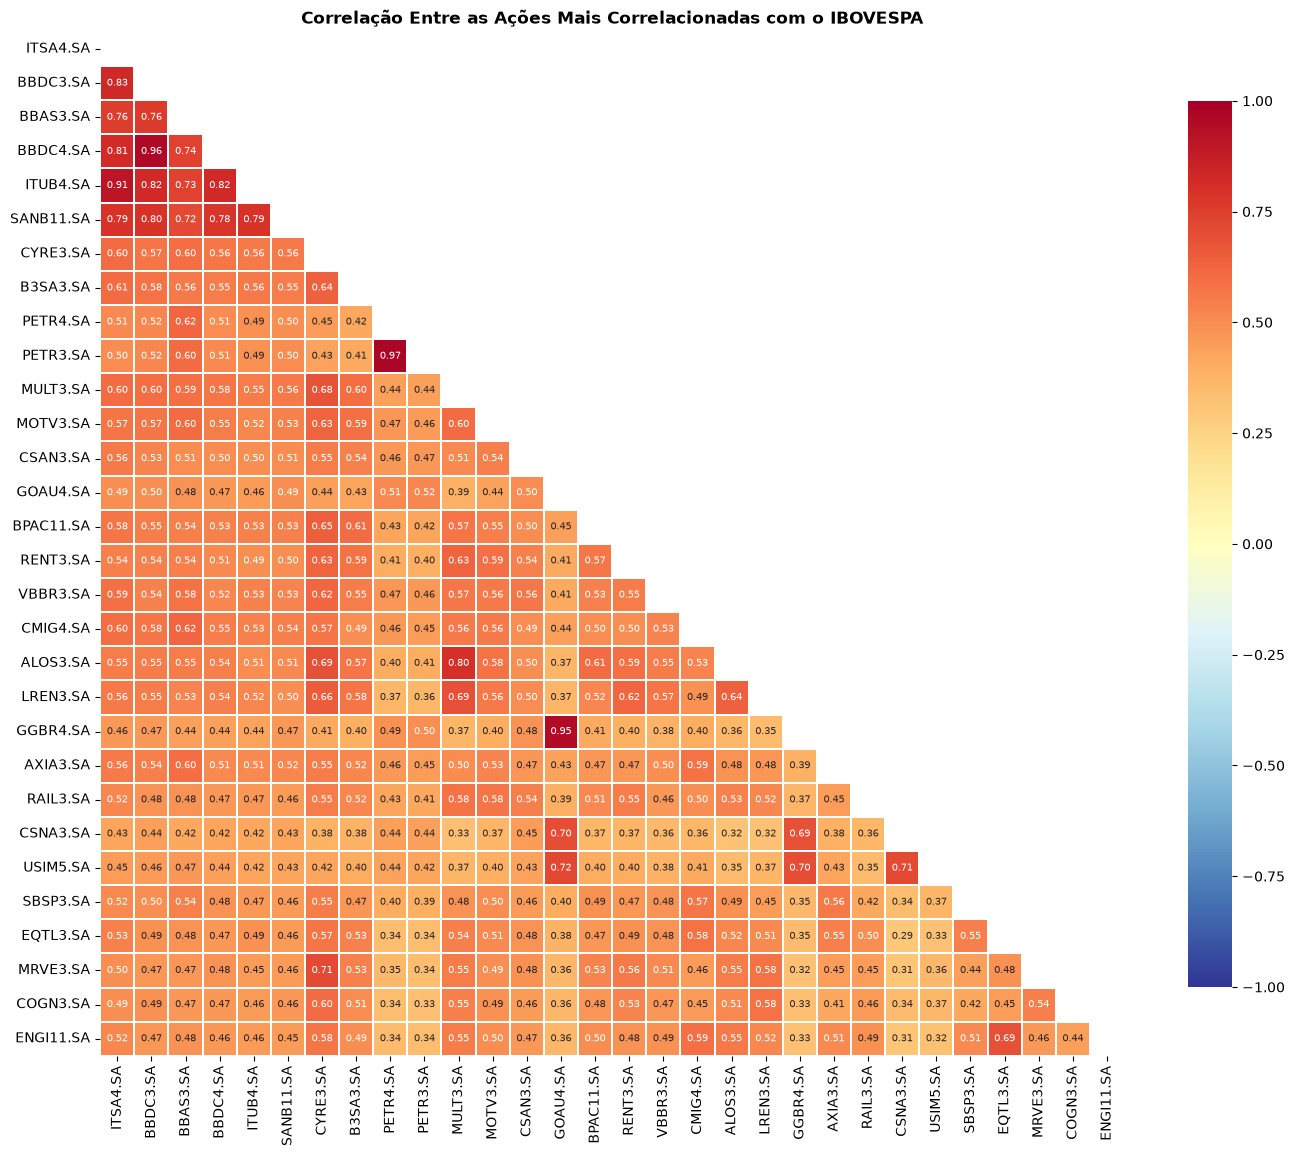

Pares com correlação > 0.90: 4
  Ação 1   Ação 2  Correlação
PETR3.SA PETR4.SA       0.969
BBDC3.SA BBDC4.SA       0.960
GGBR4.SA GOAU4.SA       0.952
ITSA4.SA ITUB4.SA       0.910


In [37]:
# 6.1 Matriz de correlação entre todas as ações ------------- IBOV -
corr_matrix_ib = ret_ibov_clean.corr()
corr_com_idx_ib = ret_ibov_clean.corrwith(ret_idx_ib).sort_values(ascending=False)

# Heatmap — para muitas ações, use uma amostra das mais representativas
# Selecionar as 30 ações com maior correlação com o índice
# (se o IBOV tiver menos de 30 ações válidas após a limpeza, pega todas)
top30_ib = corr_com_idx_ib.head(30).index
corr_top30_ib = ret_ibov_clean[top30_ib].corr()

plt.figure(figsize=(14, 12))
mask_ib = np.triu(np.ones_like(corr_top30_ib, dtype=bool))  # mostrar só triângulo inferior
sns.heatmap(
    corr_top30_ib,
    mask=mask_ib,
    annot=True, fmt='.2f',
    cmap='RdYlBu_r',
    center=0, square=True,
    linewidths=0.3,
    vmin=-1, vmax=1,
    cbar_kws={'shrink': 0.8},
    annot_kws={'size': 7}
)
plt.title('Correlação Entre as Ações Mais Correlacionadas com o IBOVESPA',
          fontweight='bold', fontsize=12)
plt.tight_layout()
plt.savefig('heatmap_correlacao_acoes_ibov.png', dpi=150, bbox_inches='tight')
plt.show()

# Encontrar pares com correlação muito alta (potencialmente redundantes)
pares_alta_corr_ib = []
for i in range(len(corr_matrix_ib.columns)):
    for j in range(i + 1, len(corr_matrix_ib.columns)):
        r = corr_matrix_ib.iloc[i, j]
        if r > 0.90:
            pares_alta_corr_ib.append({
                'Ação 1': corr_matrix_ib.columns[i],
                'Ação 2': corr_matrix_ib.columns[j],
                'Correlação': round(r, 3)
            })
df_pares_ib = pd.DataFrame(pares_alta_corr_ib).sort_values('Correlação', ascending=False)
print(f'Pares com correlação > 0.90: {len(df_pares_ib)}')
print(df_pares_ib.head(20).to_string(index=False))

Correlação média com o índice por setor — S&P100:
                            Corr. média  Desvio  N ações
setor                                                   
Finanças                          0.695   0.064       15
Materiais                         0.694     NaN        1
Tecnologia da Informação          0.686   0.080       22
Consumo discricionário            0.625   0.067        8
Serviços de comunicação           0.592   0.141        9
Industriais                       0.582   0.057       12
Energia                           0.524   0.031        3
Bens de consumo essenciais        0.511   0.075        8
Assistência médica                0.510   0.100       15
Imobiliária                       0.483     NaN        1
Serviços públicos                 0.445   0.022        3


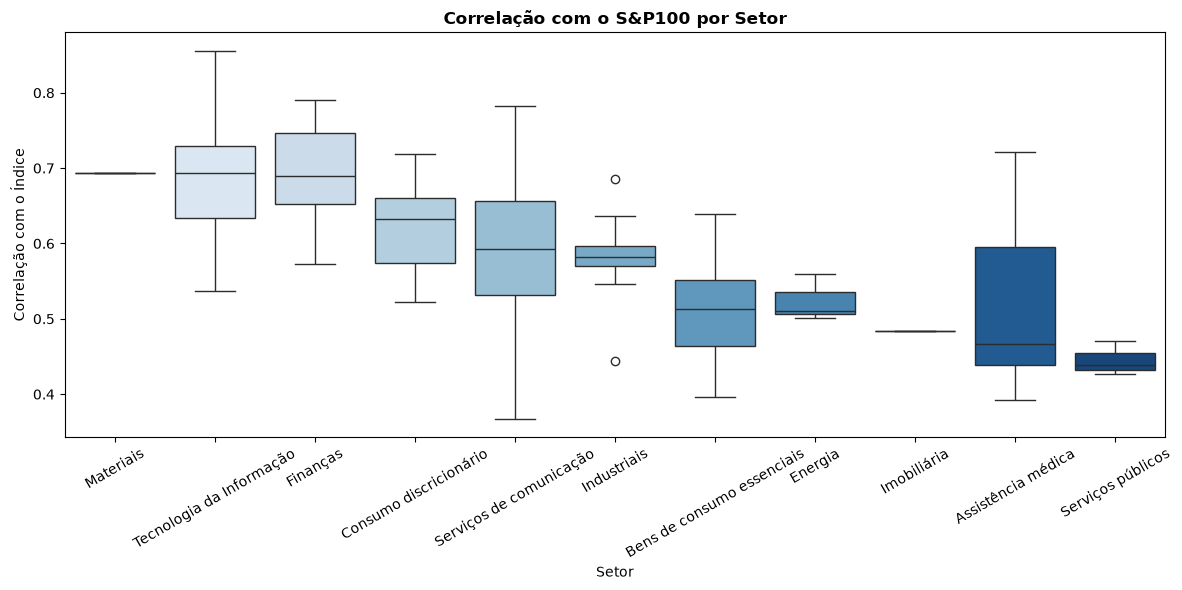

In [38]:
# 6.2 Adicionar setor de cada ação e analisar correlação média por setor ----- SP100 ------
# Dicionário de setores,preencha com os setores reais
setores_sp100 = {
    'AAPL': 'Tecnologia da Informação', 'ABBV': 'Assistência médica', 'ABT': 'Assistência médica',
    'ACN': 'Tecnologia da Informação', 'ADBE': 'Tecnologia da Informação', 'AMAT': 'Tecnologia da Informação',
    'AMD': 'Tecnologia da Informação', 'AMGN': 'Assistência médica', 'AMT': 'Imobiliária',
    'AMZN': 'Consumo discricionário', 'ANET': 'Tecnologia da Informação', 'AVGO': 'Tecnologia da Informação',
    'AXP': 'Finanças', 'BA': 'Industriais', 'BAC': 'Finanças', 'BKNG': 'Consumo discricionário',
    'BLK': 'Finanças', 'BMY': 'Assistência médica', 'BNY': 'Finanças', 'BRK-B': 'Finanças',
    'C': 'Finanças', 'CAT': 'Industriais', 'CMCSA': 'Serviços de comunicação', 'COF': 'Finanças',
    'COP': 'Energia', 'COST': 'Bens de consumo essenciais', 'CRM': 'Tecnologia da Informação',
    'CSCO': 'Tecnologia da Informação', 'CVS': 'Assistência médica', 'CVX': 'Energia',
    'DE': 'Industriais', 'DELL': 'Tecnologia da Informação', 'DHR': 'Assistência médica',
    'DIS': 'Serviços de comunicação', 'DUK': 'Serviços públicos', 'EMR': 'Industriais',
    'FDX': 'Industriais', 'GD': 'Industriais', 'GE': 'Industriais', 'GEV': 'Industriais',
    'GILD': 'Assistência médica', 'GM': 'Consumo discricionário', 'GOOG': 'Serviços de comunicação',
    'GOOGL': 'Serviços de comunicação', 'GS': 'Finanças', 'HD': 'Consumo discricionário',
    'IBM': 'Tecnologia da Informação', 'INTC': 'Tecnologia da Informação', 'INTU': 'Tecnologia da Informação',
    'ISRG': 'Assistência médica', 'JNJ': 'Assistência médica', 'JPM': 'Finanças',
    'KO': 'Bens de consumo essenciais', 'LIN': 'Materiais', 'LLY': 'Assistência médica',
    'LMT': 'Industriais', 'LOW': 'Consumo discricionário', 'LRCX': 'Tecnologia da Informação',
    'MA': 'Finanças', 'MCD': 'Consumo discricionário', 'MDLZ': 'Bens de consumo essenciais',
    'MDT': 'Assistência médica', 'META': 'Serviços de comunicação', 'MMM': 'Industriais',
    'MO': 'Bens de consumo essenciais', 'MRK': 'Assistência médica', 'MS': 'Finanças',
    'MSFT': 'Tecnologia da Informação', 'MU': 'Tecnologia da Informação', 'NEE': 'Serviços públicos',
    'NFLX': 'Serviços de comunicação', 'NOW': 'Tecnologia da Informação', 'NVDA': 'Tecnologia da Informação',
    'ORCL': 'Tecnologia da Informação', 'PANW': 'Tecnologia da Informação', 'PEP': 'Bens de consumo essenciais',
    'PFE': 'Assistência médica', 'PG': 'Bens de consumo essenciais', 'PLTR': 'Tecnologia da Informação',
    'PM': 'Bens de consumo essenciais', 'QCOM': 'Tecnologia da Informação', 'RTX': 'Industriais',
    'SBUX': 'Consumo discricionário', 'SCHW': 'Finanças', 'SNDK': 'Tecnologia da Informação',
    'SO': 'Serviços públicos', 'T': 'Serviços de comunicação', 'TMO': 'Assistência médica',
    'TMUS': 'Serviços de comunicação', 'TSLA': 'Consumo discricionário', 'TXN': 'Tecnologia da Informação',
    'UBER': 'Industriais', 'UNH': 'Assistência médica', 'UNP': 'Industriais', 'UPS': 'Industriais',
    'USB': 'Finanças', 'V': 'Finanças', 'VZ': 'Serviços de comunicação', 'WFC': 'Finanças',
    'WMT': 'Bens de consumo essenciais', 'XOM': 'Energia',
}
# Correlação média com o índice por setor
df_corr_setor_sp = pd.DataFrame({
    'acao': corr_com_idx_sp.index,
    'corr_idx': corr_com_idx_sp.values
})
df_corr_setor_sp['setor'] = df_corr_setor_sp['acao'].map(setores_sp100).fillna('Outros')
corr_por_setor_sp = df_corr_setor_sp.groupby('setor')['corr_idx'].agg(['mean', 'std', 'count'])
corr_por_setor_sp.columns = ['Corr. média', 'Desvio', 'N ações']
print('Correlação média com o índice por setor — S&P100:')
print(corr_por_setor_sp.sort_values('Corr. média', ascending=False).round(3))

# Boxplot de correlação por setor
plt.figure(figsize=(12, 6))
setores_ord_sp = df_corr_setor_sp.groupby('setor')['corr_idx'].median().sort_values(ascending=False).index
sns.boxplot(data=df_corr_setor_sp, x='setor', y='corr_idx',
            order=setores_ord_sp, palette='Blues')
plt.title('Correlação com o S&P100 por Setor', fontweight='bold')
plt.xlabel('Setor')
plt.ylabel('Correlação com o Índice')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('correlacao_por_setor_sp100.png', dpi=150)
plt.show()


Correlação média com o índice por setor — IBOV:
                            Corr. média  Desvio  N ações
setor                                                   
Finanças                          0.712   0.111       10
Energia                           0.678   0.075        5
Imobiliária                       0.637   0.091        6
Consumo discricionário            0.615   0.059        6
Serviços públicos                 0.594   0.053       12
Industriais                       0.588   0.090        5
Tecnologia da Informação          0.564     NaN        1
Materiais                         0.553   0.165        8
Assistência médica                0.550   0.059        3
Serviços de comunicação           0.507   0.059        2
Bens de consumo essenciais        0.471   0.077        4


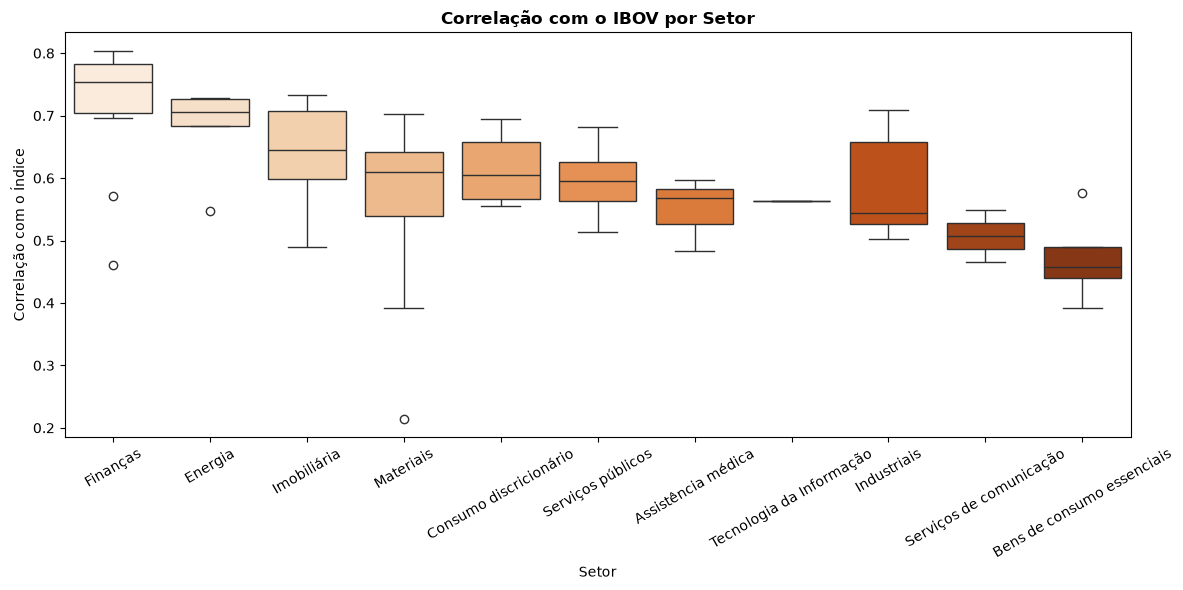

In [39]:
# 6.2 Adicionar setor de cada ação e analisar correlação média por setor ----- IBOV ------
setores_ibov = {
    'ABEV3.SA': 'Bens de consumo essenciais', 'ALOS3.SA': 'Imobiliária', 'ASAI3.SA': 'Bens de consumo essenciais',
    'AURE3.SA': 'Serviços públicos', 'AXIA3.SA': 'Serviços públicos', 'AZZA3.SA': 'Consumo discricionário',
    'B3SA3.SA': 'Finanças', 'BBAS3.SA': 'Finanças', 'BBDC3.SA': 'Finanças', 'BBDC4.SA': 'Finanças',
    'BBSE3.SA': 'Finanças', 'BEEF3.SA': 'Bens de consumo essenciais', 'BPAC11.SA': 'Finanças',
    'BRAP4.SA': 'Materiais', 'BRAV3.SA': 'Energia', 'CEAB3.SA': 'Consumo discricionário',
    'CMIG4.SA': 'Serviços públicos', 'CMIN3.SA': 'Materiais', 'COGN3.SA': 'Consumo discricionário',
    'CPFE3.SA': 'Serviços públicos', 'CPLE3.SA': 'Serviços públicos', 'CSAN3.SA': 'Energia',
    'CSMG3.SA': 'Serviços públicos', 'CSNA3.SA': 'Materiais', 'CURY3.SA': 'Imobiliária',
    'CXSE3.SA': 'Finanças', 'CYRE3.SA': 'Imobiliária', 'DIRR3.SA': 'Imobiliária', 'EGIE3.SA': 'Serviços públicos',
    'EMBJ3.SA': 'Industriais', 'ENEV3.SA': 'Serviços públicos', 'ENGI11.SA': 'Serviços públicos',
    'EQTL3.SA': 'Serviços públicos', 'FLRY3.SA': 'Assistência médica', 'GGBR4.SA': 'Materiais',
    'GOAU4.SA': 'Materiais', 'HAPV3.SA': 'Assistência médica', 'HYPE3.SA': 'Assistência médica',
    'IGTI11.SA': 'Imobiliária', 'ISAE4.SA': 'Serviços públicos', 'ITSA4.SA': 'Finanças', 'ITUB4.SA': 'Finanças',
    'KLBN11.SA': 'Materiais', 'LREN3.SA': 'Consumo discricionário', 'MBRF3.SA': 'Bens de consumo essenciais',
    'MGLU3.SA': 'Consumo discricionário', 'MOTV3.SA': 'Industriais', 'MRVE3.SA': 'Imobiliária',
    'MULT3.SA': 'Imobiliária', 'NATU3.SA': 'Consumo discricionário', 'PETR3.SA': 'Energia', 'PETR4.SA': 'Energia',
    'POMO4.SA': 'Industriais', 'PRIO3.SA': 'Energia', 'PSSA3.SA': 'Finanças', 'RADL3.SA': 'Bens de consumo essenciais',
    'RAIL3.SA': 'Industriais', 'RDOR3.SA': 'Assistência médica', 'RENT3.SA': 'Consumo discricionário',
    'SANB11.SA': 'Finanças', 'SBSP3.SA': 'Serviços públicos', 'SMFT3.SA': 'Consumo discricionário',
    'SUZB3.SA': 'Materiais', 'TAEE11.SA': 'Serviços públicos', 'TEND3.SA': 'Imobiliária',
    'TIMS3.SA': 'Serviços de comunicação', 'TOTS3.SA': 'Tecnologia da Informação', 'UGPA3.SA': 'Energia',
    'USIM5.SA': 'Materiais', 'VALE3.SA': 'Materiais', 'VAMO3.SA': 'Industriais', 'VBBR3.SA': 'Energia',
    'VIVA3.SA': 'Consumo discricionário', 'VIVT3.SA': 'Serviços de comunicação', 'WEGE3.SA': 'Industriais',
    'YDUQ3.SA': 'Consumo discricionário',
}
# Correlação média com o índice por setor
df_corr_setor_ib = pd.DataFrame({
    'acao': corr_com_idx_ib.index,
    'corr_idx': corr_com_idx_ib.values
})
df_corr_setor_ib['setor'] = df_corr_setor_ib['acao'].map(setores_ibov).fillna('Outros')
corr_por_setor_ib = df_corr_setor_ib.groupby('setor')['corr_idx'].agg(['mean', 'std', 'count'])
corr_por_setor_ib.columns = ['Corr. média', 'Desvio', 'N ações']
print('\nCorrelação média com o índice por setor — IBOV:')
print(corr_por_setor_ib.sort_values('Corr. média', ascending=False).round(3))

# Boxplot de correlação por setor
plt.figure(figsize=(12, 6))
setores_ord_ib = df_corr_setor_ib.groupby('setor')['corr_idx'].median().sort_values(ascending=False).index
sns.boxplot(data=df_corr_setor_ib, x='setor', y='corr_idx',
            order=setores_ord_ib, palette='Oranges')
plt.title('Correlação com o IBOV por Setor', fontweight='bold')
plt.xlabel('Setor')
plt.ylabel('Correlação com o Índice')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('correlacao_por_setor_ibov.png', dpi=150)
plt.show()

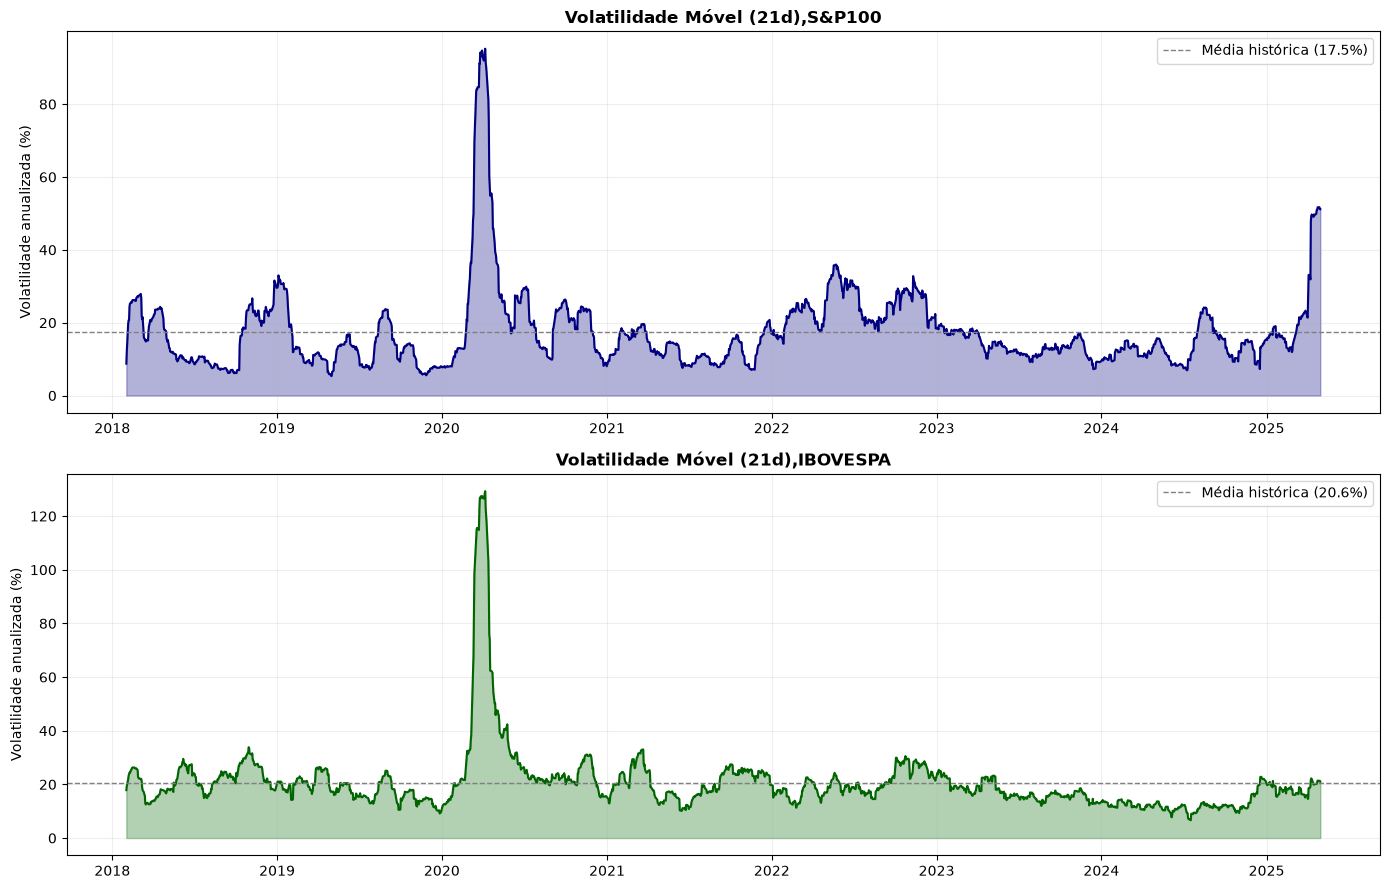

Volatilidade média histórica S&P100: 17.5% a.a.
Volatilidade máxima S&P100: 95.2% a.a.
Data do pico de volatilidade: 2020-04-06

Volatilidade média histórica IBOV: 20.6% a.a.
Volatilidade máxima IBOV: 129.3% a.a.


In [40]:
# Volatilidade móvel (rolling),janela de 21 dias úteis (~1 mês) ------ SP100 + IBOV ----------
vol_sp = ret_idx_sp.rolling(window=21).std() * np.sqrt(252) * 100 # anualizada
vol_ib = ret_idx_ib.rolling(window=21).std() * np.sqrt(252) * 100
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=False)
for ax, vol, ret, titulo, cor in [
    (axes[0], vol_sp, ret_idx_sp, 'Volatilidade Móvel (21d),S&P100', 'navy'),
    (axes[1], vol_ib, ret_idx_ib, 'Volatilidade Móvel (21d),IBOVESPA', 'darkgreen'),
]:
    ax.fill_between(vol.index, vol, alpha=0.3, color=cor)
    ax.plot(vol.index, vol, color=cor, linewidth=1.5)
    ax.axhline(vol.mean(), color='gray', linestyle='--', linewidth=1,
        label=f'Média histórica ({vol.mean():.1f}%)')
    ax.set_title(titulo, fontweight='bold', fontsize=12)
    ax.set_ylabel('Volatilidade anualizada (%)')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.2)
    
# Marcar COVID
covid_date = '2020-03-01'
if covid_date in vol.index.strftime('%Y-%m-%d'):
    ax.axvline(pd.Timestamp(covid_date), color='red',
        linestyle=':', linewidth=2, alpha=0.7, label='COVID-19')
    
plt.tight_layout()
plt.savefig('volatilidade_movel.png', dpi=150)
plt.show()

# Estatísticas de volatilidade
print(f'Volatilidade média histórica S&P100: {vol_sp.mean():.1f}% a.a.')
print(f'Volatilidade máxima S&P100: {vol_sp.max():.1f}% a.a.')
print(f'Data do pico de volatilidade: {vol_sp.idxmax().date()}')
print(f'\nVolatilidade média histórica IBOV: {vol_ib.mean():.1f}% a.a.')
print(f'Volatilidade máxima IBOV: {vol_ib.max():.1f}% a.a.')


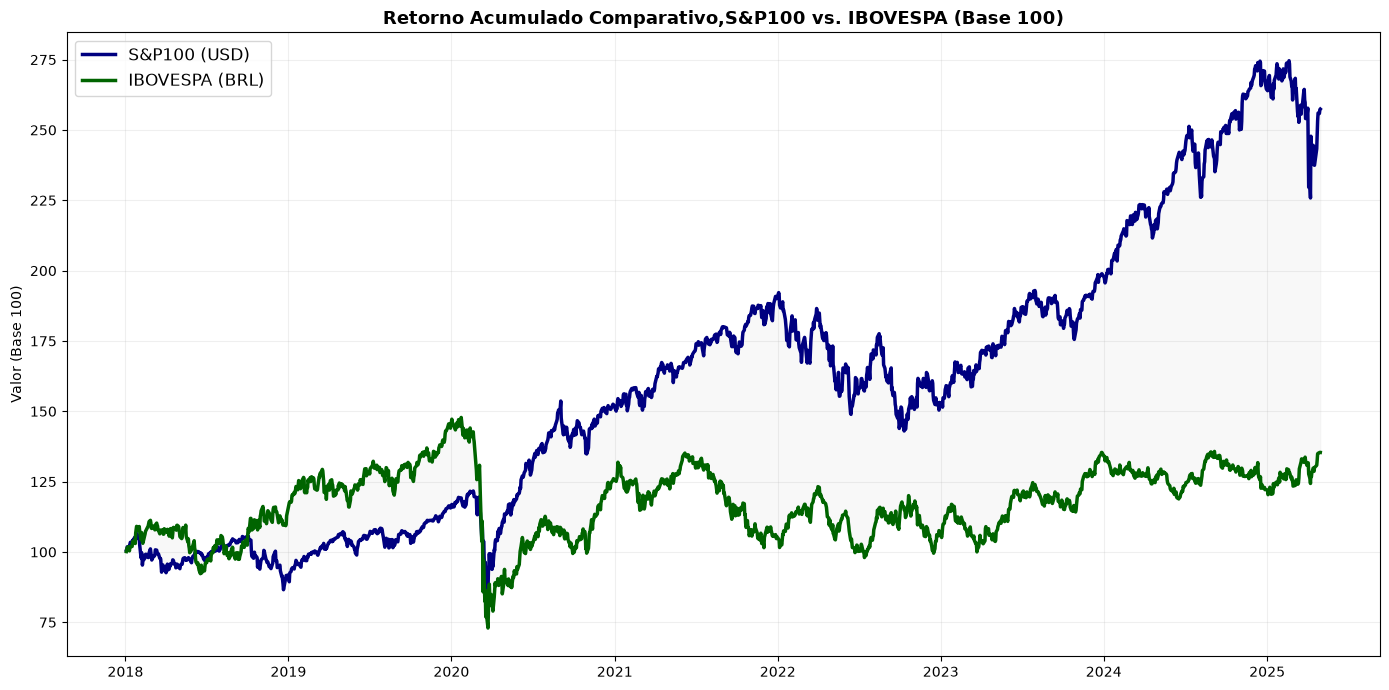


=== COMPARATIVO S&P100 vs. IBOVESPA ===
                          S&P100 IBOVESPA
Retorno anualizado        15.59%    7.33%
Volatilidade anualizada   20.55%   24.36%
Sharpe aproximado          0.759    0.301
Retorno acumulado total   157.4%    35.4%
Pior dia                 -12.29%  -15.99%
Melhor dia                 9.71%   13.02%


In [41]:
# Alinhar datas dos dois índices para comparação direta
datas_comuns_idx = ret_idx_sp.index.intersection(ret_idx_ib.index)
sp_al = ret_idx_sp.loc[datas_comuns_idx]
ib_al = ret_idx_ib.loc[datas_comuns_idx]
# Retorno acumulado comparativo
sp_acum = (1 + sp_al).cumprod() * 100
ib_acum = (1 + ib_al).cumprod() * 100
plt.figure(figsize=(14, 7))
plt.plot(sp_acum.index, sp_acum, color='navy', lw=2.5, label='S&P100 (USD)')
plt.plot(ib_acum.index, ib_acum, color='darkgreen', lw=2.5, label='IBOVESPA (BRL)')
plt.fill_between(sp_acum.index, sp_acum, ib_acum, alpha=0.05, color='gray')
plt.title('Retorno Acumulado Comparativo,S&P100 vs. IBOVESPA (Base 100)',
fontweight='bold', fontsize=13)
plt.ylabel('Valor (Base 100)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig('comparativo_sp100_ibov.png', dpi=150)
plt.show()

# Tabela resumo comparativa
resumo = pd.DataFrame({
'S&P100': [
f'{sp_al.mean()*252*100:.2f}%',
f'{sp_al.std()*np.sqrt(252)*100:.2f}%',
f'{(sp_al.mean()/sp_al.std()*np.sqrt(252)):.3f}',
f'{sp_acum.iloc[-1]-100:.1f}%',
f'{sp_al.min()*100:.2f}%',
f'{sp_al.max()*100:.2f}%',
],
'IBOVESPA': [
f'{ib_al.mean()*252*100:.2f}%',
f'{ib_al.std()*np.sqrt(252)*100:.2f}%',
f'{(ib_al.mean()/ib_al.std()*np.sqrt(252)):.3f}',
f'{ib_acum.iloc[-1]-100:.1f}%',
f'{ib_al.min()*100:.2f}%',
f'{ib_al.max()*100:.2f}%',
]
}, index=['Retorno anualizado', 'Volatilidade anualizada', 'Sharpe aproximado',
'Retorno acumulado total', 'Pior dia', 'Melhor dia'])
print('\n=== COMPARATIVO S&P100 vs. IBOVESPA ===')
print(resumo.to_string())

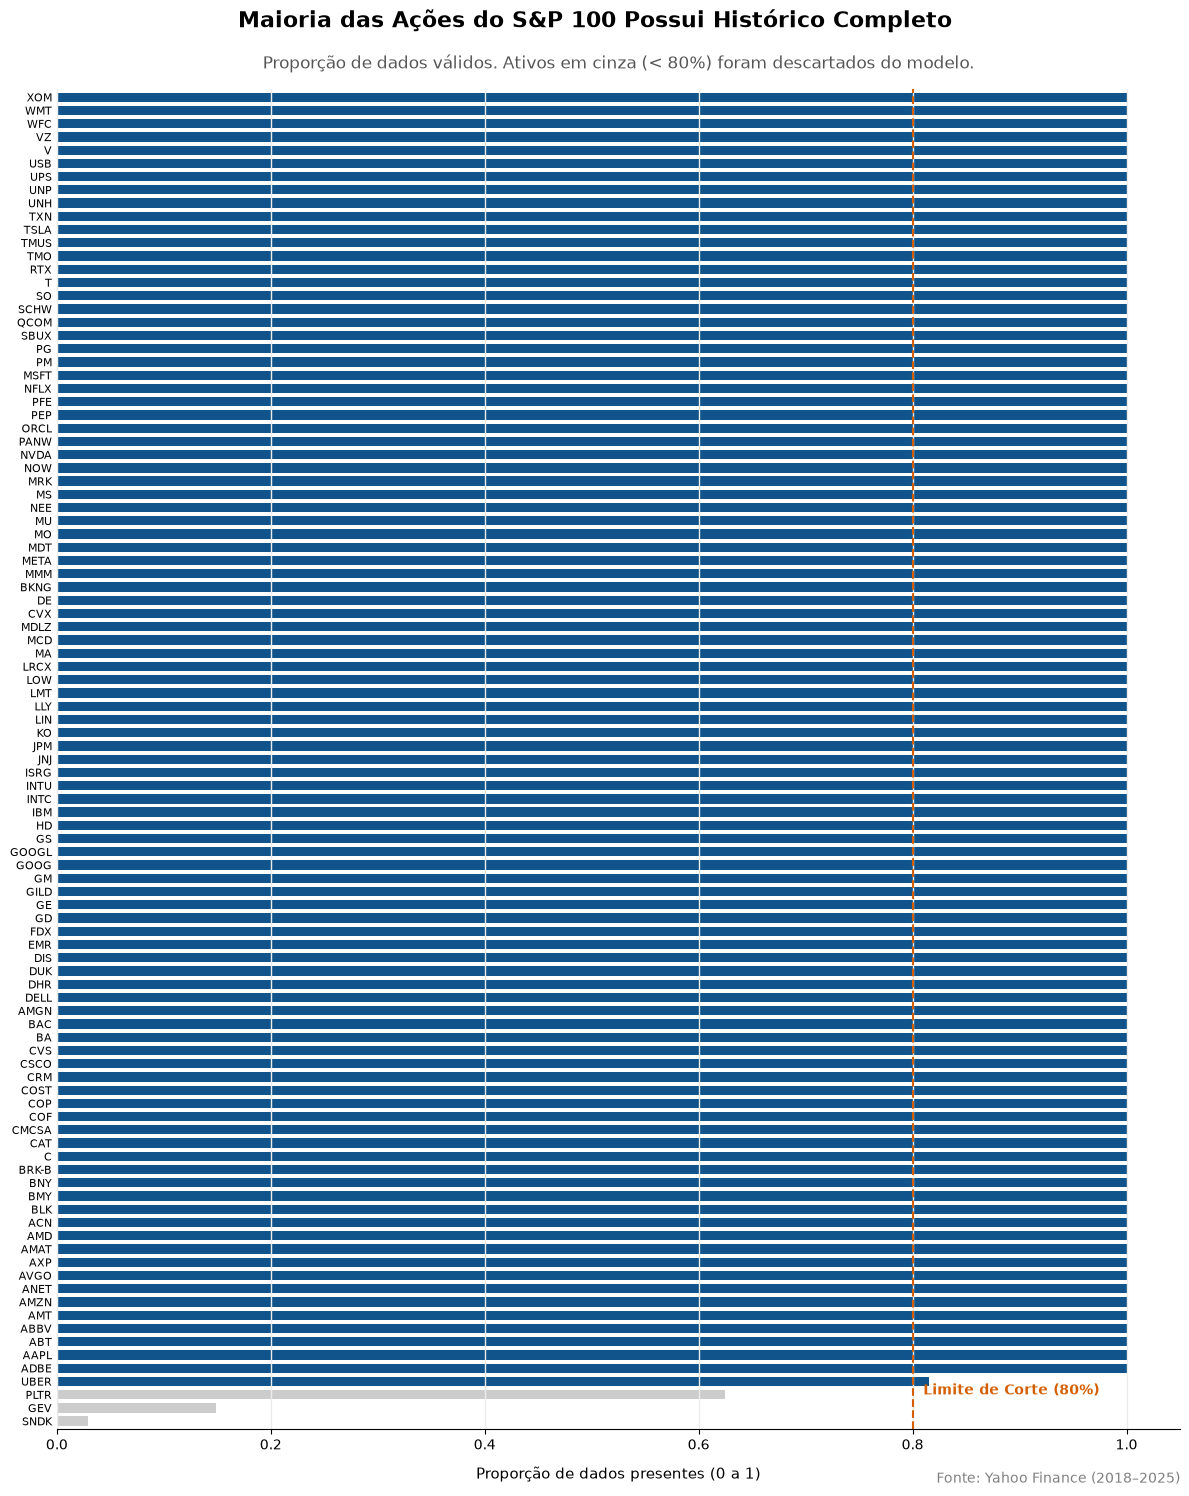

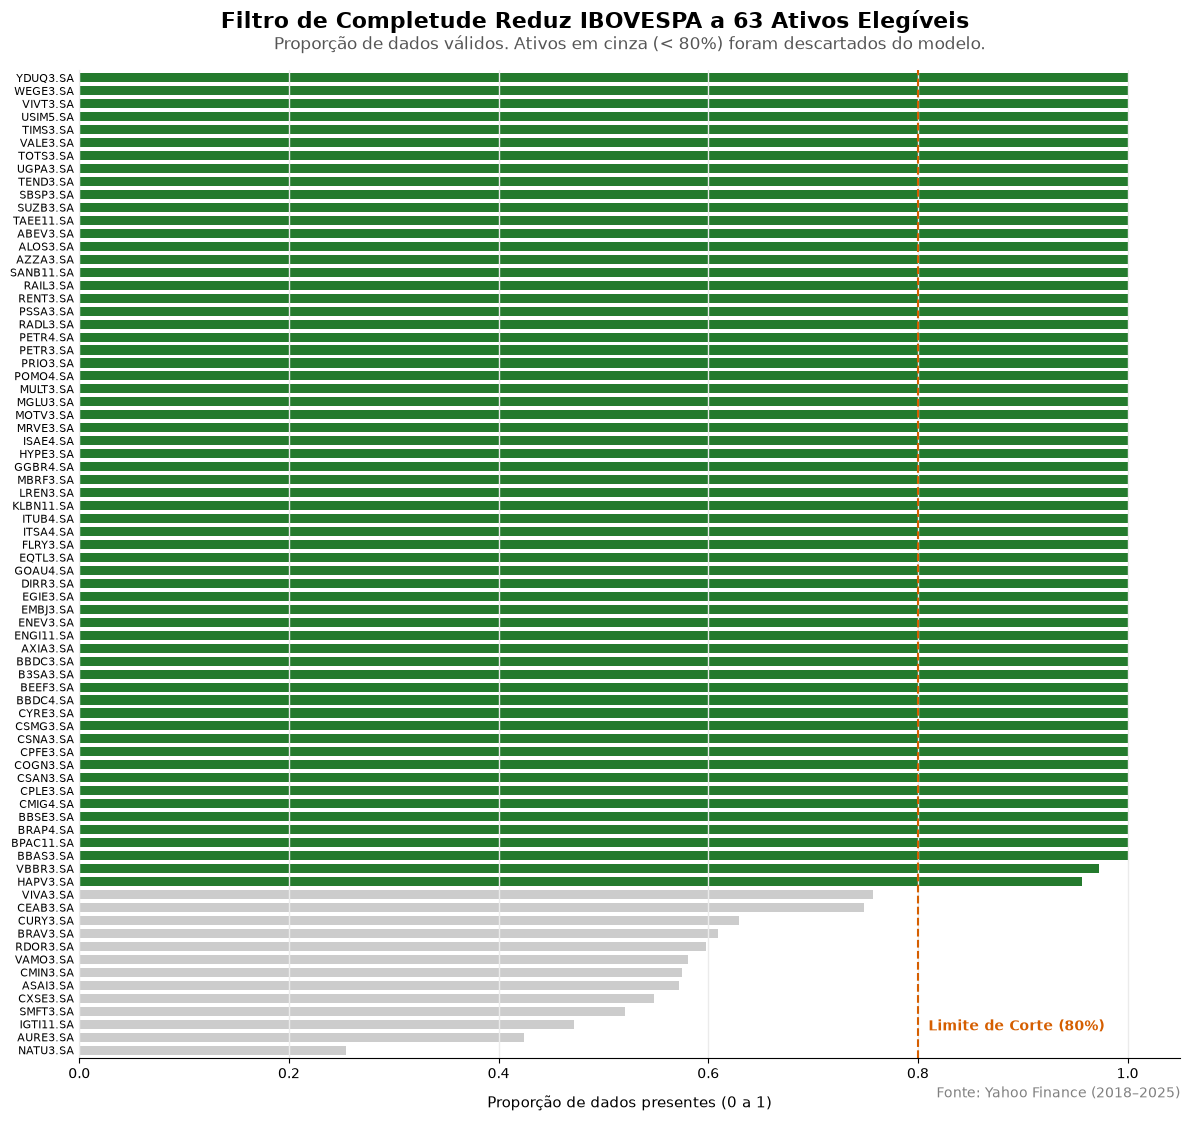

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Cores baseadas no seu gráfico de referência
cor_sp = '#10548b'    # Azul forte
cor_ibov = '#247a2d'  # Verde escuro
cor_corte = '#d55e00' # Laranja/Vermelho para a linha de corte
cor_cinza = '#cccccc' # Cinza para as removidas

def plot_completude_padrao(pct_nulos, limite, titulo, subtitulo, cor_destaque, filename, altura_fig=16):
    completude = (1 - pct_nulos / 100).sort_values()
    
    # Altura ajustável (16 para S&P100, 12 para IBOV)
    fig, ax = plt.subplots(figsize=(12, altura_fig))
    
    # Cores condicionais: cinza se < 80%, cor de destaque se >= 80%
    cores = [cor_cinza if val < (1 - limite/100) else cor_destaque for val in completude]
    
    completude.plot(kind='barh', color=cores, width=0.7, ax=ax)
    
    # Limpeza visual (Grid e bordas)
    ax.grid(axis='x', color='#ebebeb', linewidth=1, zorder=0)
    ax.grid(axis='y', visible=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#ebebeb')
    
    # Reduz tamanho da fonte dos tickers para não esmagar
    ax.tick_params(axis='y', length=0, labelsize=8) 
    ax.tick_params(axis='x', labelsize=10)
    
    # Título Principal e Subtítulo Centralizados
    fig.suptitle(titulo, fontsize=16, fontweight='bold', ha='center', y=0.93)
    ax.set_title(subtitulo, fontsize=12, color='#555555', pad=15)
    
    # Linha de Corte
    ax.axvline(1 - limite/100, color=cor_corte, linewidth=1.5, linestyle='--')
    ax.text((1 - limite/100) + 0.01, len(completude)*0.02, 'Limite de Corte (80%)', color=cor_corte, fontsize=10, fontweight='bold')
    
    ax.set_xlabel('Proporção de dados presentes (0 a 1)', fontsize=11, labelpad=10)
    ax.set_ylabel('')
    
    # Inserção da Fonte (Canto inferior direito)
    plt.text(1, -0.04, 'Fonte: Yahoo Finance (2018–2025)', transform=ax.transAxes, ha='right', fontsize=10, color='gray')
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.88)
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

# Gerando o gráfico do S&P 100 (Altura 16 para caber 100 tickers)
plot_completude_padrao(
    pct_nulos_sp, 20, 
    'Maioria das Ações do S&P 100 Possui Histórico Completo', 
    'Proporção de dados válidos. Ativos em cinza (< 80%) foram descartados do modelo.', 
    cor_sp, 'completude_sp100_final.png', altura_fig=16
)

# Gerando o gráfico do IBOVESPA (Altura 12 é suficiente para ~70 tickers)
plot_completude_padrao(
    pct_nulos_ib, 20, 
    'Filtro de Completude Reduz IBOVESPA a 63 Ativos Elegíveis', 
    'Proporção de dados válidos. Ativos em cinza (< 80%) foram descartados do modelo.', 
    cor_ibov, 'completude_ibov_final.png', altura_fig=12
)

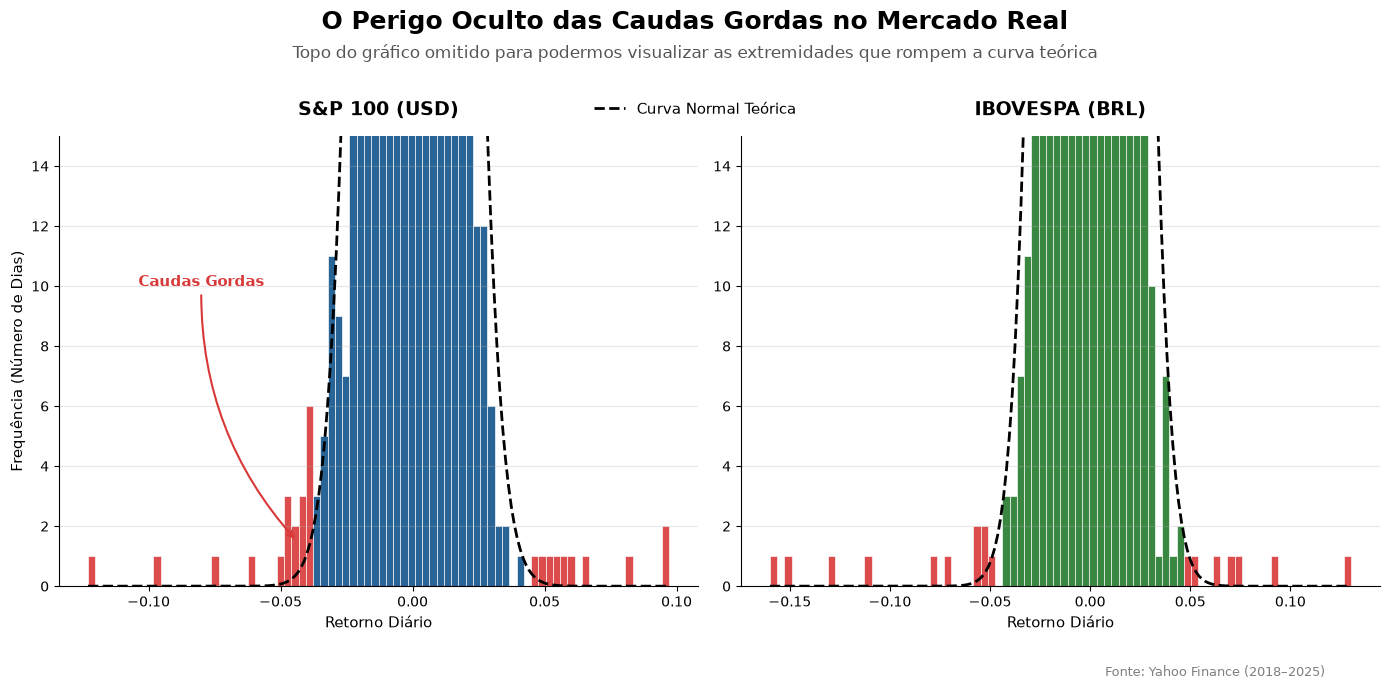

In [43]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- S&P 100 ---
ax1 = axes[0]
mu_sp, std_sp = sp_al.mean(), sp_al.std()
limite_sp = 3 * std_sp 

# 1. REMOVIDO o density=True. Agora o gráfico mostra a CONTAGEM REAL DE DIAS.
counts1, bins1, patches1 = ax1.hist(sp_al, bins=80, color='#10548b', edgecolor='white', linewidth=0.5, alpha=0.9)

# Pintar as Caudas Gordas
for patch, bin_val in zip(patches1, bins1[:-1]):
    if abs(bin_val - mu_sp) > limite_sp:
        patch.set_facecolor('#d93838')

# 2. O TRUQUE MATEMÁTICO: Escalar a Curva Normal para "Dias" 
# (Multiplicamos a probabilidade pelo total de dias e pela largura da barra)
x_sp = np.linspace(sp_al.min(), sp_al.max(), 200)
largura_bin_sp = bins1[1] - bins1[0]
curva_teorica_sp = norm.pdf(x_sp, mu_sp, std_sp) * len(sp_al) * largura_bin_sp
ax1.plot(x_sp, curva_teorica_sp, 'k--', linewidth=2, label='Normal Teórica')

# 3. O ZOOM INTUITIVO: Cortar o gráfico para focar em eventos que aconteceram até 15 dias
ax1.set_ylim(0, 15)

ax1.annotate('Caudas Gordas', 
             xy=(-limite_sp - 0.005, 1.5), xytext=(-0.08, 10),
             arrowprops=dict(arrowstyle="->", color='#d93838', lw=1.5, connectionstyle="arc3,rad=.2"),
             color='#d93838', fontweight='bold', fontsize=11, ha='center')

ax1.set_title('S&P 100 (USD)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Retorno Diário', fontsize=11)
ax1.set_ylabel('Frequência (Número de Dias)', fontsize=11)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(axis='y', alpha=0.3)


# --- IBOVESPA ---
ax2 = axes[1]
mu_ib, std_ib = ib_al.mean(), ib_al.std()
limite_ib = 3 * std_ib

# Sem density=True
counts2, bins2, patches2 = ax2.hist(ib_al, bins=80, color='#247a2d', edgecolor='white', linewidth=0.5, alpha=0.9)

for patch, bin_val in zip(patches2, bins2[:-1]):
    if abs(bin_val - mu_ib) > limite_ib:
        patch.set_facecolor('#d93838')

# Escalar a curva para o IBOVESPA
x_ib = np.linspace(ib_al.min(), ib_al.max(), 200)
largura_bin_ib = bins2[1] - bins2[0]
curva_teorica_ib = norm.pdf(x_ib, mu_ib, std_ib) * len(ib_al) * largura_bin_ib
ax2.plot(x_ib, curva_teorica_ib, 'k--', linewidth=2, label='Normal Teórica')

# Zoom visual: limite de 15 dias
ax2.set_ylim(0, 15)                

ax2.set_title('IBOVESPA (BRL)', fontsize=14, fontweight='bold', pad=15)
ax2.set_xlabel('Retorno Diário', fontsize=11)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(axis='y', alpha=0.3)


# --- Ajustes Finais ---
fig.suptitle('O Perigo Oculto das Caudas Gordas no Mercado Real', fontsize=18, fontweight='bold', y=1.06)
fig.text(0.5, 0.98, 'Topo do gráfico omitido para podermos visualizar as extremidades que rompem a curva teórica', 
         ha='center', fontsize=12, color='#555555')

fig.legend(['Curva Normal Teórica'], loc='upper center', bbox_to_anchor=(0.5, 0.93), frameon=False, fontsize=11)
fig.text(0.95, -0.05, 'Fonte: Yahoo Finance (2018–2025)', ha='right', fontsize=9, color='gray')

plt.tight_layout()
plt.subplots_adjust(top=0.85)

plt.savefig('distribuicao_retornos_dias_reais.png', dpi=200, bbox_inches='tight')
plt.show()

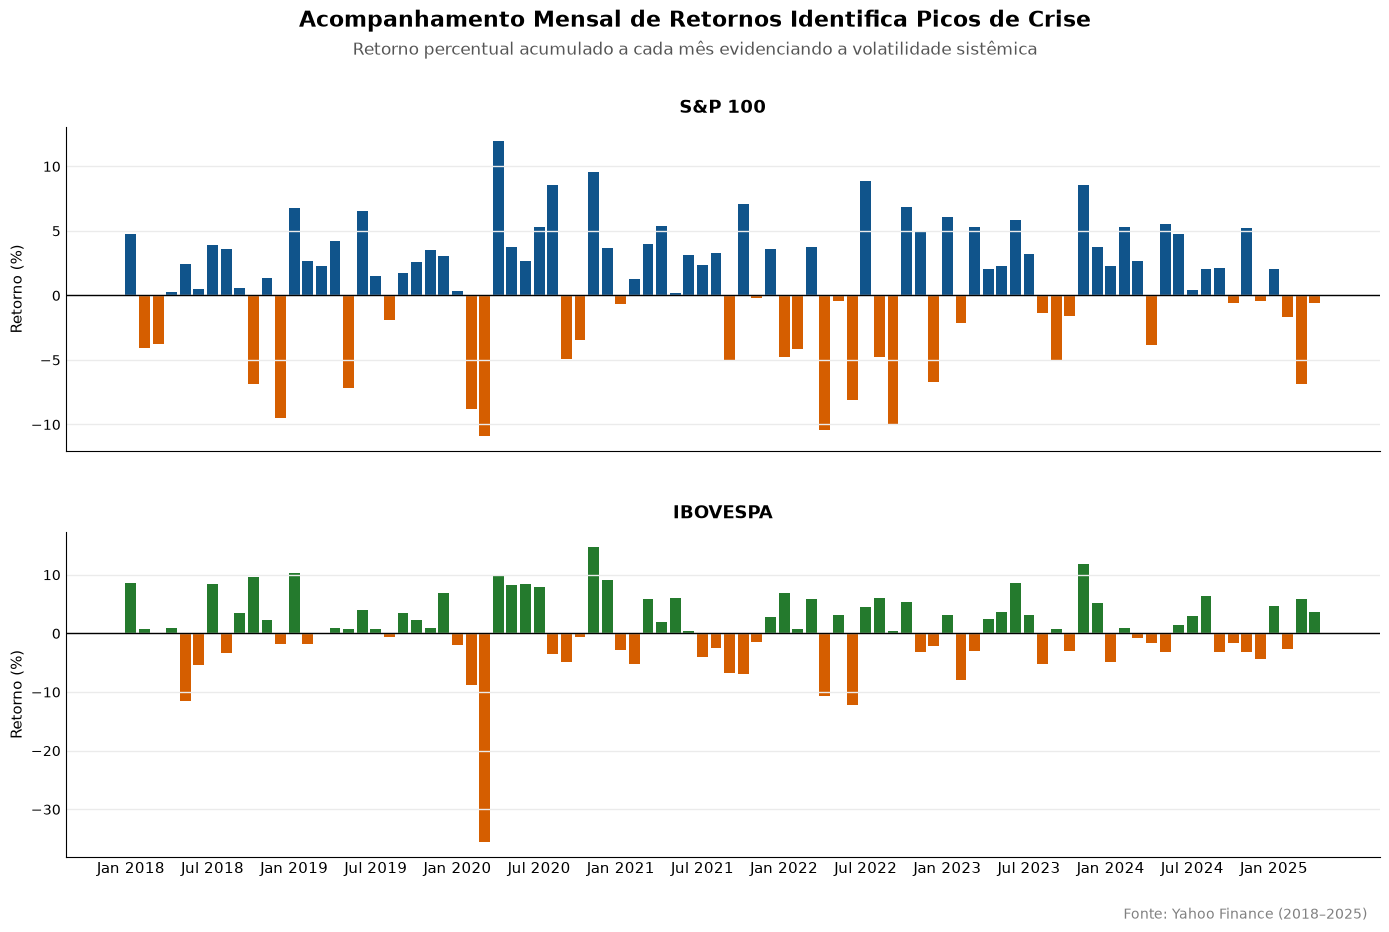

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Títulos Gerais
fig.suptitle('Acompanhamento Mensal de Retornos Identifica Picos de Crise', fontsize=16, fontweight='bold', y=0.98)
fig.text(0.5, 0.93, 'Retorno percentual acumulado a cada mês evidenciando a volatilidade sistêmica', ha='center', fontsize=12, color='#555555')

for ax, ret, label, base_color in [
    (axes[0], ret_mensal_sp, 'S&P 100', cor_sp),
    (axes[1], ret_mensal_ib, 'IBOVESPA', cor_ibov)
]:
    # Cor avermelhada se retorno negativo
    cores = [base_color if r > 0 else '#d55e00' for r in ret.values]
    
    ax.bar(range(len(ret)), ret.values * 100, color=cores, edgecolor='none')
    ax.axhline(0, color='black', linewidth=1) # Linha zero bem demarcada
    
    ax.grid(axis='y', color='#ebebeb', linewidth=1)
    ax.grid(axis='x', visible=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', length=0)
    
    ax.set_title(label, fontweight='bold', fontsize=13, pad=10)
    ax.set_ylabel('Retorno (%)', fontsize=11)

# Formatando Eixo X
axes[1].set_xticks(range(0, len(ret_mensal_sp), 6))
axes[1].set_xticklabels(ret_mensal_sp.index[::6].strftime('%b %Y'), rotation=0, fontsize=11)

plt.tight_layout()
plt.subplots_adjust(top=0.85, hspace=0.25)

#Fonte
fig.text(0.98, -0.03, 'Fonte: Yahoo Finance (2018–2025)', ha='right', fontsize=10, color='gray')

plt.savefig('retorno_mensal_indices_final.png', dpi=150, bbox_inches='tight')
plt.show()

In [45]:
correlacoes_com_indice = ret_sp100_clean.corrwith(ret_idx_sp)
top30_tickers_sp = correlacoes_com_indice.nlargest(30).index
corr_top30_sp = ret_sp100_clean[top30_tickers_sp].corr()

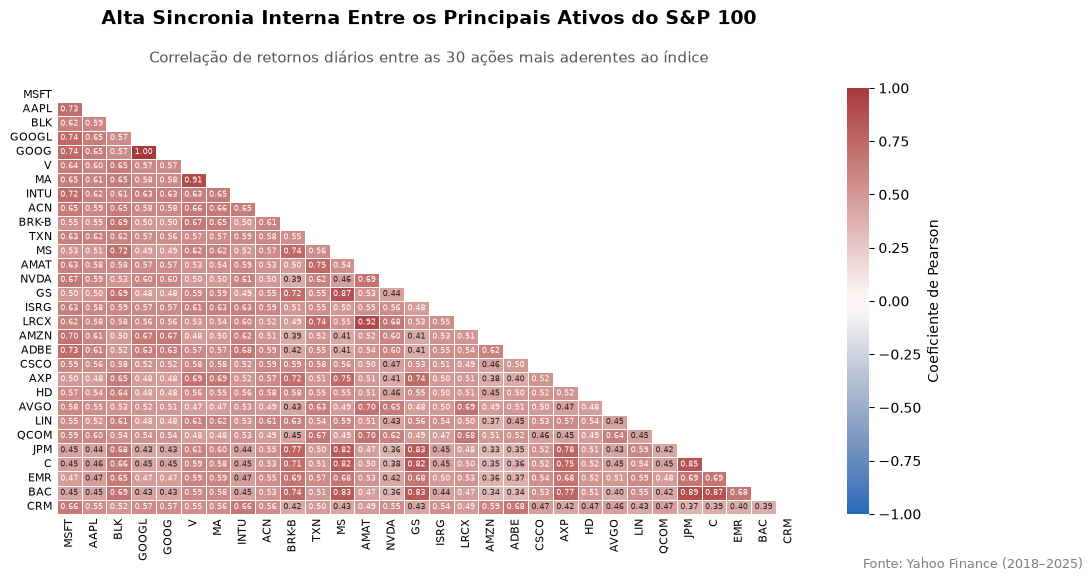

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Cria uma figura mais larga e menos alta (12 por 6)
fig, ax = plt.subplots(figsize=(12, 6)) 

mask_sp = np.triu(np.ones_like(corr_top30_sp, dtype=bool))

sns.heatmap(
    corr_top30_sp, 
    mask=mask_sp, 
    annot=True, # DICA: Mude para False se achar que os números poluem muito a tela
    fmt=".2f", 
    cmap='vlag', 
    center=0, 
    square=False, # <-- O SEGREDO AQUI: Permite que as células fiquem retangulares
    linewidths=0.5, 
    linecolor='white',
    vmin=-1, vmax=1,
    cbar_kws={"shrink": 1.0, "label": "Coeficiente de Pearson"},
    annot_kws={"size": 6}, 
    ax=ax
)

ax.tick_params(axis='both', length=0, labelsize=8)

# Títulos alinhados nativamente (evita sobreposição)
ax.text(0.5, 1.15, 'Alta Sincronia Interna Entre os Principais Ativos do S&P 100', 
        transform=ax.transAxes, ha='center', fontsize=14, fontweight='bold', color='black')
ax.text(0.5, 1.06, 'Correlação de retornos diários entre as 30 ações mais aderentes ao índice', 
        transform=ax.transAxes, ha='center', fontsize=11, color='#555555')

ax.set_xlabel('')
ax.set_ylabel('')

# Aumenta o espaço no topo para os títulos não ficarem cortados
plt.subplots_adjust(top=0.82)

# Fonte ancorada na figura inteira e não no gráfico
fig.text(0.98, 0.02, 'Fonte: Yahoo Finance (2018–2025)', ha='right', fontsize=9, color='gray')

plt.savefig('heatmap_sp100_widescreen.png', dpi=200, bbox_inches='tight')
plt.show()

In [47]:
# 1. Calcular a correlação usando a base de dados LIMPA
correlacoes_com_indice_ib = ret_ibov_clean.corrwith(ret_idx_ib)

# 2. Selecionar os tickers das 30 ações com a maior correlação (mais aderentes)
top30_tickers_ib = correlacoes_com_indice_ib.nlargest(30).index

# 3. Calcular a matriz de correlação interna cruzada entre essas 30 ações
corr_top30_ibov = ret_ibov_clean[top30_tickers_ib].corr()

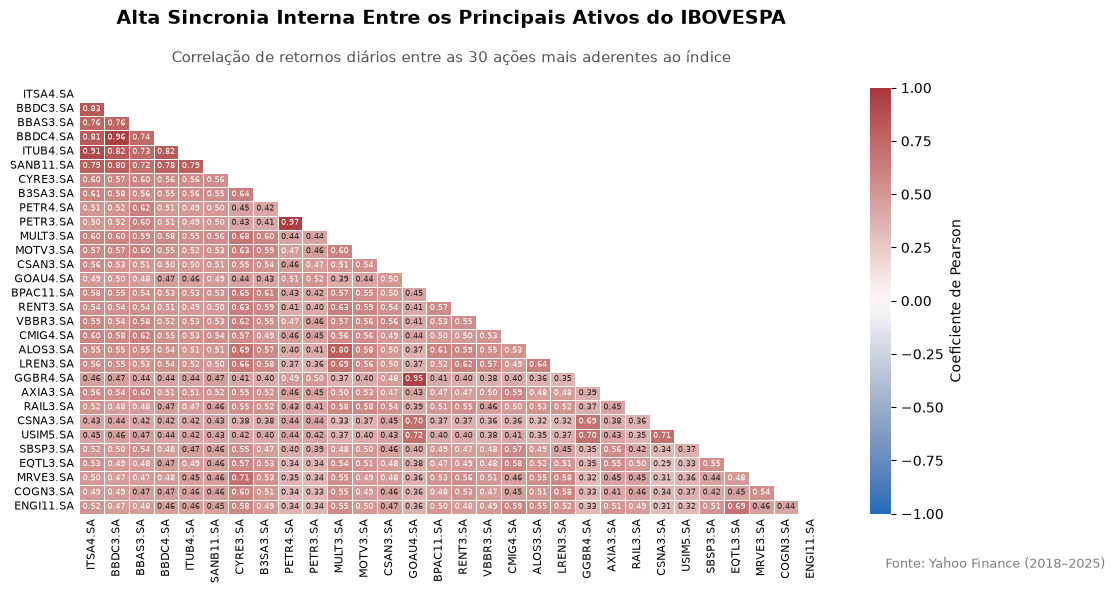

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(12, 6))

mask_ibov = np.triu(np.ones_like(corr_top30_ibov, dtype=bool))

sns.heatmap(
    corr_top30_ibov, 
    mask=mask_ibov, 
    annot=True, 
    fmt=".2f", 
    cmap='vlag', 
    center=0, 
    square=False, 
    linewidths=0.5, 
    linecolor='white',
    vmin=-1, vmax=1,
    cbar_kws={"shrink": 1.0, "label": "Coeficiente de Pearson"},
    annot_kws={"size": 6},
    ax=ax
)

ax.tick_params(axis='both', length=0, labelsize=8)

# CORREÇÃO: Ambos os títulos ancorados no centro exato do gráfico (0.5)
ax.text(0.5, 1.15, 'Alta Sincronia Interna Entre os Principais Ativos do IBOVESPA', 
        transform=ax.transAxes, ha='center', fontsize=14, fontweight='bold', color='black')
ax.text(0.5, 1.06, 'Correlação de retornos diários entre as 30 ações mais aderentes ao índice', 
        transform=ax.transAxes, ha='center', fontsize=11, color='#555555')

ax.set_xlabel('')
ax.set_ylabel('')

# Aumenta o espaço no topo para os títulos não ficarem cortados
plt.subplots_adjust(top=0.82)

# Fonte posicionada em relação à figura inteira
fig.text(0.98, 0.02, 'Fonte: Yahoo Finance (2018–2025)', ha='right', fontsize=9, color='gray')

plt.savefig('heatmap_ibov_widescreen_final.png', dpi=200, bbox_inches='tight')
plt.show()

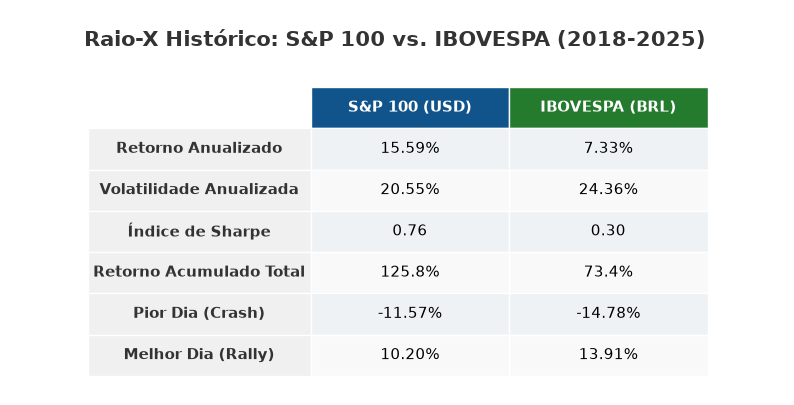

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Alinhar datas APENAS para os cálculos de Risco e Volatilidade
datas_comuns_idx = ret_idx_sp.index.intersection(ret_idx_ib.index)
sp_al = ret_idx_sp.loc[datas_comuns_idx]
ib_al = ret_idx_ib.loc[datas_comuns_idx]

# 2. CALCULAR O RETORNO ACUMULADO REAL (A correção da distorção do Log)
sp_ret_total = (np.exp(ret_idx_sp.sum()) - 1) * 100
ib_ret_total = (np.exp(ret_idx_ib.sum()) - 1) * 100

sp_pior = (np.exp(sp_al.min()) - 1) * 100
sp_melhor = (np.exp(sp_al.max()) - 1) * 100
ib_pior = (np.exp(ib_al.min()) - 1) * 100
ib_melhor = (np.exp(ib_al.max()) - 1) * 100

# 3. TRUQUE DE ALINHAMENTO: Colocar os rótulos como a primeira coluna do DataFrame
resumo = pd.DataFrame({
    '': [ # Coluna de Rótulos (sem título no topo)
        'Retorno Anualizado', 
        'Volatilidade Anualizada', 
        'Índice de Sharpe', 
        'Retorno Acumulado Total', 
        'Pior Dia (Crash)', 
        'Melhor Dia (Rally)'
    ],
    'S&P 100 (USD)': [
        f"{sp_al.mean()*252*100:.2f}%",
        f"{sp_al.std()*np.sqrt(252)*100:.2f}%",
        f"{(sp_al.mean()/sp_al.std()*np.sqrt(252)):.2f}",
        f"{sp_ret_total:.1f}%", 
        f"{sp_pior:.2f}%",
        f"{sp_melhor:.2f}%"
    ],
    'IBOVESPA (BRL)': [
        f"{ib_al.mean()*252*100:.2f}%",
        f"{ib_al.std()*np.sqrt(252)*100:.2f}%",
        f"{(ib_al.mean()/ib_al.std()*np.sqrt(252)):.2f}",
        f"{ib_ret_total:.1f}%", 
        f"{ib_pior:.2f}%",
        f"{ib_melhor:.2f}%"
    ]
})

# 4. Exportar a tabela estilizada e 100% centralizada
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('off')

# Como agora são 3 colunas "reais", o bbox centraliza o bloco inteiro perfeitamente
# ColWidths garante que a coluna dos textos seja um bocadinho mais larga para caber bem
table = ax.table(cellText=resumo.values, 
                 colLabels=resumo.columns, 
                 cellLoc='center', 
                 bbox=[0.10, 0.05, 0.80, 0.75],
                 colWidths=[0.36, 0.32, 0.32]) 

table.auto_set_font_size(False)
table.set_fontsize(11)

cor_sp = '#10548b'
cor_ibov = '#247a2d'

# Pintar as células
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('white') 
    
    # Linha do Cabeçalho
    if row == 0:
        if col == 0:
            cell.set_facecolor('white') # O canto superior esquerdo fica vazio
        elif col == 1:
            cell.set_facecolor(cor_sp)
            cell.set_text_props(weight='bold', color='white')
        elif col == 2:
            cell.set_facecolor(cor_ibov)
            cell.set_text_props(weight='bold', color='white')
            
    # Restante da tabela
    else:
        if col == 0: # Rótulos (agora na coluna 0)
            cell.set_facecolor('#f0f0f0')
            cell.set_text_props(weight='bold', color='#333333')
        else: # Dados numéricos (Efeito Zebra)
            if row % 2 == 0:
                cell.set_facecolor('#f9f9f9')
            else:
                cell.set_facecolor('#eef2f5')

# Título perfeitamente alinhado com o eixo central da tabela inteira
fig.text(0.51, 0.82, 'Raio-X Histórico: S&P 100 vs. IBOVESPA (2018-2025)', 
         ha='center', va='center', fontweight='bold', fontsize=15, color='#333333')

plt.savefig('tabela_resumo_final.png', dpi=200)
plt.show()

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

TRAIN_END  = '2022-12-31'
VAL_START, VAL_END = '2023-01-01', '2023-12-31'
TEST_START = '2024-01-01'
CAP = 0.10      # teto de peso por ação
ANO = 252


def cap_viavel(cap, k):
    """Garante k*cap >= 1; senão a soma dos pesos nunca chega a 100% (problema inviável)."""
    return max(cap, 1.2 / k)


def resolver_pesos(S, c, cap):
    """Min w'Sw - 2c'w  s.t. 0 <= w <= cap, sum(w) = 1 (gradiente analítico)."""
    k = len(c)
    cap = cap_viavel(cap, k)
    res = minimize(lambda w: w @ S @ w - 2 * c @ w, np.full(k, 1.0 / k),
                   jac=lambda w: 2 * (S @ w - c), method='SLSQP',
                   bounds=[(0.0, cap)] * k,
                   constraints=[{'type': 'eq', 'fun': lambda w: w.sum() - 1.0,
                                 'jac': lambda w: np.ones(k)}],
                   options={'ftol': 1e-12, 'maxiter': 500})
    w = np.clip(res.x, 0.0, cap)
    if (not np.all(np.isfinite(res.x))) or abs(res.x.sum() - 1) > 1e-4 or w.sum() <= 0:
        return np.full(k, 1.0 / k)          # fallback seguro
    return w / w.sum()


def pre_computar(X, y):
    """Covariâncias (dados centrados, em %) calculadas UMA vez: S=cov(X), c=cov(X,y), bb=var(y)."""
    A = (X.values - X.values.mean(axis=0)) * 100
    b = (y.values - y.values.mean()) * 100
    n = len(b)
    return A.T @ A / n, A.T @ b / n, float(b @ b / n)


def te_de(S, c, bb, ix, cap):
    """TE anualizado (%) e pesos ótimos para o subconjunto ix, sem tocar nos dados brutos."""
    ix = list(ix)
    Ss, cs = S[np.ix_(ix, ix)], c[ix]
    w = resolver_pesos(Ss, cs, cap)
    var = w @ Ss @ w - 2 * cs @ w + bb
    return np.sqrt(max(var, 0.0) * ANO), w


def retorno_carteira(X_log, w):
    """Retorno log diário de carteira buy-and-hold (pesos w no início do bloco, sem rebalancear).
    Agrega em retorno SIMPLES entre ativos (log não é aditivo entre ativos)."""
    R = np.expm1(X_log[list(w.index)])
    v = (1 + R).cumprod().values @ w.values
    v_ant = np.concatenate([[1.0], v[:-1]])
    return pd.Series(np.log(v / v_ant), index=X_log.index)


def metricas(r, y):
    dif = r - y
    return {'TE (%)': dif.std() * np.sqrt(ANO) * 100,
            'TD (% a.a.)': dif.mean() * ANO * 100,
            'Corr': r.corr(y),
            'R²': 1 - dif.var() / y.var()}


def filtrar_candidatas(Xtr, ytr, corr_min=0.50, limite_par=0.90):
    ci = Xtr.corrwith(ytr)
    cand = ci[ci >= corr_min].sort_values(ascending=False).index.tolist()
    if len(cand) < 2:
        return cand
    C = np.abs(np.corrcoef(Xtr[cand].values, rowvar=False))
    mant = []
    for i in range(len(cand)):
        if all(C[i, j] < limite_par for j in mant):
            mant.append(i)
    return [cand[i] for i in mant]


def ag_selecao(S, c, bb, K, cap=CAP, pop=60, geracoes=60, p_cx=0.8, p_mut=0.3,
               n_elite=2, paciencia=15, seed=0):
    """AG para seleção de K ativos: elitismo, cruzamento por conjunto e mutação por troca (K sempre preservado)."""
    rng = np.random.default_rng(seed)
    N = len(c)
    if N <= K:
        return list(range(N)), te_de(S, c, bb, range(N), cap)[0], []
    cache = {}

    def fit(ind):
        if ind not in cache:
            cache[ind] = te_de(S, c, bb, ind, cap)[0]
        return cache[ind]

    def novo():
        return tuple(sorted(int(i) for i in rng.choice(N, K, replace=False)))

    def torneio(P, F, t=3):
        cand = rng.integers(0, len(P), t)
        return P[min(cand, key=lambda i: F[i])]

    def cruzar(a, b):
        sa, sb = set(a), set(b)
        comum = sa & sb
        resto = list(sa ^ sb)
        rng.shuffle(resto)
        return tuple(sorted(comum | set(resto[:K - len(comum)])))

    def mutar(ind):
        s = set(ind)
        for _ in range(int(rng.integers(1, 3))):
            sai = int(rng.choice(list(s)))
            livres = [j for j in range(N) if j not in s]
            s.remove(sai)
            s.add(int(rng.choice(livres)))
        return tuple(sorted(s))

    P = [novo() for _ in range(pop)]
    melhor, sem_melhora, hist = np.inf, 0, []
    for g in range(geracoes):
        F = [fit(i) for i in P]
        ordem = np.argsort(F)
        P, F = [P[i] for i in ordem], [F[i] for i in ordem]
        hist.append(F[0])
        if F[0] < melhor - 1e-4:
            melhor, sem_melhora = F[0], 0
        else:
            sem_melhora += 1
        if sem_melhora >= paciencia:
            break
        filhos = P[:n_elite]
        while len(filhos) < pop:
            a, b = torneio(P, F), torneio(P, F)
            f = cruzar(a, b) if rng.random() < p_cx else a
            if rng.random() < p_mut:
                f = mutar(f)
            filhos.append(f)
        P = filhos
    F = [fit(i) for i in P]
    i = int(np.argmin(F))
    return list(P[i]), F[i], hist


def selecao_gulosa(S, c, bb, K, cap=CAP):
    """Forward selection: a cada passo adiciona o ativo que mais reduz o TE."""
    sel, restante = [], list(range(len(c)))
    for _ in range(K):
        j = min(restante, key=lambda j: te_de(S, c, bb, sel + [j], cap)[0])
        sel.append(j)
        restante.remove(j)
    return sel


def selecionar(Xtr, ytr, K, cap=CAP, metodo='ag', seed=0, **kw):
    """metodo: 'ag' | 'guloso' | 'topcorr' | 'aleatorio'"""
    cand = filtrar_candidatas(Xtr, ytr)
    if len(cand) <= K:
        return [str(x) for x in cand]
    if metodo == 'topcorr':
        return [str(x) for x in cand[:K]]
    if metodo == 'aleatorio':
        rng = np.random.default_rng(seed)
        return [str(x) for x in rng.choice(cand, K, replace=False)]
    S, c, bb = pre_computar(Xtr[cand], ytr)
    ix = selecao_gulosa(S, c, bb, K, cap) if metodo == 'guloso' else ag_selecao(S, c, bb, K, cap, seed=seed, **kw)[0]
    return [str(cand[i]) for i in ix]


def pesos_para(Xtr, ytr, nomes, cap=CAP):
    S, c, bb = pre_computar(Xtr[nomes], ytr)
    return pd.Series(resolver_pesos(S, c, cap), index=nomes)
print('✅ Funções carregadas')

✅ Funções carregadas


In [51]:
def preparar_dados(ret_trata, ret_clean, ret_idx):
    """Xfit: retornos winsorizados (só para AJUSTAR). Xraw: retornos reais (para AVALIAR)."""
    y = ret_idx.squeeze()
    datas = ret_clean.index.intersection(y.index)
    return {'Xfit': ret_trata.loc[datas, ret_clean.columns],
            'Xraw': ret_clean.loc[datas],
            'y': y.loc[datas]}


def resumo_split(D, nome):
    for rot, (a, b) in {'Treino': (None, TRAIN_END), 'Validação': (VAL_START, VAL_END),
                        'Teste': (TEST_START, None)}.items():
        idx = D['y'].loc[a:b].index
        print(f'{nome:9s} | {rot:9s}: {idx[0].date()} a {idx[-1].date()} ({len(idx)} pregões)')
    assert D['Xraw'].isnull().sum().sum() == 0 and D['y'].isnull().sum() == 0, 'Há NaN nos dados!'


D_sp = preparar_dados(ret_sp100_trata, ret_sp100_clean, ret_idx_sp)
D_ib = preparar_dados(ret_ibov_trata, ret_ibov_clean, ret_idx_ib)
resumo_split(D_sp, 'S&P 100')
resumo_split(D_ib, 'IBOVESPA')

S&P 100   | Treino   : 2018-01-03 a 2022-12-30 (1258 pregões)
S&P 100   | Validação: 2023-01-03 a 2023-12-29 (250 pregões)
S&P 100   | Teste    : 2024-01-02 a 2025-04-30 (333 pregões)
IBOVESPA  | Treino   : 2018-04-27 a 2022-12-29 (1159 pregões)
IBOVESPA  | Validação: 2023-01-02 a 2023-12-28 (248 pregões)
IBOVESPA  | Teste    : 2024-01-02 a 2025-04-30 (332 pregões)


  S&P 100 K=8 ok
  S&P 100 K=10 ok
  S&P 100 K=15 ok
  S&P 100 K=20 ok
  S&P 100 K=25 ok
  S&P 100 K=30 ok
  IBOVESPA K=8 ok
  IBOVESPA K=10 ok
  IBOVESPA K=15 ok
  IBOVESPA K=20 ok
  IBOVESPA K=25 ok
  IBOVESPA K=30 ok
    AG (média)  AG (dp)  Guloso  Top-corr
K                                        
8         4.69     0.18    4.91      5.32
10        4.37     0.15    4.44      5.11
15        3.73     0.05    3.69      4.57
20        3.18     0.14    3.18      4.13
25        2.60     0.14    2.79      3.83
30        2.30     0.05    2.47      3.85
    AG (média)  AG (dp)  Guloso  Top-corr
K                                        
8         5.83     0.56    5.86      8.42
10        5.78     0.12    5.38      7.76
15        4.43     0.08    4.82      6.15
20        3.85     0.07    3.93      5.53
25        3.62     0.03    3.64      5.19
30        3.35     0.01    3.36      3.87


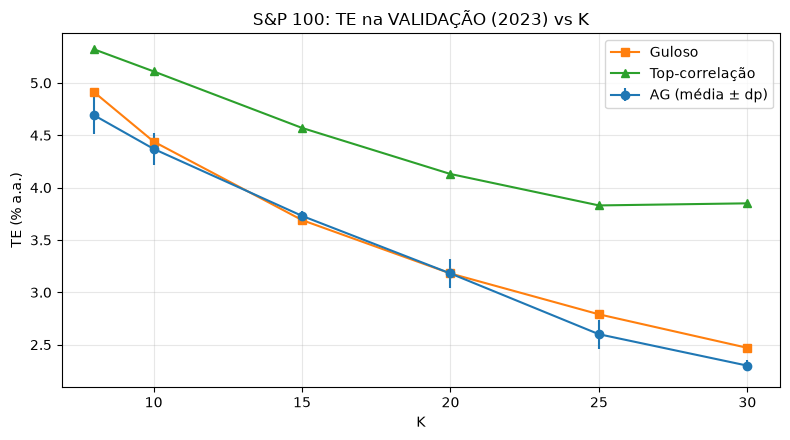

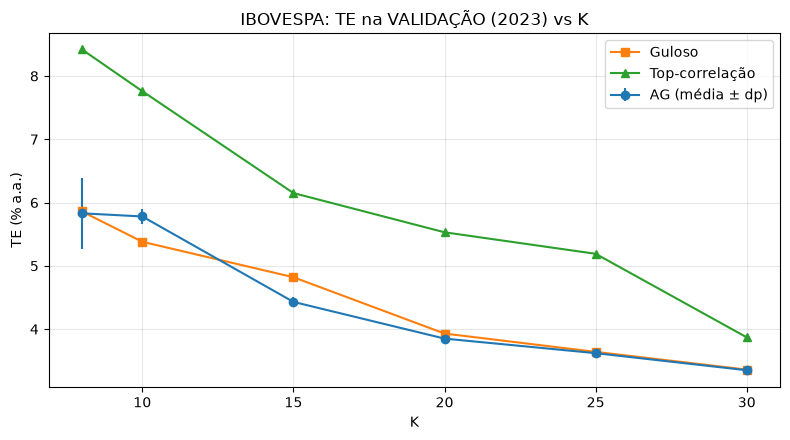

In [52]:
def avaliar_K_validacao(D, nome, Ks=(8, 10, 15, 20, 25, 30), seeds=(0, 1, 2), cap=CAP):
    Xtr, ytr = D['Xfit'].loc[:TRAIN_END], D['y'].loc[:TRAIN_END]
    Xva, yva = D['Xraw'].loc[VAL_START:VAL_END], D['y'].loc[VAL_START:VAL_END]
    linhas = []
    for K in Ks:
        te_ag = []
        for s in seeds:
            nomes = selecionar(Xtr, ytr, K, cap, 'ag', seed=s)
            te_ag.append(metricas(retorno_carteira(Xva, pesos_para(Xtr, ytr, nomes, cap)), yva)['TE (%)'])
        linha = {'K': K, 'AG (média)': np.mean(te_ag), 'AG (dp)': np.std(te_ag)}
        for met, rot in (('guloso', 'Guloso'), ('topcorr', 'Top-corr')):
            nomes = selecionar(Xtr, ytr, K, cap, met)
            linha[rot] = metricas(retorno_carteira(Xva, pesos_para(Xtr, ytr, nomes, cap)), yva)['TE (%)']
        linhas.append(linha)
        print(f'  {nome} K={K} ok')
    return pd.DataFrame(linhas).set_index('K').round(2)


def plot_K(df, nome):
    plt.figure(figsize=(8, 4.5))
    plt.errorbar(df.index, df['AG (média)'], yerr=df['AG (dp)'], marker='o', label='AG (média ± dp)')
    plt.plot(df.index, df['Guloso'], marker='s', label='Guloso')
    plt.plot(df.index, df['Top-corr'], marker='^', label='Top-correlação')
    plt.title(f'{nome}: TE na VALIDAÇÃO (2023) vs K'); plt.xlabel('K'); plt.ylabel('TE (% a.a.)')
    plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()


res_K_sp = avaliar_K_validacao(D_sp, 'S&P 100')
res_K_ib = avaliar_K_validacao(D_ib, 'IBOVESPA')
print(res_K_sp); print(res_K_ib)
plot_K(res_K_sp, 'S&P 100'); plot_K(res_K_ib, 'IBOVESPA')

⏳ S&P 100: AG...
⏳ S&P 100: baselines + modelo nulo (200 sorteios)...

=== S&P 100 | TESTE 2024+ | K=20 ===
                     AG (média das sementes)  Guloso  Top-correlação
TE (%)                                 4.305   4.611           5.289
TD (% a.a.)                            4.199   3.390           1.180
Corr                                   0.975   0.971           0.962
R²                                     0.949   0.941           0.923
Turnover/rebal. (%)                   28.853  31.054          18.392
TE do AG por semente: [4.33 4.24 4.34] (dp=0.04)
IC 95% (block bootstrap) do TE do AG, semente 0: [3.99, 4.66]
Modelo nulo (seleção aleatória, mesmo pipeline): média=6.90 | p5=6.10 | p-valor do AG=0.000


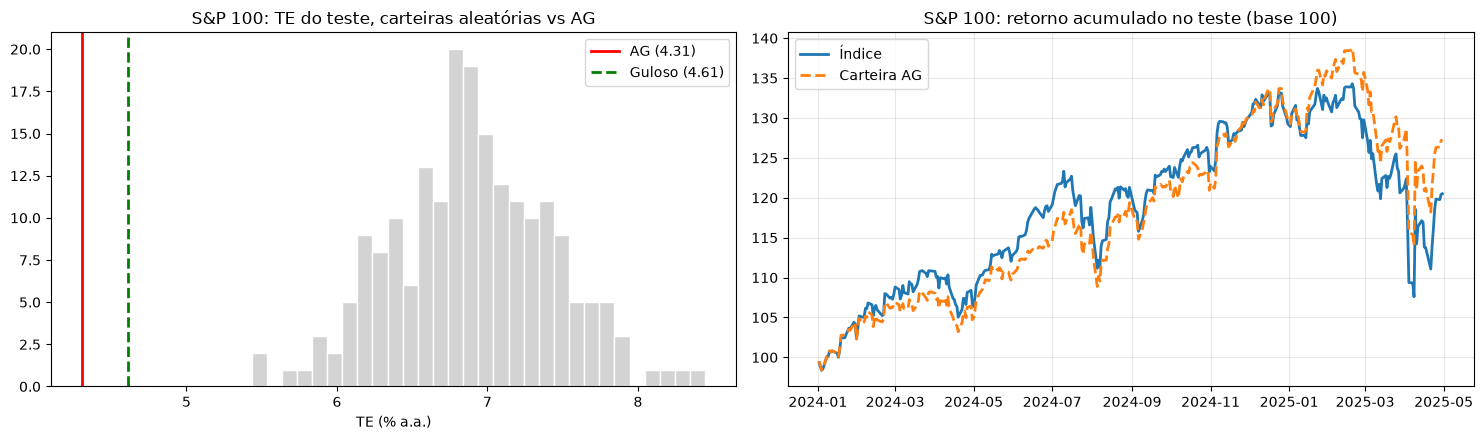

Ações no último rebalanceamento (AG, semente 0): ['MSFT', 'AAPL', 'AMZN', 'NVDA', 'GOOGL', 'META', 'AVGO', 'BRK-B', 'V', 'COST', 'HD', 'LIN', 'EMR', 'BNY', 'CSCO', 'TSLA', 'ORCL', 'JPM', 'GE', 'ABT']
⏳ IBOVESPA: AG...
⏳ IBOVESPA: baselines + modelo nulo (200 sorteios)...

=== IBOVESPA | TESTE 2024+ | K=20 ===
                     AG (média das sementes)  Guloso  Top-correlação
TE (%)                                 4.008   4.024           7.474
TD (% a.a.)                           -4.857  -5.810          -5.256
Corr                                   0.970   0.971           0.931
R²                                     0.921   0.921           0.726
Turnover/rebal. (%)                   29.514  32.678          21.614
TE do AG por semente: [4.   4.02 4.  ] (dp=0.01)
IC 95% (block bootstrap) do TE do AG, semente 0: [3.56, 4.43]
Modelo nulo (seleção aleatória, mesmo pipeline): média=6.36 | p5=5.26 | p-valor do AG=0.000


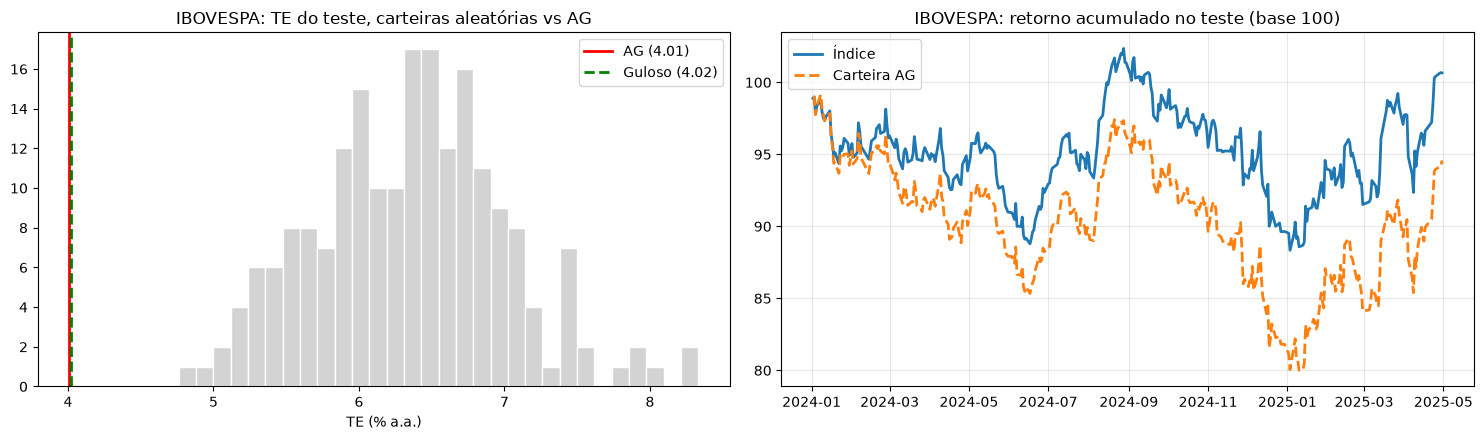

Ações no último rebalanceamento (AG, semente 0): ['ITSA4.SA', 'BPAC11.SA', 'B3SA3.SA', 'RENT3.SA', 'VBBR3.SA', 'BBDC3.SA', 'SANB11.SA', 'BBAS3.SA', 'AXIA3.SA', 'CSNA3.SA', 'ENEV3.SA', 'TOTS3.SA', 'RAIL3.SA', 'GOAU4.SA', 'BRAP4.SA', 'PETR3.SA', 'EQTL3.SA', 'HAPV3.SA', 'SBSP3.SA', 'FLRY3.SA']


In [53]:
K_SP, K_IB = 20, 20       # <- ajuste depois de olhar as tabelas da validação (N3)

def backtest_wf(D, K, metodo='ag', seed=0, cap=CAP, freq_meses=6, janela_anos=3, reselecionar=True):
    Xte = D['Xraw'].loc[TEST_START:]
    datas = Xte.index
    rebal = [datas[0]]
    while True:
        fut = datas[datas >= rebal[-1] + pd.DateOffset(months=freq_meses)]
        if len(fut) == 0:
            break
        rebal.append(fut[0])
    rets, turn, hist, nomes, w_fim = [], [], [], None, None
    for i, ini in enumerate(rebal):
        fim = rebal[i + 1] if i + 1 < len(rebal) else None
        bloco = Xte.loc[ini:fim]
        if fim is not None:
            bloco = bloco.iloc[:-1]
        ini_tr = ini - pd.DateOffset(years=janela_anos)
        Xtr = D['Xfit'].loc[ini_tr:ini].iloc[:-1]       # só dados ANTERIORES ao rebalanceamento
        ytr = D['y'].loc[ini_tr:ini].iloc[:-1]
        if nomes is None or reselecionar:
            nomes = selecionar(Xtr, ytr, K, cap, metodo, seed=seed + i)
        w = pesos_para(Xtr, ytr, nomes, cap)
        if w_fim is not None:
            u = w.index.union(w_fim.index)
            turn.append(0.5 * (w.reindex(u, fill_value=0) - w_fim.reindex(u, fill_value=0)).abs().sum())
        rets.append(retorno_carteira(bloco, w))
        g = (1 + np.expm1(bloco[list(w.index)])).prod()
        w_fim = w * g
        w_fim = w_fim / w_fim.sum()
        hist.append(list(nomes))
    r = pd.concat(rets)
    m = metricas(r, D['y'].loc[r.index])
    m['Turnover/rebal. (%)'] = np.mean(turn) * 100 if turn else np.nan
    return r, m, hist


def ic_te_bloco(dif, bloco=21, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    d = dif.values; T = len(d); nb = int(np.ceil(T / bloco))
    tes = []
    for _ in range(n):
        st = rng.integers(0, T - bloco + 1, nb)
        a = np.concatenate([d[s:s + bloco] for s in st])[:T]
        tes.append(a.std(ddof=1) * np.sqrt(ANO) * 100)
    return np.percentile(tes, [2.5, 97.5])


def comparar_modelos(D, nome, K, seeds=(0, 1, 2), n_nulo=200, cap=CAP):
    print(f'⏳ {nome}: AG...')
    ag = [backtest_wf(D, K, 'ag', seed=s * 100, cap=cap) for s in seeds]
    print(f'⏳ {nome}: baselines + modelo nulo ({n_nulo} sorteios)...')
    gu = backtest_wf(D, K, 'guloso', cap=cap)
    tc = backtest_wf(D, K, 'topcorr', cap=cap)
    nulo = np.array([backtest_wf(D, K, 'aleatorio', seed=1000 + 10 * s, cap=cap)[1]['TE (%)'] for s in range(n_nulo)])

    te_ag = np.array([a[1]['TE (%)'] for a in ag])
    r_ag, y_te = ag[0][0], D['y'].loc[ag[0][0].index]
    lo, hi = ic_te_bloco(r_ag - y_te)
    p_val = (nulo <= te_ag.mean()).mean()

    tabela = pd.DataFrame({
        'AG (média das sementes)': pd.Series({k: np.mean([a[1][k] for a in ag]) for k in ag[0][1]}),
        'Guloso': pd.Series(gu[1]),
        'Top-correlação': pd.Series(tc[1]),
    }).round(3)
    print(f'\n=== {nome} | TESTE {TEST_START[:4]}+ | K={K} ===')
    print(tabela.to_string())
    print(f'TE do AG por semente: {np.round(te_ag, 2)} (dp={te_ag.std():.2f})')
    print(f'IC 95% (block bootstrap) do TE do AG, semente 0: [{lo:.2f}, {hi:.2f}]')
    print(f'Modelo nulo (seleção aleatória, mesmo pipeline): média={nulo.mean():.2f} | p5={np.percentile(nulo, 5):.2f} | p-valor do AG={p_val:.3f}')

    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    ax[0].hist(nulo, bins=30, color='lightgray', edgecolor='white')
    ax[0].axvline(te_ag.mean(), color='red', lw=2, label=f'AG ({te_ag.mean():.2f})')
    ax[0].axvline(gu[1]['TE (%)'], color='green', ls='--', lw=2, label=f'Guloso ({gu[1]["TE (%)"]:.2f})')
    ax[0].set_title(f'{nome}: TE do teste, carteiras aleatórias vs AG'); ax[0].set_xlabel('TE (% a.a.)'); ax[0].legend()
    ax[1].plot(np.exp(y_te.cumsum()) * 100, label='Índice', lw=2)
    ax[1].plot(np.exp(r_ag.cumsum()) * 100, '--', label='Carteira AG', lw=2)
    ax[1].set_title(f'{nome}: retorno acumulado no teste (base 100)'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()
    print('Ações no último rebalanceamento (AG, semente 0):', ag[0][2][-1])
    return {'tabela': tabela, 'te_ag': te_ag, 'nulo': nulo, 'ag': ag, 'guloso': gu, 'topcorr': tc}


res_final_sp = comparar_modelos(D_sp, 'S&P 100', K_SP)
res_final_ib = comparar_modelos(D_ib, 'IBOVESPA', K_IB)

In [54]:
# 1) A deriva é sistemática (dados/estrutura) ou específica do AG?
td_nulo = np.array([backtest_wf(D_ib, K_IB, 'aleatorio', seed=1000 + 10*s)[1]['TD (% a.a.)'] for s in range(100)])
print(f'TD das carteiras aleatórias: média={td_nulo.mean():.2f} | p5={np.percentile(td_nulo,5):.2f} | p95={np.percentile(td_nulo,95):.2f}')

r = res_final_ib['ag'][0][0]
dif = r - D_ib['y'].loc[r.index]
anos = len(r) / 252
td = dif.mean() * 252 * 100
print(f'TD do AG = {td:.2f}% a.a. | t ≈ {td / (dif.std()*np.sqrt(252)*100/np.sqrt(anos)):.2f}')

# 2) Os dividendos/JCP estão nos dados do Yahoo para ações .SA?
print(yf.Ticker('ITUB4.SA').dividends['2024':].round(3))

TD das carteiras aleatórias: média=-5.40 | p5=-9.43 | p95=-1.75
TD do AG = -4.73% a.a. | t ≈ -1.36
Date
2024-01-02 10:00:00-03:00    0.016
2024-02-01 10:00:00-03:00    0.016
2024-02-22 10:00:00-03:00    0.993
2024-03-01 10:00:00-03:00    0.016
2024-03-22 10:00:00-03:00    0.213
2024-04-01 10:00:00-03:00    0.016
2024-05-02 10:00:00-03:00    0.016
2024-06-03 10:00:00-03:00    0.016
2024-06-21 10:00:00-03:00    0.222
2024-07-01 10:00:00-03:00    0.016
2024-08-01 10:00:00-03:00    0.016
2024-09-02 10:00:00-03:00    0.016
2024-09-20 10:00:00-03:00    0.241
2024-10-01 10:00:00-03:00    0.016
2024-11-01 10:00:00-03:00    0.016
2024-12-02 10:00:00-03:00    0.016
2024-12-10 10:00:00-03:00    0.274
2025-01-02 10:00:00-03:00    0.016
2025-02-03 10:00:00-03:00    0.016
2025-02-18 10:00:00-03:00    1.398
2025-03-05 13:00:00-03:00    0.016
2025-04-01 10:00:00-03:00    0.017
2025-05-02 10:00:00-03:00    0.017
2025-06-02 10:00:00-03:00    0.017
2025-06-10 10:00:00-03:00    0.324
2025-07-01 10:00:00-0

In [55]:
# 1) A deriva aparece só em 2024-25 ou em todos os anos?
ew_log = np.log1p(np.expm1(ret_ibov_clean).mean(axis=1))      # equal-weight do universo elegível
dif = ew_log - ret_idx_ib.squeeze().loc[ew_log.index]
print((dif.groupby(dif.index.year).mean() * 252 * 100).round(2))

# 2) O preço ajustado do Yahoo está incorporando os dividendos?
raw = yf.download('ITUB4.SA', start='2024-01-01', end='2025-05-01', auto_adjust=False, progress=False)
fator = (raw['Adj Close'] / raw['Close']).squeeze()
print(f'Ajuste acumulado por proventos no período: {(fator.iloc[-1] / fator.iloc[0] - 1) * 100:.1f}%')

Date
2018     8.93
2019    20.01
2020     9.09
2021     8.63
2022    -0.96
2023    10.16
2024    -4.95
2025    17.30
dtype: float64
Ajuste acumulado por proventos no período: 12.6%


In [56]:
CFG_BASE = dict(
    K=20, cap=0.10,            # restrições do problema (fixas, não entram na busca)
    metodo='ag',               # 'ag' | 'guloso'
    janela_anos=3,             # janela de treino de cada rebalanceamento
    halflife=None,             # None = pesos iguais; ou meia-vida em dias (ex.: 126, 252)
    shrink=0.0,                # 0-1: encolhimento da covariância para correlação constante (reduz ruído)
    cv_blocos=0,               # 0 = fitness no treino todo; 4 = fitness por validação cruzada em blocos
    lam_turn=0.0,              # penaliza mudança de pesos (reduz turnover)
    gamma_troca=0.0,           # penaliza trocar de ações no AG (pp de TE por 100% de troca)
    freq_meses=6,              # frequência de rebalanceamento
    corr_min=0.50, limite_par=0.90,   # filtro de candidatas (corr_min=-1 desliga o filtro de correlação)
)


def encolher(C, d):
    """Encolhe a covariância CONJUNTA (ações + índice) para um alvo de correlação constante.
    Mantém variâncias e a correlação média (fator de mercado), reduz só o ruído das correlações individuais."""
    if d <= 0:
        return C
    sd = np.sqrt(np.diag(C))
    R = C / np.outer(sd, sd)
    n = len(C)
    rbar = (R.sum() - n) / (n * (n - 1))
    F = rbar * np.outer(sd, sd)
    np.fill_diagonal(F, np.diag(C))
    return (1 - d) * C + d * F


def momentos(X, y, halflife=None, shrink=0.0):
    """Covariâncias ponderadas (meia-vida opcional) e com encolhimento opcional. Mesma escala da pre_computar."""
    Z = np.column_stack([X.values, y.values]) * 100
    T = len(Z)
    if halflife:
        w = 0.5 ** ((T - 1 - np.arange(T)) / halflife)
        w = w / w.sum()
    else:
        w = np.full(T, 1.0 / T)
    Zc = Z - w @ Z
    C = encolher((Zc * w[:, None]).T @ Zc, shrink)
    return C[:-1, :-1], C[:-1, -1], float(C[-1, -1])


def construir_te_fn(Xw, yw, cand, cfg):
    """Devolve te_fn(ind) -> TE anualizado (%) do subconjunto ind (índices de cand)."""
    cap, sh, F = cfg['cap'], cfg['shrink'], cfg['cv_blocos']
    if F and F >= 2:
        Z = np.column_stack([Xw[cand].values, yw.values]) * 100
        N, T = len(cand), len(Z)
        cortes = np.linspace(0, T, F + 1).astype(int)
        folds = []
        for j in range(F):
            Zj = Z[cortes[j]:cortes[j + 1]]
            folds.append((len(Zj), Zj.mean(0), Zj.T @ Zj / len(Zj)))
        m_all, M_all = Z.mean(0), Z.T @ Z / T

        def te_fn(ind):
            ia = list(ind) + [N]
            mt, Mt = m_all[ia], M_all[np.ix_(ia, ia)]
            vs = []
            for nj, mj, Mj in folds:
                n_tr = T - nj
                m = (T * mt - nj * mj[ia]) / n_tr                        # momentos do treino (demais blocos)
                M = (T * Mt - nj * Mj[np.ix_(ia, ia)]) / n_tr
                C = encolher(M - np.outer(m, m), sh)
                S, c = C[:-1, :-1], C[:-1, -1]
                w = resolver_pesos(S, c, cap)
                Cj = Mj[np.ix_(ia, ia)] - np.outer(mj[ia], mj[ia])       # avalia no bloco de fora
                v = w @ Cj[:-1, :-1] @ w - 2 * Cj[:-1, -1] @ w + Cj[-1, -1]
                vs.append(max(v, 0.0))
            return float(np.sqrt(np.mean(vs) * ANO))
        return te_fn
    S_all, c_all, bb = momentos(Xw[cand], yw, cfg['halflife'], sh)
    return lambda ind: te_de(S_all, c_all, bb, ind, cap)[0]


def ag_selecao2(te_fn, N, K, prev=None, gamma=0.0, pop=60, geracoes=60, p_cx=0.8, p_mut=0.3,
                n_elite=2, paciencia=15, seed=0):
    """AG com warm start na carteira anterior e custo de troca de ações."""
    rng = np.random.default_rng(seed)
    prev_set = set(prev) if prev else set()
    cache = {}

    def fit(ind):
        if ind not in cache:
            pen = gamma * len(set(ind) - prev_set) / K if prev_set else 0.0
            cache[ind] = te_fn(ind) + pen
        return cache[ind]

    def novo():
        return tuple(sorted(int(i) for i in rng.choice(N, K, replace=False)))

    def torneio(P, F, t=3):
        cand = rng.integers(0, len(P), t)
        return P[min(cand, key=lambda i: F[i])]

    def cruzar(a, b):
        sa, sb = set(a), set(b)
        comum = sa & sb
        resto = list(sa ^ sb)
        rng.shuffle(resto)
        return tuple(sorted(comum | set(resto[:K - len(comum)])))

    def mutar(ind):
        s = set(ind)
        for _ in range(int(rng.integers(1, 3))):
            sai = int(rng.choice(list(s)))
            livres = [j for j in range(N) if j not in s]
            s.remove(sai)
            s.add(int(rng.choice(livres)))
        return tuple(sorted(s))

    P = [novo() for _ in range(pop)]
    if prev_set:                                   # warm start: carteira anterior + variações
        base = set(list(prev_set)[:K])
        while len(base) < K:
            base.add(int(rng.integers(0, N)))
        base = tuple(sorted(base))
        P[0] = base
        for i in range(1, max(2, pop // 4)):
            P[i] = mutar(base)
    melhor, sem_melhora = np.inf, 0
    for g in range(geracoes):
        F = [fit(i) for i in P]
        ordem = np.argsort(F)
        P, F = [P[i] for i in ordem], [F[i] for i in ordem]
        if F[0] < melhor - 1e-4:
            melhor, sem_melhora = F[0], 0
        else:
            sem_melhora += 1
        if sem_melhora >= paciencia:
            break
        filhos = P[:n_elite]
        while len(filhos) < pop:
            a, b = torneio(P, F), torneio(P, F)
            f = cruzar(a, b) if rng.random() < p_cx else a
            if rng.random() < p_mut:
                f = mutar(f)
            filhos.append(f)
        P = filhos
    F = [fit(i) for i in P]
    return list(P[int(np.argmin(F))])


def guloso2(te_fn, N, K):
    sel, restante = [], list(range(N))
    for _ in range(K):
        j = min(restante, key=lambda j: te_fn(sel + [j]))
        sel.append(j)
        restante.remove(j)
    return sel


def selecionar_cfg(Xtr, ytr, cfg, prev_names, seed, ag_kw):
    cand = filtrar_candidatas(Xtr, ytr, cfg['corr_min'], cfg['limite_par'])
    K = cfg['K']
    if len(cand) <= K:
        return [str(x) for x in cand]
    te_fn = construir_te_fn(Xtr, ytr, cand, cfg)
    if cfg['metodo'] == 'guloso':
        ix = guloso2(te_fn, len(cand), K)
    else:
        prev_idx = [cand.index(n) for n in prev_names if n in cand] if prev_names else None
        ix = ag_selecao2(te_fn, len(cand), K, prev_idx, cfg['gamma_troca'], seed=seed, **ag_kw)
    return [str(cand[i]) for i in ix]


def pesos_cfg(Xtr, ytr, nomes, cfg, w_prev=None):
    S, c, bb = momentos(Xtr[nomes], ytr, cfg['halflife'], cfg['shrink'])
    lam = cfg['lam_turn'] * np.mean(np.diag(S))
    if w_prev is not None and lam > 0:                 # puxa para os pesos atuais (menos turnover)
        w0 = w_prev.reindex(nomes).fillna(0.0).values
        S = S + lam * np.eye(len(nomes))
        c = c + lam * w0
    return pd.Series(resolver_pesos(S, c, cfg['cap']), index=nomes)


def backtest_cfg(D, cfg, ini_av, fim_av=None, seed=0, ag_kw=None):
    ag_kw = ag_kw or {}
    Xav = D['Xraw'].loc[ini_av:fim_av]
    datas = Xav.index
    rebal = [datas[0]]
    while True:
        fut = datas[datas >= rebal[-1] + pd.DateOffset(months=cfg['freq_meses'])]
        if len(fut) == 0:
            break
        rebal.append(fut[0])
    rets, turns, hist, nomes, w_fim = [], [], [], None, None
    for i, ini in enumerate(rebal):
        fim = rebal[i + 1] if i + 1 < len(rebal) else None
        bloco = Xav.loc[ini:fim]
        if fim is not None:
            bloco = bloco.iloc[:-1]
        ini_tr = ini - pd.DateOffset(years=cfg['janela_anos'])
        Xtr = D['Xfit'].loc[ini_tr:ini].iloc[:-1]            # só dados ANTERIORES ao rebalanceamento
        ytr = D['y'].loc[ini_tr:ini].iloc[:-1]
        nomes = selecionar_cfg(Xtr, ytr, cfg, nomes, seed + i, ag_kw)
        w = pesos_cfg(Xtr, ytr, nomes, cfg, w_fim)
        if w_fim is not None:
            u = w.index.union(w_fim.index)
            t = 0.5 * (w.reindex(u, fill_value=0) - w_fim.reindex(u, fill_value=0)).abs().sum()
            turns.append((ini.year, t))
        rets.append(retorno_carteira(bloco, w))
        g = (1 + np.expm1(bloco[list(w.index)])).prod()
        w_fim = w * g
        w_fim = w_fim / w_fim.sum()
        hist.append(list(nomes))
    r = pd.concat(rets)
    y = D['y'].loc[r.index]
    dif = r - y
    te_ano = dif.groupby(dif.index.year).std() * np.sqrt(ANO) * 100
    tdf = pd.DataFrame(turns, columns=['ano', 't'])
    turn_ano = tdf.groupby('ano')['t'].sum().reindex(te_ano.index).fillna(0.0) if len(tdf) else te_ano * 0
    m = metricas(r, y)
    m['Turnover/rebal. (%)'] = (np.mean([t for _, t in turns]) * 100) if turns else np.nan
    return {'r': r, 'm': m, 'te_ano': te_ano, 'turn_ano': turn_ano, 'hist': hist}
print('✅ Modelo configurável carregado')

✅ Modelo configurável carregado


In [57]:
cfg_sp = {**CFG_BASE, 'janela_anos': 2}
cfg_ib = {**CFG_BASE, 'halflife': 126, 'shrink': 0.1, 'corr_min': 0.3}

for nome, cfg in [('S&P 100', cfg_sp), ('IBOVESPA', cfg_ib)]:
    dif = {k: v for k, v in cfg.items() if v != CFG_BASE[k]}
    print(f'{nome}: {dif or "igual ao baseline"}')

S&P 100: {'janela_anos': 2}
IBOVESPA: {'halflife': 126, 'shrink': 0.1, 'corr_min': 0.3}


In [58]:
AG_FINAL = dict(pop=60, geracoes=60, paciencia=15)

def ic_pareado(dif_a, dif_b, bloco=21, n=1000, seed=0):
    """IC 95% (block bootstrap pareado) da diferença de TE: TE(a) - TE(b). Positivo = b melhor."""
    rng = np.random.default_rng(seed)
    da, db = dif_a.values, dif_b.values
    T = len(da); nb = int(np.ceil(T / bloco))
    d = []
    for _ in range(n):
        st = rng.integers(0, T - bloco + 1, nb)
        ia = np.concatenate([np.arange(s, s + bloco) for s in st])[:T]
        d.append((da[ia].std(ddof=1) - db[ia].std(ddof=1)) * np.sqrt(ANO) * 100)
    return np.percentile(d, [2.5, 97.5])


def avaliar_teste(D, nome, cfg_base, cfg_otim, seeds=(0, 1, 2)):
    print(f'⏳ {nome}: rodando baseline e configuração otimizada ({len(seeds)} sementes)...')
    rb = [backtest_cfg(D, cfg_base, TEST_START, None, seed=s * 100, ag_kw=AG_FINAL) for s in seeds]
    ro = [backtest_cfg(D, cfg_otim, TEST_START, None, seed=s * 100, ag_kw=AG_FINAL) for s in seeds]
    med = lambda rs: pd.Series({k: np.mean([r['m'][k] for r in rs]) for k in rs[0]['m']})
    tab = pd.DataFrame({'Baseline': med(rb), 'Otimizado': med(ro)}).round(3)
    te_b = np.array([r['m']['TE (%)'] for r in rb]); te_o = np.array([r['m']['TE (%)'] for r in ro])
    yb = D['y'].loc[rb[0]['r'].index]
    lo, hi = ic_pareado(rb[0]['r'] - yb, ro[0]['r'] - yb)
    print(f'\n=== {nome} | TESTE (uso único) ===')
    print(tab.to_string())
    print(f'TE por semente  baseline: {np.round(te_b, 2)} | otimizado: {np.round(te_o, 2)}')
    print(f'Melhora média do TE: {te_b.mean() - te_o.mean():+.2f} pp | IC 95% pareado (semente 0): [{lo:+.2f}, {hi:+.2f}]')
    print('Mudanças:', {k: v for k, v in cfg_otim.items() if v != cfg_base[k]} or 'nenhuma')
    return {'tabela': tab, 'base': rb, 'otim': ro}


teste_sp = avaliar_teste(D_sp, 'S&P 100', CFG_BASE, cfg_sp)
teste_ib = avaliar_teste(D_ib, 'IBOVESPA', CFG_BASE, cfg_ib)

⏳ S&P 100: rodando baseline e configuração otimizada (3 sementes)...

=== S&P 100 | TESTE (uso único) ===
                     Baseline  Otimizado
TE (%)                  4.311      4.415
TD (% a.a.)             3.934      2.232
Corr                    0.975      0.973
R²                      0.949      0.946
Turnover/rebal. (%)    27.507     35.623
TE por semente  baseline: [4.42 4.23 4.29] | otimizado: [4.2  4.42 4.62]
Melhora média do TE: -0.10 pp | IC 95% pareado (semente 0): [-0.05, +0.48]
Mudanças: {'janela_anos': 2}
⏳ IBOVESPA: rodando baseline e configuração otimizada (3 sementes)...

=== IBOVESPA | TESTE (uso único) ===
                     Baseline  Otimizado
TE (%)                  4.009      2.755
TD (% a.a.)            -4.896     -1.707
Corr                    0.970      0.981
R²                      0.921      0.963
Turnover/rebal. (%)    28.606     27.523
TE por semente  baseline: [4.   3.97 4.06] | otimizado: [2.76 2.75 2.75]
Melhora média do TE: +1.25 pp | IC 95% parea

In [65]:
import os, json

# Modelo final de cada índice (decidido pelo protocolo de validação + teste único)
CFG_FINAL_SP = dict(CFG_BASE)   # S&P 100: baseline (a otimização não se confirmou no teste)
CFG_FINAL_IB = dict(cfg_ib)     # IBOVESPA: configuração otimizada na validação

for nome, cfg in [('S&P 100', CFG_FINAL_SP), ('IBOVESPA', CFG_FINAL_IB)]:
    print(f'\n{nome}')
    for k, v in cfg.items():
        print(f'  {k:14s} = {v}')

# Salva em arquivo, para não depender do que está na memória do kernel
with open(os.path.join(RES_DIR, 'config_final.json'), 'w') as f:
    json.dump({'sp100': CFG_FINAL_SP, 'ibov': CFG_FINAL_IB}, f, indent=2)

# Salva as tabelas finais da N7
teste_sp['tabela'].to_csv(os.path.join(RES_DIR, 'resultado_teste_sp100.csv'))
teste_ib['tabela'].to_csv(os.path.join(RES_DIR, 'resultado_teste_ibov.csv'))

print('\n✅ Configurações e tabelas salvas em', RES_DIR)


S&P 100
  K              = 20
  cap            = 0.1
  metodo         = ag
  janela_anos    = 3
  halflife       = None
  shrink         = 0.0
  cv_blocos      = 0
  lam_turn       = 0.0
  gamma_troca    = 0.0
  freq_meses     = 6
  corr_min       = 0.5
  limite_par     = 0.9

IBOVESPA
  K              = 20
  cap            = 0.1
  metodo         = ag
  janela_anos    = 3
  halflife       = 126
  shrink         = 0.1
  cv_blocos      = 0
  lam_turn       = 0.0
  gamma_troca    = 0.0
  freq_meses     = 6
  corr_min       = 0.3
  limite_par     = 0.9

✅ Configurações e tabelas salvas em resultados


In [61]:
with open(os.path.join(RES_DIR, 'config_final.json'), 'w') as f:
    json.dump({'sp100': CFG_FINAL_SP, 'ibov': CFG_FINAL_IB}, f, indent=2)

teste_sp['tabela'].to_csv(os.path.join(RES_DIR, 'resultado_teste_sp100.csv'))
teste_ib['tabela'].to_csv(os.path.join(RES_DIR, 'resultado_teste_ibov.csv'))

In [64]:
import os
import pandas as pd

log_sp = pd.read_csv(os.path.join(RES_DIR, 'busca_sp.csv'))
log_ib = pd.read_csv(os.path.join(RES_DIR, 'busca_ibov.csv'))

print(log_ib.sort_values('ganho', ascending=False).to_string())
print(log_sp.sort_values('ganho', ascending=False).to_string())

          fator  valor  score  TE val (%)  turnover (%)  ganho  aceita
6      halflife  126.0  4.253        4.09          23.9  0.284    True
7      halflife  252.0  4.296        4.18          19.6  0.241    True
9      corr_min    0.3  4.018        3.93          16.8  0.235    True
1        shrink    0.1  4.537        4.44          19.0  0.208    True
8      corr_min   -1.0  4.136        3.99          21.4  0.117    True
13  gamma_troca    0.3  3.977        3.91          13.4  0.041   False
10     lam_turn    0.1  4.003        3.93          15.0  0.014   False
12  gamma_troca    0.1  4.022        3.94          16.4 -0.004   False
2        shrink    0.3  4.751        4.62          17.8 -0.007   False
14   freq_meses    3.0  4.049        3.83          13.8 -0.032   False
11     lam_turn    0.5  4.059        4.00          12.4 -0.041   False
15   freq_meses   12.0  4.077        4.06          22.7 -0.059   False
0     cv_blocos    4.0  4.917        4.78          24.7 -0.172   False
5   ja

In [63]:
def ok(cond, msg):
    print(('✅' if cond else '❌'), msg)
    return bool(cond)

# ---------- 1) Dados ----------
def checar_dados(D, nome):
    print(f'\n===== {nome} · dados =====')
    X, Xf, y = D['Xraw'], D['Xfit'], D['y']
    ok(X.index.equals(y.index) and X.index.equals(Xf.index), 'X, Xfit e y têm o mesmo índice de datas')
    ok(X.index.is_monotonic_increasing and X.index.is_unique, 'datas ordenadas e sem duplicatas')
    ok(X.isnull().sum().sum() == 0 and Xf.isnull().sum().sum() == 0 and y.isnull().sum() == 0, 'sem NaN')
    ok(list(X.columns) == list(Xf.columns), 'mesmas colunas em X e Xfit')
    print(f'   {X.shape[1]} ações | {len(X)} pregões | {X.index[0].date()} → {X.index[-1].date()} | tz: {X.index.tz}')
    gaps = X.index.to_series().diff().dt.days
    print(f'   maior intervalo entre pregões: {int(gaps.max())} dias (em {gaps.idxmax().date()})')
    for rot, (a, b) in {'Treino': (None, TRAIN_END), 'Validação': (VAL_START, VAL_END),
                        'Teste': (TEST_START, None)}.items():
        idx = y.loc[a:b].index
        print(f'   {rot:9s}: {idx[0].date()} → {idx[-1].date()} ({len(idx)} pregões)')
    print(f'   maior |retorno| do índice: {y.abs().max():.3f} em {y.abs().idxmax().date()}')
    top = X.abs().max().nlargest(3)
    print('   maiores |retornos| de ações (log):', {k: round(v, 3) for k, v in top.items()})
    ok(top.iloc[0] < 0.7, 'nenhum retorno diário de ação absurdo (> 0,7 em log)')
    parados = (X == 0).mean()
    parados = parados[parados > 0.05]
    ok(len(parados) == 0, 'nenhuma ação com mais de 5% de dias com retorno zero (preço repetido)')
    if len(parados):
        print('   ', parados.round(3).to_dict())
    print(f'   fração de observações winsorizadas em Xfit: {(X != Xf).values.mean():.4%}')

# ---------- 2/3) Seleção, pesos e ausência de look-ahead ----------
def checar_pesos(D, nome, cfg):
    print(f'\n===== {nome} · pesos no 1º rebalanceamento do teste =====')
    ini = D['Xraw'].loc[TEST_START:].index[0]
    ini_tr = ini - pd.DateOffset(years=cfg['janela_anos'])
    Xtr = D['Xfit'].loc[ini_tr:ini].iloc[:-1]
    ytr = D['y'].loc[ini_tr:ini].iloc[:-1]
    ok(Xtr.index.max() < ini, f'treino termina antes do rebalanceamento ({Xtr.index.max().date()} < {ini.date()})')
    print(f'   janela de treino: {Xtr.index[0].date()} → {Xtr.index[-1].date()} ({len(Xtr)} pregões)')
    cand = filtrar_candidatas(Xtr, ytr, cfg['corr_min'], cfg['limite_par'])
    print(f'   candidatas após filtro: {len(cand)} de {Xtr.shape[1]}')
    nomes = selecionar_cfg(Xtr, ytr, cfg, None, 0, AG_FINAL)
    w = pesos_cfg(Xtr, ytr, nomes, cfg)
    ok(len(nomes) == cfg['K'] and len(set(nomes)) == len(nomes), f'{cfg["K"]} ações distintas selecionadas')
    ok(all(n in D['Xraw'].columns for n in nomes), 'todas as ações escolhidas existem nos dados')
    ok(abs(w.sum() - 1) < 1e-6, f'pesos somam 1 (soma = {w.sum():.8f})')
    ok(w.min() >= -1e-9, f'nenhum peso negativo (mín = {w.min():.4f})')
    ok(w.max() <= cfg['cap'] + 1e-6, f'nenhum peso acima de {cfg["cap"]:.0%} (máx = {w.max():.4f})')
    print(w.sort_values(ascending=False).round(3).to_string())

    # a fórmula do TE bate com o cálculo direto?
    S, c, bb = pre_computar(Xtr[nomes], ytr)
    te_formula = np.sqrt(max(w.values @ S @ w.values - 2 * c @ w.values + bb, 0) * ANO)
    dif = Xtr[nomes].values @ w.values - ytr.values
    te_direto = np.std(dif) * 100 * np.sqrt(ANO)
    ok(abs(te_formula - te_direto) < 1e-6, f'TE por fórmula = TE direto ({te_formula:.4f} vs {te_direto:.4f})')
    ew = Xtr[nomes].values.mean(axis=1) - ytr.values
    print(f'   TE no treino: pesos otimizados {te_direto:.2f}% | equal-weight das mesmas ações {np.std(ew)*100*np.sqrt(ANO):.2f}%')

# ---------- 4) Backtest final ----------
def checar_backtest(D, nome, res, cfg):
    print(f'\n===== {nome} · backtest do modelo final =====')
    r = res['r']
    Xte = D['Xraw'].loc[TEST_START:]
    ok(r.index.equals(Xte.index), f'retornos cobrem todo o teste ({len(r)} pregões, {r.index[0].date()} → {r.index[-1].date()})')
    ok(r.isnull().sum() == 0, 'sem NaN nos retornos da carteira')
    ok(all(len(h) == cfg['K'] for h in res['hist']), f'{len(res["hist"])} rebalanceamentos, todos com {cfg["K"]} ações')
    ok(res['r'].abs().max() < 0.2, f'maior |retorno| diário da carteira: {res["r"].abs().max():.3f}')
    m = res['m']
    print('   métricas:', {k: round(float(v), 3) for k, v in m.items()})

checar_dados(D_sp, 'S&P 100')
checar_dados(D_ib, 'IBOVESPA')
checar_pesos(D_sp, 'S&P 100', CFG_FINAL_SP)
checar_pesos(D_ib, 'IBOVESPA', CFG_FINAL_IB)
checar_backtest(D_sp, 'S&P 100', teste_sp['base'][0], CFG_FINAL_SP)
checar_backtest(D_ib, 'IBOVESPA', teste_ib['otim'][0], CFG_FINAL_IB)


===== S&P 100 · dados =====
✅ X, Xfit e y têm o mesmo índice de datas
✅ datas ordenadas e sem duplicatas
✅ sem NaN
✅ mesmas colunas em X e Xfit
   97 ações | 1841 pregões | 2018-01-03 → 2025-04-30 | tz: None
   maior intervalo entre pregões: 4 dias (em 2018-01-16)
   Treino   : 2018-01-03 → 2022-12-30 (1258 pregões)
   Validação: 2023-01-03 → 2023-12-29 (250 pregões)
   Teste    : 2024-01-02 → 2025-04-30 (333 pregões)
   maior |retorno| do índice: 0.123 em 2020-03-16
   maiores |retornos| de ações (log): {'NFLX': 0.433, 'PANW': 0.335, 'META': 0.306}
✅ nenhum retorno diário de ação absurdo (> 0,7 em log)
✅ nenhuma ação com mais de 5% de dias com retorno zero (preço repetido)
   fração de observações winsorizadas em Xfit: 0.0913%

===== IBOVESPA · dados =====
✅ X, Xfit e y têm o mesmo índice de datas
✅ datas ordenadas e sem duplicatas
✅ sem NaN
✅ mesmas colunas em X e Xfit
   62 ações | 1739 pregões | 2018-04-27 → 2025-04-30 | tz: None
   maior intervalo entre pregões: 5 dias (em 2018-1